# Thesis figures and numbers: Chapter 3 (Experimental design) and Chapter 4 (Results)

The notebook follows the thesis chapters. Every figure is saved as a PDF in `figures/` under the file name used in the LaTeX
(`\includegraphics{figures/<name>.pdf}`), and **every number quoted in Chapter 3 and Chapter 4 is printed by a cell here**, so you can
point to the cell when someone asks "where did this number come from?".

**What changed from the earlier version (to match the rewritten Chapter 3):**
* Bilinear attention and the softmax head are described **only in Chapter 3** (Table 3.2). They are **removed from every Chapter 4 figure and table**.
* Chapter 3 now needs no data figures except the planted truth and the tuning grid, both in **Appendix A**. The cells for the other data
  and probe-check figures now **print the numbers quoted in the text** (and the probe-check figure is saved as an extra, not used in the thesis).
* The rank-versus-heads heat-map is saved as `extra_rank_heads` (decision pending: Chapter 3 quotes only its summary number).

**Files to upload** (first cell): `lcl_core.py`, `hp.json`, `pilot.csv`, `tune.csv`, `tier1.csv`, `tier2.csv`, `tier3.csv`, `curves.json`.
Nothing is trained here; a CPU runtime is enough. Run the cells one by one from the top.


In [ ]:
# On Colab: select the 8 files listed above. Elsewhere this cell does nothing.
try:
    from google.colab import files
    import os
    NEEDED = ["lcl_core.py", "hp.json", "pilot.csv", "tune.csv", "tier1.csv", "tier2.csv", "tier3.csv", "curves.json"]
    for k in files.upload():
        for f in NEEDED:                                   # Colab renames repeats as 'tier1 (1).csv'
            base, ext = os.path.splitext(f)
            if k != f and k.startswith(base) and k.endswith(ext):
                os.replace(k, f)
    print("missing:", [f for f in NEEDED if not os.path.exists(f)] or "nothing")
except ImportError:
    pass


Saving lcl_core.py to lcl_core.py
Saving curves.json to curves.json
Saving tier3.csv to tier3.csv
Saving tier2.csv to tier2.csv
Saving tier1.csv to tier1.csv
Saving pilot.csv to pilot.csv
Saving tune.csv to tune.csv
Saving hp.json to hp.json
missing: nothing


In [ ]:
import os, json, copy, time
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D

DATA = os.environ.get("LCL_DATA", ".")
FIG = os.path.join(DATA, "figures"); os.makedirs(FIG, exist_ok=True)

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.size": 15, "axes.titlesize": 17, "axes.titleweight": "bold", "axes.labelsize": 16,
    "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 13, "legend.frameon": False,
    "lines.linewidth": 2.4, "lines.markersize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "grid.linewidth": 0.8, "figure.constrained_layout.use": True})

# one colour + marker per model family, used in EVERY figure
FAM = {  # family: (name, colour, marker)
    "oracle": ("Oracle (true LCL formula)", "#222222", "o"),
    "bil":    ("Bilinear attention",        "#eda100", "D"),
    "sov":    ("Softmax attention head",    "#e87ba4", "P"),
    "sa":     ("Self-attention",            "#2a78d6", "o"),
    "mp":     ("Mean-pool network",         "#eb6834", "s"),
    "flat":   ("Flat MLP",                  "#1baf7a", "^"),
    "flatw":  ("Flat MLP, wide",            "#008300", "v"),
}
def fam(m):
    b = m.split("_x")[0]
    for k in ["flatw", "flat", "oracle", "bil", "sov", "sa", "mp"]:
        if b.startswith(k): return k
def col(m): return FAM[fam(m)][1]
def mk(m):  return FAM[fam(m)][2]
def label(m):
    b, f = m.split("_x")[0], fam(m)
    extra = ""
    if "_L" in b: n = int(b.split("_L")[1]); extra = f" ({n} layer{'s' if n > 1 else ''})"
    if "_h" in b: extra = f" (h={b.split('_h')[1]})"
    if "_x" in m: extra += f", width x{m.split('_x')[1]}"
    return {"oracle": "Oracle (true formula)", "bil": "Bilinear attention", "sov": "Softmax head", "sa": "Self-attention",
            "mp": "Mean-pool", "flat": "Flat MLP", "flatw": "Flat MLP, wide"}[f] + extra

def save(fig, name):
    path = os.path.join(FIG, name + ".pdf")
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    print("saved", path)
    plt.close(fig)

def top_legend(fig, ax, ncol=4):
    h, l = ax.get_legend_handles_labels()
    fig.legend(h, l, loc="outside upper center", ncol=ncol, fontsize=14)

def summ(df, by, val):
    # mean and 95% confidence interval of the mean over seeds
    g = df.groupby(by)[val].agg(["mean", "std", "count"])
    g["ci"] = 1.96 * g["std"] / np.sqrt(g["count"])
    return g

PILOT = pd.read_csv(os.path.join(DATA, "pilot.csv"))
TUNE = pd.read_csv(os.path.join(DATA, "tune.csv"))
CURVES = json.load(open(os.path.join(DATA, "curves.json")))
R = pd.concat([pd.read_csv(os.path.join(DATA, f)) for f in ["tier1.csv", "tier2.csv", "tier3.csv"]], ignore_index=True)
HP = json.load(open(os.path.join(DATA, "hp.json")))
print(R.groupby("exp").size().to_string())
print(f"\n{int(R.budget_hit.sum())} of {len(R)} trainings were still improving when they hit the 500-epoch limit:")
print(R[R.budget_hit].groupby(["exp", "model"]).size().to_string())

def strip(ax, df, val, order, logx=False, ref_line=None, ref_text=None):
    rng_ = np.random.default_rng(0)
    for i, m in enumerate(order):
        v = df.loc[df.model == m, val].values
        ax.scatter(v, i + rng_.uniform(-0.18, 0.18, len(v)), s=22, color=col(m), alpha=0.45, lw=0)
        mu, ci = v.mean(), 1.96 * v.std(ddof=1) / np.sqrt(len(v))
        ax.errorbar(mu, i, xerr=ci, fmt=mk(m), color=col(m), ms=12, mec="black", mew=1.2, capsize=6, elinewidth=2.5, zorder=5)
    ax.set_yticks(range(len(order)), [label(m) for m in order])
    if not ax.yaxis_inverted(): ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    if logx: ax.set_xscale("log")
    if ref_line is not None:
        ax.axvline(ref_line, color="black", ls=":", lw=2)
        if ref_text: ax.text(ref_line, -0.75, ref_text, fontsize=12, ha="left")

def A_of(row): return np.array(json.loads(row["A_hat"])).reshape(int(row["d"]), int(row["d"]))

bh = R[R.budget_hit]
print("\nbudget hits by family (quoted in Chapter 3, 'Training budget'):")
print(bh.groupby(bh.model.map(fam)).size().to_string(), "| total", len(bh), "| share of all trainings: %.1f%%" % (100 * len(bh) / len(R)))
print("flat MLPs with 6 layers:", int((bh.model == "flat_L6").sum()))


exp
E1_headline          540
E2_datasize          840
E3_rank              700
E4_features          720
E4_sparsity          600
E5_depth             780
E6_identification    600
E7_hparams           180
E7_width              60

64 of 5020 trainings were still improving when they hit the 500-epoch limit:
exp                model     
E1_headline        flat_L4        2
                   flat_L6       11
                   sa_L1          2
                   sa_L6          3
E2_datasize        sa_L1          3
E3_rank            sa_L1          1
                   sov_h2         1
                   sov_h4         1
E4_features        flat_L2        1
                   sa_L1          3
E4_sparsity        sa_L1          5
E5_depth           flat_L4        2
                   flat_L6        8
                   sa_L6          3
E6_identification  sa_L1          7
E7_width           sa_L1_x0.5     3
                   sa_L1_x2       8

budget hits by family (quoted in Chapter 3, 'Train

---
# Chapter 3: Experimental design


---
## 3.2 Generating the dataset

**The choice model (LCL, Tomlinson and Benson).** A session shows a slate $S$ of 5 items. Item $i$ has a feature vector $x_i \in \mathbb{R}^d$ and utility

$$u_i = \underbrace{\theta^\top x_i}_{\text{base preference}} + \underbrace{x_i^\top A\, y_S}_{\text{context effect}}, \qquad y_S = \tfrac{1}{5}\sum_{j \in S} x_j .$$

The user picks item $i$ with probability $P(i \mid S) = e^{u_i} / \sum_{j\in S} e^{u_j}$.
$\theta$ says what an item is worth on its own. $A$ says how the *rest of the slate* changes that worth.

**How each dataset is made** (`lcl_core.make_ground_truth`, `build_splits`, `simulate_choices`):
1. **Ground truth.** $\theta$ is a random direction scaled to length 1. $A = U V^\top$ with $U, V$ random $d \times r$ Gaussian matrices,
   so $A$ has rank $r$, then scaled to size $\lVert A\rVert_F = 1$. In the sparsity sweep, a fraction of the entries of $A$ is set to 0 before scaling.
2. **Items.** Every feature of every item is drawn independently from a standard normal distribution.
3. **Choices.** For each session we compute the true probabilities $P(i \mid S)$ and draw one choice from them.
4. **Splits.** $n$ training sessions, 5,000 validation sessions (for early stopping), 5,000 test sessions,
   and 5,000 *unusual* sessions: the 5% of 100,000 random slates whose average $y_S$ is furthest from 0 (a distribution-shift test).
5. **Two worlds.** "Context": the $A$ above. "No effect": $A = 0$ (a plain logit). The second is used to check for false positives.

**Reference setting** (used unless a sweep changes it): $d = 16$ features, rank $r = 5$, $n = 285{,}000$ training sessions.
Each seed gives a new $\theta$, $A$ and dataset. This section rebuilds the dataset of seed 101 and looks at it.


In [ ]:
import lcl_core as L
D, RANK, N_TRAIN, SEED = 16, 5, 285000, 101
theta, A = L.make_ground_truth(D, RANK, SEED)
splits = L.build_splits(theta, A, N_TRAIN, D, data_seed=SEED + 1)          # the same data the cluster used for seed 101
X = splits["train"]["X"].cpu().numpy().astype(np.float64)
P = splits["train"]["p"].cpu().numpy().astype(np.float64)
Y = splits["train"]["y"].cpu().numpy()
print("train sessions:", X.shape[0], "| items per slate:", X.shape[1], "| features:", X.shape[2])
print("||theta|| =", round(np.linalg.norm(theta), 3), "| ||A|| (Frobenius) =", round(np.linalg.norm(A), 3), "| rank(A) =", np.linalg.matrix_rank(A))


train sessions: 285000 | items per slate: 5 | features: 16
||theta|| = 1.0 | ||A|| (Frobenius) = 1.0 | rank(A) = 5


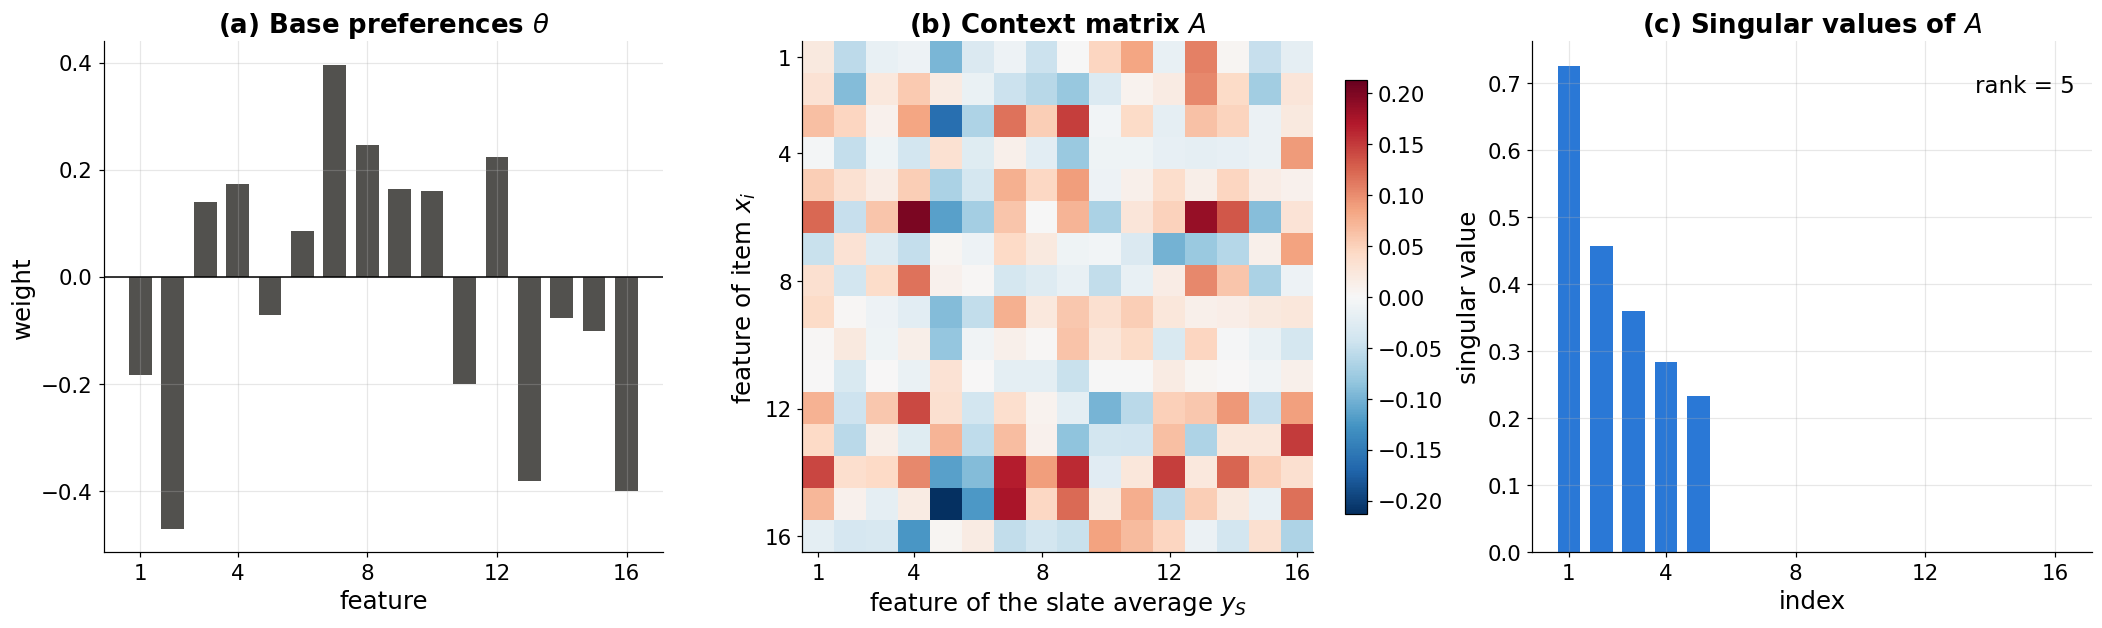

saved ./figures/ch3_data_ground_truth.pdf


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5.6), gridspec_kw=dict(width_ratios=[1.1, 1.25, 1.1]))
ax[0].bar(np.arange(1, D + 1), theta, color="#52514e", width=0.7)
ax[0].axhline(0, color="black", lw=1)
ax[0].set(title=r"(a) Base preferences $\theta$", xlabel="feature", ylabel="weight", xticks=[1, 4, 8, 12, 16])
v = np.abs(A).max()
im = ax[1].imshow(A, cmap="RdBu_r", vmin=-v, vmax=v)
ax[1].set(title=r"(b) Context matrix $A$", xlabel="feature of the slate average $y_S$", ylabel="feature of item $x_i$")
ax[1].set_xticks([0, 3, 7, 11, 15], [1, 4, 8, 12, 16]); ax[1].set_yticks([0, 3, 7, 11, 15], [1, 4, 8, 12, 16])
ax[1].grid(False); fig.colorbar(im, ax=ax[1], shrink=0.85)
s = np.linalg.svd(A, compute_uv=False)
ax[2].bar(np.arange(1, D + 1), s, color="#2a78d6", width=0.7)
ax[2].set(title=r"(c) Singular values of $A$", xlabel="index", ylabel="singular value", xticks=[1, 4, 8, 12, 16])
ax[2].text(0.97, 0.9, f"rank = {np.sum(s > 1e-9)}", transform=ax[2].transAxes, ha="right", fontsize=15)
save(fig, "ch3_data_ground_truth")


**How to read it.** (a) The 16 weights of $\theta$: how much each feature is worth on its own, whatever else is on the slate.
(b) The context matrix $A$. Red is positive, blue is negative. Entry $(k, l)$ says how a high slate average of feature $l$
raises (red) or lowers (blue) the value of feature $k$ in an item.
(c) The singular values of $A$.

**What it shows.** $A$ is built from 5 hidden directions, so exactly 5 singular values are non-zero (rank 5).
$\theta$ and $A$ both have size 1, so neither part dominates by construction.
This figure is **Figure A.1 in Appendix A**. This $A$ is the target the probe has to recover (Section 3.6 and Chapter 4).


In [ ]:
# Numbers quoted in Chapter 3, Section 3.2.2 (no figure is saved here any more)
u_base = X @ theta                                         # theta^T x_i           (sessions x items)
u_ctx = np.einsum("nsd,dk,nk->ns", X, A, X.mean(axis=1))  # x_i^T A y_S
P_mnl = np.exp(u_base - u_base.max(1, keepdims=True)); P_mnl /= P_mnl.sum(1, keepdims=True)

cnt = np.bincount(Y, minlength=5) / len(Y)
print("share of choices per slate position (%):", np.round(100 * cnt, 2), "-> min %.1f, max %.1f" % (100 * cnt.min(), 100 * cnt.max()))
print("sd of base part %.3f | sd of context part %.3f" % (u_base.std(), u_ctx.std()))
flip = (P.argmax(1) != P_mnl.argmax(1)).mean()
tv = 0.5 * np.abs(P - P_mnl).sum(1)
print("switching the context off changes the most likely item in %.1f%% of sessions" % (100 * flip))
print("change in choice probabilities (total variation): median %.3f (= %.1f percentage points), mean %.3f" % (np.median(tv), 100 * np.median(tv), tv.mean()))
pmax = P.max(axis=1)
print("probability of the true most likely item: quartiles", np.round(np.quantile(pmax, [0.25, 0.5, 0.75]), 3),
      "| 5%-95%:", np.round(np.quantile(pmax, [0.05, 0.95]), 3), "| share above 0.8: %.1f%%" % (100 * (pmax > 0.8).mean()))


share of choices per slate position (%): [19.9  19.85 20.15 20.09 20.01] -> min 19.8, max 20.1
sd of base part 1.001 | sd of context part 0.443
switching the context off changes the most likely item in 23.5% of sessions
change in choice probabilities (total variation): median 0.108 (= 10.8 percentage points), mean 0.125
probability of the true most likely item: quartiles [0.374 0.455 0.569] | 5%-95%: [0.297 0.761] | share above 0.8: 3.1%


**What this cell prints (all quoted in Section 3.2.2).**
Each slate position gets about 20% of the choices (no position bias, because items are placed in random order).
The base part of the utility has spread 1.0 and the context part 0.44.
Switching the context off changes the most likely item in about 23% of the sessions, and the median change of choice probabilities is about 11 percentage points.
Choices are genuinely random: in half of the sessions the true most likely item has probability between about 0.37 and 0.57.


In [ ]:
# The four reference losses of Section 3.2.2 (all computed from the stored true probabilities P of seed 101)
H_true = -(P * np.log(P)).sum(1).mean()                 # mean entropy of P: best possible loss
CE_mnl = -(P * np.log(P_mnl)).sum(1).mean()             # cross-entropy of P against Q (true theta, context switched off)
print(f"random guessing loss  log 5          = {np.log(5):.4f}")
print(f"right theta, context ignored (MNL)   = {CE_mnl:.4f}")
print(f"true model (best possible)           = {H_true:.4f}")
print(f"=> knowing the context is worth {CE_mnl - H_true:.4f} nats per choice; all model gaps are read against this")


random guessing loss  log 5          = 1.6094
right theta, context ignored (MNL)   = 1.3264
true model (best possible)           = 1.2654
=> knowing the context is worth 0.0611 nats per choice; all model gaps are read against this


**The yardstick used in the rest of the report** (printed above): random guessing has loss 1.609.
The right $\theta$ with context ignored has loss 1.326 (a formula on the stored $P$; nothing is trained).
The true model has loss 1.265 (the mean entropy of $P$). So **knowing the context is worth about 0.061 nats per choice**.
A model whose test loss is 0.061 above the true loss has learned nothing about context; one at 0 has learned all of it.


---
## 3.3 Models

All models output one score $s_i$ per item and are trained with the softmax over the slate, exactly like LCL.
Self-attention, mean-pool and the flat MLP are matched to about the **same number of parameters** (about 9,200 at $d = 16$),
so differences between them are about structure, not size.

| model | name in code | how it scores item $i$ | knows the slate is a set? |
|---|---|---|---|
| **Oracle** (Table 3.2) | `oracle` | the LCL formula itself, with free $\theta$ and $A$ | yes |
| **Bilinear attention** (Table 3.2) | `bil_h{h}` | $w^\top x_i + \frac15 \sum_j (W_q x_i)^\top (W_k x_j)$. This **is** the LCL with $A = W_q^\top W_k$ (rank at most $h$) | yes |
| **Softmax attention head** (Table 3.2) | `sov_h{h}` | $w^\top x_i + (W_o x_i)^\top \sum_j \alpha_{ij} W_v x_j$. It **can represent** the LCL ($A = W_o^\top W_v$) when all $\alpha_{ij} = 1/5$; in training the weights are free | yes |
| **Self-attention (transformer)** | `sa_L{L}` | embed each item in 32 dimensions, $L$ transformer encoder layers (2 heads, pre-LayerNorm, feed-forward width 64, **no dropout**, no positional encoding), then a linear read-out | yes |
| **Mean-pool network** | `mp_L{L}` | an MLP on $[x_i,\ y_S]$ (32 inputs), applied to each item | yes |
| **Flat MLP** | `flat_L{L}` | an MLP on the concatenated slate (80 inputs), 5 outputs | **no** |
| **Flat MLP, wide** | `flatw_L{L}` | as above, but keeps the width of the 2-layer version | **no** |

**Depth sweep is not size-matched for all families** (Table 3.1): the flat MLP is re-matched to about 9,200 parameters at every depth (it gets narrower);
self-attention, mean-pool and the wide flat MLP keep their width and grow.


In [ ]:
rows_ = []
for m in ["oracle", "bil_h16", "sov_h16", "sa_L1", "sa_L2", "sa_L4", "sa_L6", "mp_L2", "mp_L4", "mp_L6",
          "flat_L2", "flat_L4", "flat_L6", "flatw_L4", "flatw_L6"]:
    net = L.build_model(m, 16)
    rows_.append(dict(model=m, description=label(m), parameters=L.n_params(net),
                      tuned_lr=HP[L.family(m)]["lr"], tuned_weight_decay=HP[L.family(m)]["wd"]))
print("Models at the reference setting (d = 16):")
print(pd.DataFrame(rows_).set_index("model").to_string())


Models at the reference setting (d = 16):
                        description  parameters  tuned_lr  tuned_weight_decay
model                                                                        
oracle        Oracle (true formula)         272     0.030              0.0001
bil_h16   Bilinear attention (h=16)         528     0.030              0.0000
sov_h16         Softmax head (h=16)        1040     0.030              0.0001
sa_L1      Self-attention (1 layer)        9185     0.030              0.0001
sa_L2     Self-attention (2 layers)       17729     0.030              0.0001
sa_L4     Self-attention (4 layers)       34817     0.010              0.0000
sa_L6     Self-attention (6 layers)       51905     0.030              0.0001
mp_L2          Mean-pool (2 layers)        9201     0.010              0.0000
mp_L4          Mean-pool (4 layers)       22161     0.010              0.0000
mp_L6          Mean-pool (6 layers)       35121     0.010              0.0000
flat_L2         Flat M

In [ ]:
# Table 3.2 of the thesis: oracle, bilinear attention and softmax head, mean over the 30 headline datasets (printed as LaTeX rows)
E1_ = R[(R.exp == "E1_headline") & (R.world == "context")].copy()
ref_ = E1_[E1_.model == "oracle"].set_index("seed")["nll_in"]
E1_["excess_nll"] = E1_["nll_in"] - E1_["seed"].map(ref_)
for m, nm in [("oracle", "Oracle LCL"), ("bil_h16", "Bilinear, $h=16$"), ("sov_h16", "Softmax head, $h=16$")]:
    d_ = E1_[E1_.model == m]
    print(f"{nm:22s} & {L.n_params(L.build_model(m, 16)):,} & {d_.rel_frob.mean():.3f} & {d_.theta_relerr.mean():.3f} & "
          f"{1000 * d_.excess_nll.mean():.2f} & {1000 * d_.kl_in.mean():.2f} \\\\")
print("\ncolumns: parameters, error in A, error in theta, excess NLL (x1e-3 nats), KL (x1e-3)")
print("datasets per model:", E1_.groupby("model").seed.nunique()[["oracle", "bil_h16", "sov_h16"]].to_dict())


Oracle LCL             & 272 & 0.092 & 0.020 & 0.00 & 0.69 \\
Bilinear, $h=16$       & 528 & 0.088 & 0.022 & -0.05 & 0.68 \\
Softmax head, $h=16$   & 1,040 & 0.091 & 0.025 & 0.28 & 1.11 \\

columns: parameters, error in A, error in theta, excess NLL (x1e-3 nats), KL (x1e-3)
datasets per model: {'oracle': 30, 'bil_h16': 30, 'sov_h16': 30}


**What it shows.** The three models marked in Table 3.1 (self-attention 1 layer, mean-pool 2 layers, flat MLP 2 layers) have about 9,200 parameters,
so comparisons between them are fair in size. Table 3.2 (printed above) gives the oracle, bilinear attention and the softmax head: both heads are
at or very close to the oracle in prediction and recovery, so the data floor for the error in $\hat A$ is about 0.09 for a model with the right form.
The learning rate and weight decay printed in the first table are the ones chosen by the tuning in Section 3.4.


---
## 3.4 Training and hyperparameters

**Every model is trained the same way** (`lcl_core.train_model`):
* Loss: negative log-likelihood of the chosen item (cross-entropy over the slate).
* Optimiser: AdamW, constant learning rate, **full batch** (the exact gradient over all training sessions every step; one epoch = one update).
* At most 500 epochs. **Early stopping**: keep the epoch with the lowest validation loss, and stop after 60 epochs without improvement.
* Nothing about $A$ or $\theta$ is used in training or model selection; only the validation loss.

**Tuning** (the `tune` stage): for each model, every combination of learning rate $\{0.003, 0.01, 0.03\}$ and
weight decay $\{0, 0.0001\}$, on 2 datasets at the reference setting. The combination with the lowest average **validation loss** is kept
and used in every experiment. Experiment E7 (Chapter 4) then checks that the conclusions about $A$ do not depend on this choice.


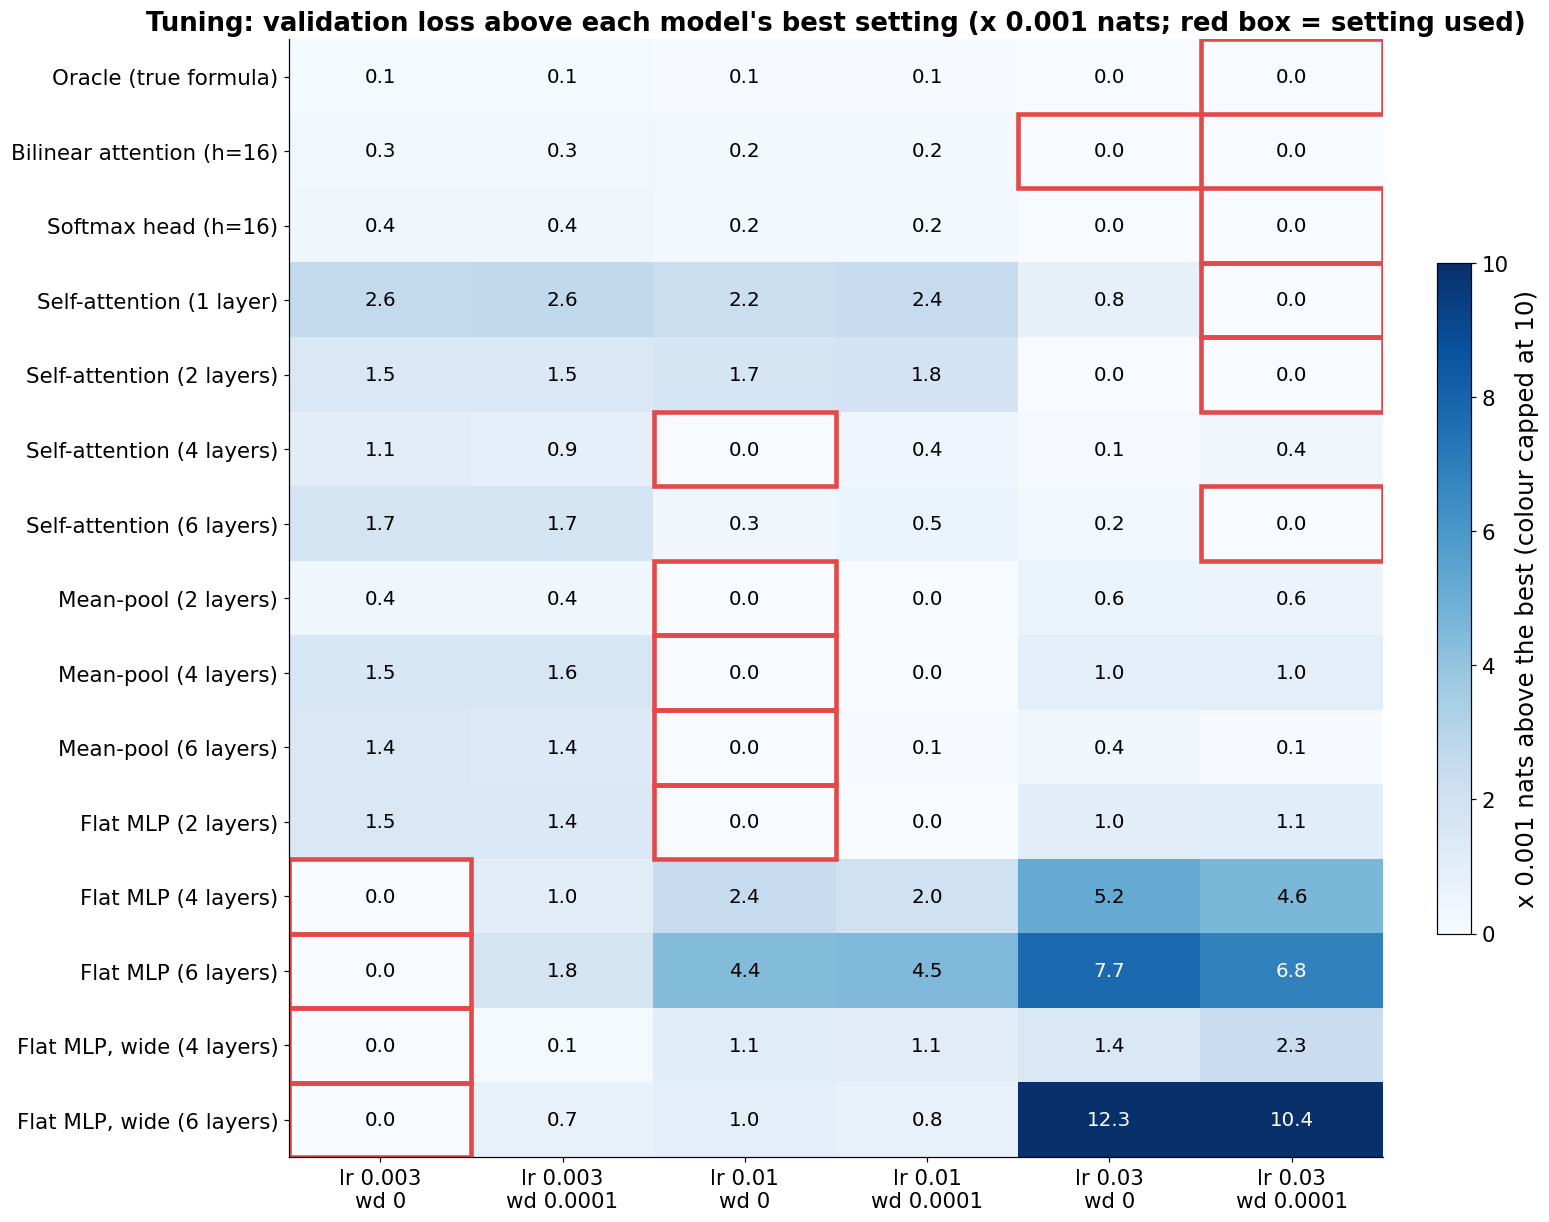

saved ./figures/ch3_tuning.pdf
validation loss of the chosen setting, and the spread over the grid:
          best val loss  worst minus best (x0.001)
model                                             
oracle           1.2708                        0.1
bil_h16          1.2706                        0.3
sov_h16          1.2711                        0.4
sa_L1            1.2729                        2.6
sa_L2            1.2746                        1.8
sa_L4            1.2742                        1.1
sa_L6            1.2736                        1.7
mp_L2            1.2745                        0.6
mp_L4            1.2746                        1.6
mp_L6            1.2750                        1.4
flat_L2          1.2930                        1.5
flat_L4          1.2935                        5.2
flat_L6          1.2922                        7.7
flatw_L4         1.2942                        2.3
flatw_L6         1.2958                       12.3

largest 'worst minus best' per g

In [ ]:
TU = TUNE.copy()
TU["combo"] = TU.apply(lambda r: f"lr {r.lr:g}\nwd {r.wd:g}", axis=1)
combos = [f"lr {lr:g}\nwd {wd:g}" for lr in [0.003, 0.01, 0.03] for wd in [0.0, 0.0001]]
order_t = ["oracle", "bil_h16", "sov_h16", "sa_L1", "sa_L2", "sa_L4", "sa_L6", "mp_L2", "mp_L4", "mp_L6",
           "flat_L2", "flat_L4", "flat_L6", "flatw_L4", "flatw_L6"]
G = TU.pivot_table(index="model", columns="combo", values="val_nll", aggfunc="mean").loc[order_t, combos]
Gd = 1000 * (G.sub(G.min(axis=1), axis=0))                      # in units of 0.001 nats above the model's best
fig, ax = plt.subplots(figsize=(14, 11))
im = ax.imshow(Gd.values, cmap="Blues", vmin=0, vmax=10, aspect="auto")
for i, m in enumerate(order_t):
    for j, c in enumerate(combos):
        v_ = Gd.values[i, j]
        ax.text(j, i, f"{v_:.1f}", ha="center", va="center", fontsize=13, color="white" if v_ > 6 else "black")
    h = HP[L.family(m)]; j = combos.index(f"lr {h['lr']:g}\nwd {h['wd']:g}")
    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="#e34948", lw=3))
ax.set_xticks(range(len(combos)), combos); ax.set_yticks(range(len(order_t)), [label(m) for m in order_t]); ax.grid(False)
ax.set_title("Tuning: validation loss above each model's best setting (x 0.001 nats; red box = setting used)")
fig.colorbar(im, ax=ax, shrink=0.6, label="x 0.001 nats above the best (colour capped at 10)")
save(fig, "ch3_tuning")            # Appendix A, Figure A.2
print("validation loss of the chosen setting, and the spread over the grid:")
print(pd.DataFrame({"best val loss": G.min(axis=1).round(4), "worst minus best (x0.001)": Gd.max(axis=1).round(1)}).to_string())

# numbers quoted in Chapter 3, Section 3.4 ('Tuning') and Appendix A
fams_ = {"oracle / bilinear / softmax head": ["oracle", "bil_h16", "sov_h16"], "self-attention": ["sa_L1", "sa_L2", "sa_L4", "sa_L6"],
         "mean-pool": ["mp_L2", "mp_L4", "mp_L6"], "flat MLP": ["flat_L2", "flat_L4", "flat_L6"], "wide flat MLP": ["flatw_L4", "flatw_L6"]}
print("\nlargest 'worst minus best' per group (nats):")
for k, v in fams_.items(): print(f"  {k:36s} {Gd.loc[v].values.max() / 1000:.4f}")
print("flat_L2 best val loss minus sa_L1 best val loss: %.4f" % (G.min(axis=1)["flat_L2"] - G.min(axis=1)["sa_L1"]))
print("\nchosen learning rate and weight decay (Table A.1):")
print(pd.DataFrame({m: dict(lr=HP[L.family(m)]["lr"], wd=HP[L.family(m)]["wd"]) for m in order_t}).T.to_string())


**How to read it.** One row per model, one column per learning rate and weight decay combination. Each number is the validation loss
of that setting minus the best setting *for that model*, in thousandths of a nat (0 = the best setting). Each cell averages 2 datasets.
The red box is the setting used in all experiments.

**What it shows.**
* **The results do not hinge on tuning.** For the attention models, self-attention and mean-pool, the worst setting in the grid is at most
  about 0.003 nats worse than the best. That is small next to the gaps between models: the flat MLP's best setting is about 0.02 nats worse
  than self-attention's best (table above).
* **The flat MLPs are the most sensitive**, especially when deep: up to 0.008 (6 layers) and 0.012 (6 layers, wide) between settings.
  Deep flat MLPs prefer the smallest learning rate.
* **Several models chose the largest learning rate (0.03),** the edge of the grid. Because the loss changes so little across the grid,
  a larger value would not change the conclusions. the E7 sweep in Chapter 4 checks this directly on the recovery of $A$.


---
## 3.6 Evaluation metrics and the behavioural probe

Good predictions do not prove that a model learned the *right rule*. The probe reads the rule out of the trained network,
using only its outputs (it never looks at the weights), so it works the same way for every architecture.

**Idea.** Take two items $a$ and $b$ and keep them fixed. Fill the other 3 slots with random items, many times (500).
If the model behaves like LCL, its score difference is
$$s_a - s_b = \theta^\top \delta + \delta^\top A\, y_S, \qquad \delta = x_a - x_b,$$
a straight line in the slate average $y_S$ with slope $\delta^\top A$.
1. **$\hat A$**: for each of $K = 10d = 160$ random pairs, centre the score differences within the pair, then solve one joint least-squares
   problem over all pairs for the $d \times d$ matrix $\hat A$. The centring removes anything that does not depend on the other items,
   so a context-free model, however nonlinear, gives $\hat A = 0$.
2. **$\hat\theta$**: with $\hat A$ known, the average gap of each pair gives $\delta^\top\theta$; least squares over the pairs gives $\hat\theta$.
3. **Uncertainty**: bootstrap over the pairs (200 resamples) gives confidence intervals.

**Measures used in the results:**
* **Error in A**: $\lVert \hat A - A\rVert / \lVert A\rVert$. 0 is perfect; 1 is no better than $\hat A = 0$.
* **Direction**: cosine between $\hat A$ and $A$ (1 = same pattern). **Size**: $\lVert\hat A\rVert / \lVert A\rVert$ (1 = right strength).
* **Fidelity**: the share of the model's context behaviour that the straight-line form explains (1 = entirely LCL-shaped).
* **Metric C**: take the same pair $a, b$ on two different random slates. Regress how much the model's preference between them changes
  on how much it *should* change under the true $A$. A slope of 1 means the model reacts to the slate exactly as much as the truth.
* **Invariance**: $\hat A$ read on usual slates vs on unusual slates. 0 means the model uses the same rule everywhere.

**Checking the probe before trusting it.** In the pilot stage the probe was run on four functions whose answer is known,
at 6 to 32 features (same code as for the trained models):
* **V1** the generator's own score function (true answer: $A$ and $\theta$ exactly);
* **V2** a hand-built bilinear attention layer with weights set from the SVD of $A$ (true answer: $A$, $\theta$);
* **V0** a context-free but nonlinear function, $\theta^\top x_i + \sum_k \sin(x_{ik})$ (true answer: $\hat A = 0$);
* **V4** a saturating, non-LCL context effect, $\theta^\top x_i + 0.5\tanh(2\,x_i^\top A y_S)$ (should be flagged as not LCL-shaped).


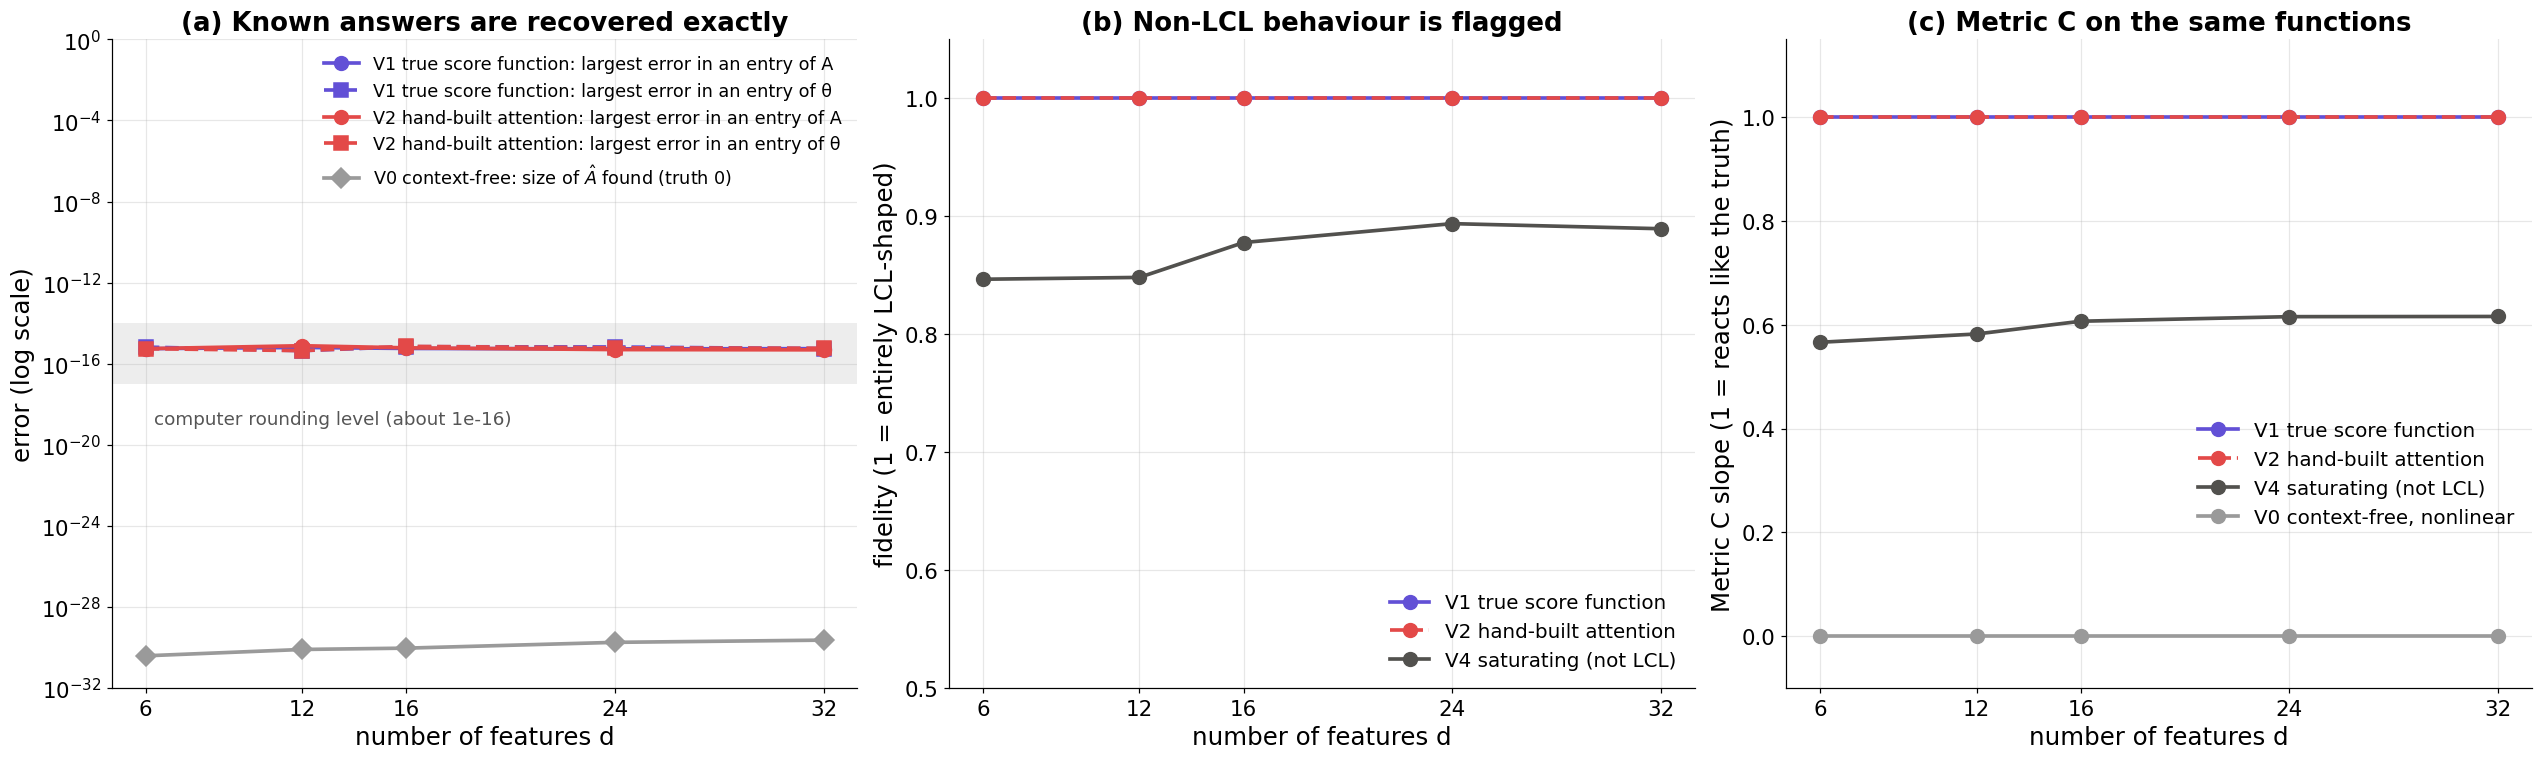

saved ./figures/extra_probe_checks.pdf
short  d    max_err_A  max_err_theta      fro_hat    fid_A  c_slope
   V0  6 5.360938e-01   7.712277e-01 3.954955e-31      NaN 0.000000
   V0 12 2.576883e-01   6.923746e-01 8.131673e-31      NaN 0.000000
   V0 16 2.373472e-01   7.587218e-01 9.448654e-31      NaN 0.000000
   V0 24 1.499127e-01   7.114836e-01 1.824421e-30      NaN 0.000000
   V0 32 1.136552e-01   7.807435e-01 2.345108e-30      NaN 0.000000
   V1  6 5.551115e-16   6.661338e-16 1.000000e+00 1.000000 1.000000
   V1 12 6.383782e-16   4.440892e-16 1.000000e+00 1.000000 1.000000
   V1 16 5.689893e-16   6.938894e-16 1.000000e+00 1.000000 1.000000
   V1 24 5.438358e-16   6.748074e-16 1.000000e+00 1.000000 1.000000
   V1 32 5.551115e-16   5.551115e-16 1.000000e+00 1.000000 1.000000
   V2  6 5.551115e-16   5.551115e-16 1.000000e+00 1.000000 1.000000
   V2 12 7.771561e-16   4.440892e-16 1.000000e+00 1.000000 1.000000
   V2 16 6.106227e-16   7.216450e-16 1.000000e+00 1.000000 1.000000
   V2 24 

In [ ]:
LD = PILOT[PILOT.rung.notna()].copy()
LD["short"] = LD.rung.str.split(" ").str[0]
PC = {"V1": "#6250d6", "V2": "#e34948", "V0": "#9a9a9a", "V4": "#52514e"}
NAMES = {"V1": "V1 true score function", "V2": "V2 hand-built attention", "V0": "V0 context-free, nonlinear", "V4": "V4 saturating (not LCL)"}
dd = sorted(LD.d.unique())
fig, ax = plt.subplots(1, 3, figsize=(23, 6.8))
for k in ["V1", "V2"]:
    g = LD[LD.short == k].set_index("d").loc[dd]
    ax[0].plot(dd, g.max_err_A, marker="o", color=PC[k], label=f"{NAMES[k]}: largest error in an entry of A")
    ax[0].plot(dd, g.max_err_theta, marker="s", ls="--", color=PC[k], label=f"{NAMES[k]}: largest error in an entry of θ")
g = LD[LD.short == "V0"].set_index("d").loc[dd]
ax[0].plot(dd, g.fro_hat, marker="D", color=PC["V0"], label=r"V0 context-free: size of $\hat A$ found (truth 0)")
ax[0].axhspan(1e-17, 1e-14, color="#dddddd", alpha=0.5, lw=0); ax[0].text(6.3, 1e-19, "computer rounding level (about 1e-16)", fontsize=12, color="#555")
ax[0].set(yscale="log", ylim=(1e-32, 1), xticks=dd, xlabel="number of features d", ylabel="error (log scale)",
          title="(a) Known answers are recovered exactly")
ax[0].legend(loc="upper right", fontsize=11.5)
for k in ["V1", "V2", "V4"]:
    g = LD[LD.short == k].set_index("d").loc[dd]
    ax[1].plot(dd, g.fid_A, marker="o", color=PC[k], label=NAMES[k], ls="--" if k == "V2" else "-")
ax[1].set(ylim=(0.5, 1.05), xticks=dd, xlabel="number of features d", ylabel="fidelity (1 = entirely LCL-shaped)",
          title="(b) Non-LCL behaviour is flagged")
ax[1].legend(loc="lower right")
for k in ["V1", "V2", "V4", "V0"]:
    g = LD[LD.short == k].set_index("d").loc[dd]
    ax[2].plot(dd, g.c_slope, marker="o", color=PC[k], label=NAMES[k], ls="--" if k == "V2" else "-")
ax[2].set(ylim=(-0.1, 1.15), xticks=dd, xlabel="number of features d", ylabel="Metric C slope (1 = reacts like the truth)",
          title="(c) Metric C on the same functions")
ax[2].legend(loc="center right", bbox_to_anchor=(1.0, 0.33))
save(fig, "extra_probe_checks")          # NOT in the thesis any more: Chapter 3 quotes the ranges printed below
print(LD.sort_values(["short", "d"])[["short", "d", "max_err_A", "max_err_theta", "fro_hat", "fid_A", "c_slope"]].to_string(index=False))

# ranges quoted in Chapter 3, 'Checking the probe'
for k in ["V1", "V2"]:
    g = LD[LD.short == k]
    print(f"{k}: largest entry error in A {g.max_err_A.max():.2e}, in theta {g.max_err_theta.max():.2e}")
g = LD[LD.short == "V0"]; print(f"V0: size of A_hat from {g.fro_hat.min():.2e} to {g.fro_hat.max():.2e}")
g = LD[LD.short == "V4"]; print(f"V4: fidelity {g.fid_A.min():.3f} to {g.fid_A.max():.3f}, Metric C slope {g.c_slope.min():.3f} to {g.c_slope.max():.3f}")
print("probe checks run at d =", sorted(LD.d.unique()))


**How to read it.** (a) Log scale. For V1 and V2, the largest error in any single entry of $\hat A$ and $\hat\theta$ against the true values.
For V0, the size of the $\hat A$ the probe reports, where the truth is 0. The grey band is the rounding level of the computer
(about $10^{-16}$): nothing can be more exact than that. (b) Fidelity for V1, V2 and V4. (c) Metric C slope for all four.

**What it shows.**
* **The probe is exact when the answer is known.** For the generator's own score function (V1) and for a hand-built attention layer (V2),
  every entry of $\hat A$ and $\hat\theta$ matches the truth to the computer's rounding level (about $10^{-16}$), at every size from 6 to 32 features.
  So the probe reads attention correctly, and the large-$d$ memory-light version is exact as well.
* **It does not invent context.** For a context-free but strongly nonlinear function (V0) it reports $\hat A$ of size about $10^{-30}$, which is exactly zero.
  Nonlinearity alone does not create a false context effect, thanks to the centring within each pair.
* **It flags non-LCL behaviour.** For the saturating context effect (V4), fidelity drops to 0.85 to 0.89 and the Metric C slope to about 0.6.
  The trained networks in Chapter 4 can be read the same way: fidelity below 1 means "partly not LCL-shaped".

*(In the thesis this is now a short paragraph with the ranges printed above; the figure is kept here as an extra.)*


---
# Chapter 4: Results


---
## 4.1 Training behaviour

The main runs only stored final numbers. `curves.py` (run on the cluster) trains **one copy of every model** on the seed-101 dataset of Section 1,
with exactly the protocol of Section 3 and the tuned settings, and records the train and validation loss after every epoch.
This notebook only reads the result (`curves.json`).

The reference lines are the **true model's loss on the same data**: the level a perfect model would reach (apart from noise).


In [ ]:
curves = {k: v for k, v in CURVES.items() if not k.startswith("_")}
truth_ = CURVES["_truth"]
floor_tr, floor_va = truth_["floor_train"], truth_["floor_val"]
truth_test = dict(test_nll=truth_["test_nll"], accuracy=truth_["accuracy"], expected_accuracy=truth_["expected_accuracy"])
CURVE_MODELS = ["oracle", "sa_L1", "mp_L2", "flat_L2"]      # bilinear / softmax head: Chapter 3 only
print("models in curves.json:", ", ".join(curves))
print(f"true model: train loss {floor_tr:.4f} | validation loss {floor_va:.4f}")


models in curves.json: sa_L6, sa_L4, sa_L2, sa_L1, mp_L6, mp_L4, mp_L2, flat_L6, flat_L4, flat_L2, sov_h16, bil_h16, oracle
true model: train loss 1.2640 | validation loss 1.2583


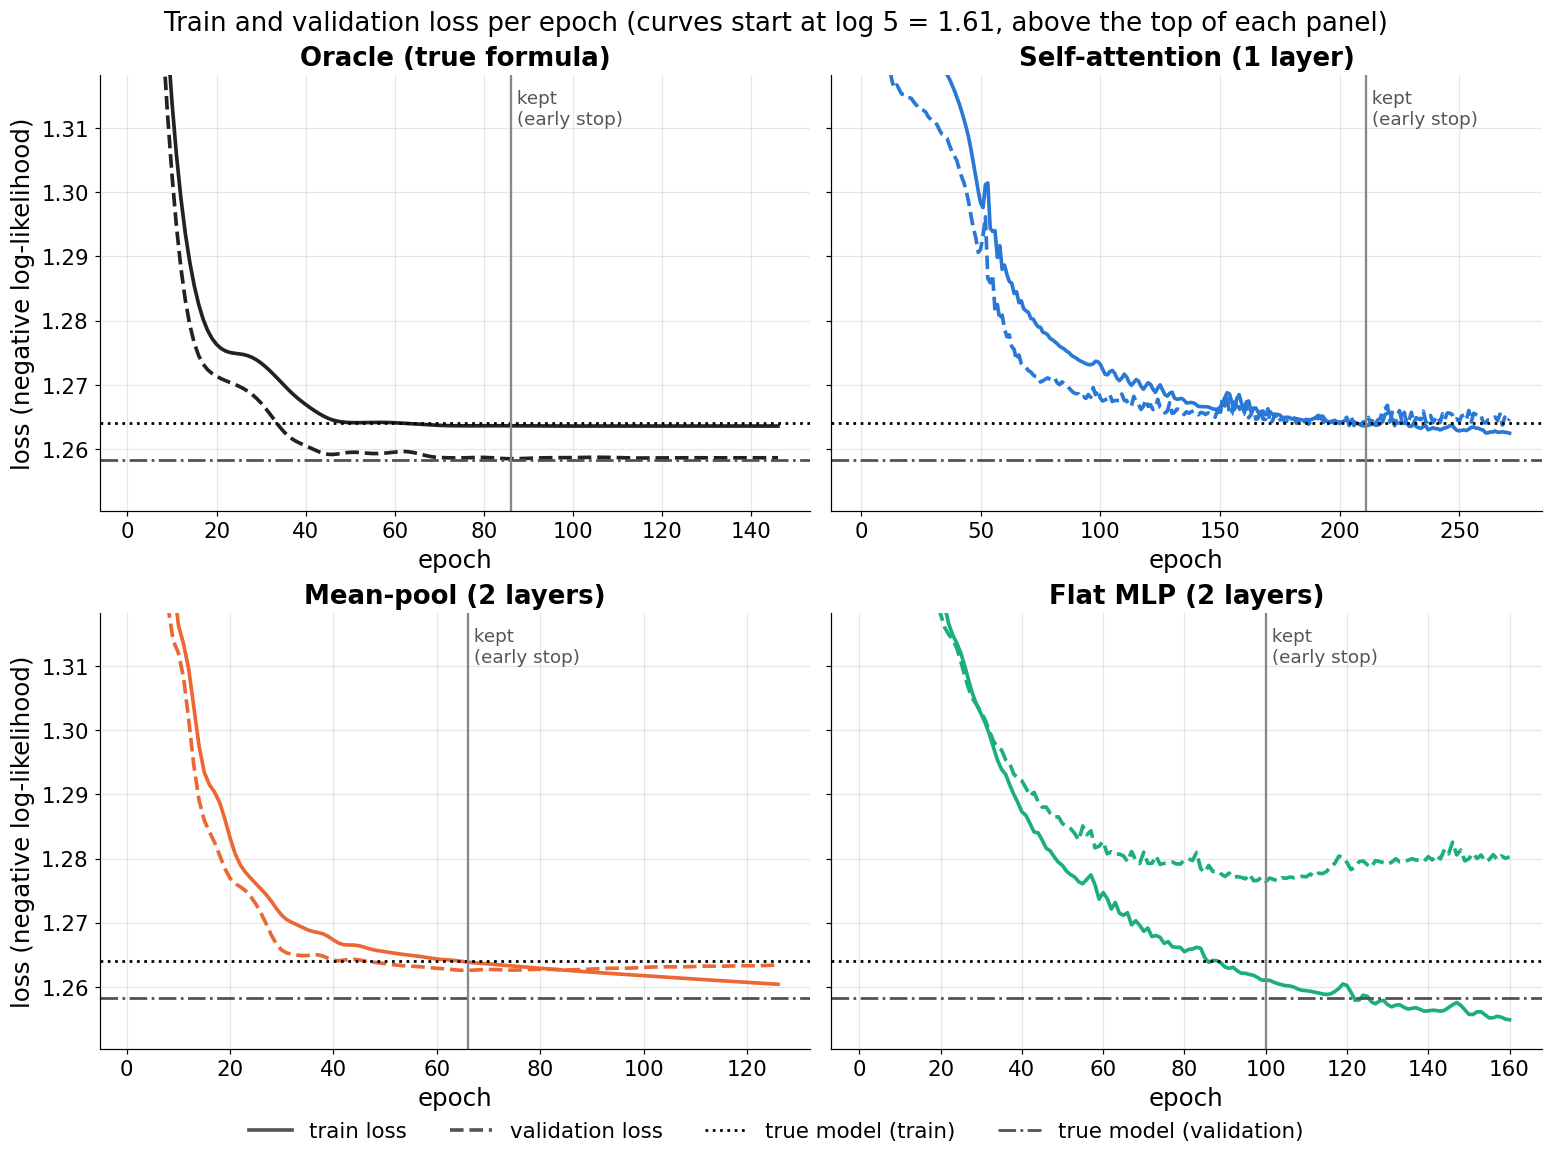

saved ./figures/ch4_training_curves.pdf


In [ ]:
ms = [m for m in CURVE_MODELS if m in curves]
fig, axs = plt.subplots(2, 2, figsize=(14, 10.5), sharey=True)
for ax, m in zip(axs.ravel(), ms):
    c = curves[m]; ep = np.arange(1, len(c["hist"]["val"]) + 1)
    ax.plot(ep, c["hist"]["train"], color=col(m), lw=2.4, label="train loss")
    ax.plot(ep, c["hist"]["val"], color=col(m), lw=2.4, ls="--", label="validation loss")
    ax.axhline(floor_tr, color="black", ls=":", lw=1.8, label="true model (train)")
    ax.axhline(floor_va, color="#52514e", ls="-.", lw=1.8, label="true model (validation)")
    ax.axvline(c["best_ep"] + 1, color="#888888", lw=1.5)
    ax.text(c["best_ep"] + 1, floor_tr + 0.052, " kept\n (early stop)", fontsize=12, color="#555555", va="top")
    ax.set(title=label(m), xlabel="epoch")
    ax.set_ylim(min(floor_tr, floor_va) - 0.008, min(floor_tr, floor_va) + 0.06)
for ax in axs[:, 0]: ax.set_ylabel("loss (negative log-likelihood)")
fig.suptitle("Train and validation loss per epoch (curves start at log 5 = 1.61, above the top of each panel)", fontsize=17)
h_, l_ = axs[0, 0].get_legend_handles_labels()
fig.legend([Line2D([], [], color="#555", lw=2.4), Line2D([], [], color="#555", lw=2.4, ls="--")] + h_[2:],
           ["train loss", "validation loss"] + l_[2:], loc="outside lower center", ncol=4, fontsize=14)
save(fig, "ch4_training_curves")


**How to read it.** One panel per model, all trained on the same data (seed 101). Solid line: training loss. Dashed line: validation loss.
Dotted and dash-dot lines: the true model's loss on the same training and validation data, the level a perfect model would sit at, apart from noise.
The grey vertical line marks the epoch that early stopping keeps. All panels share the same zoomed vertical scale
(every curve starts at $\log 5 = 1.61$, above the top of the panel).

**What to look for (check against YOUR cluster `curves.json`, do not copy numbers from an earlier draft).**
* Does every model train smoothly and stop before the 500-epoch limit? (The tables printed by the next two cells give epochs and kept epoch.)
* The **oracle** should settle on the true model's lines. **Self-attention and mean-pool** should settle just above them, with train and validation close together.
* The **flat MLP**: does its training loss drop below the true model's line while validation stalls above it (overfitting)?
* Self-attention at learning rate 0.03: are there small loss bumps (full-batch Adam at a large rate)?


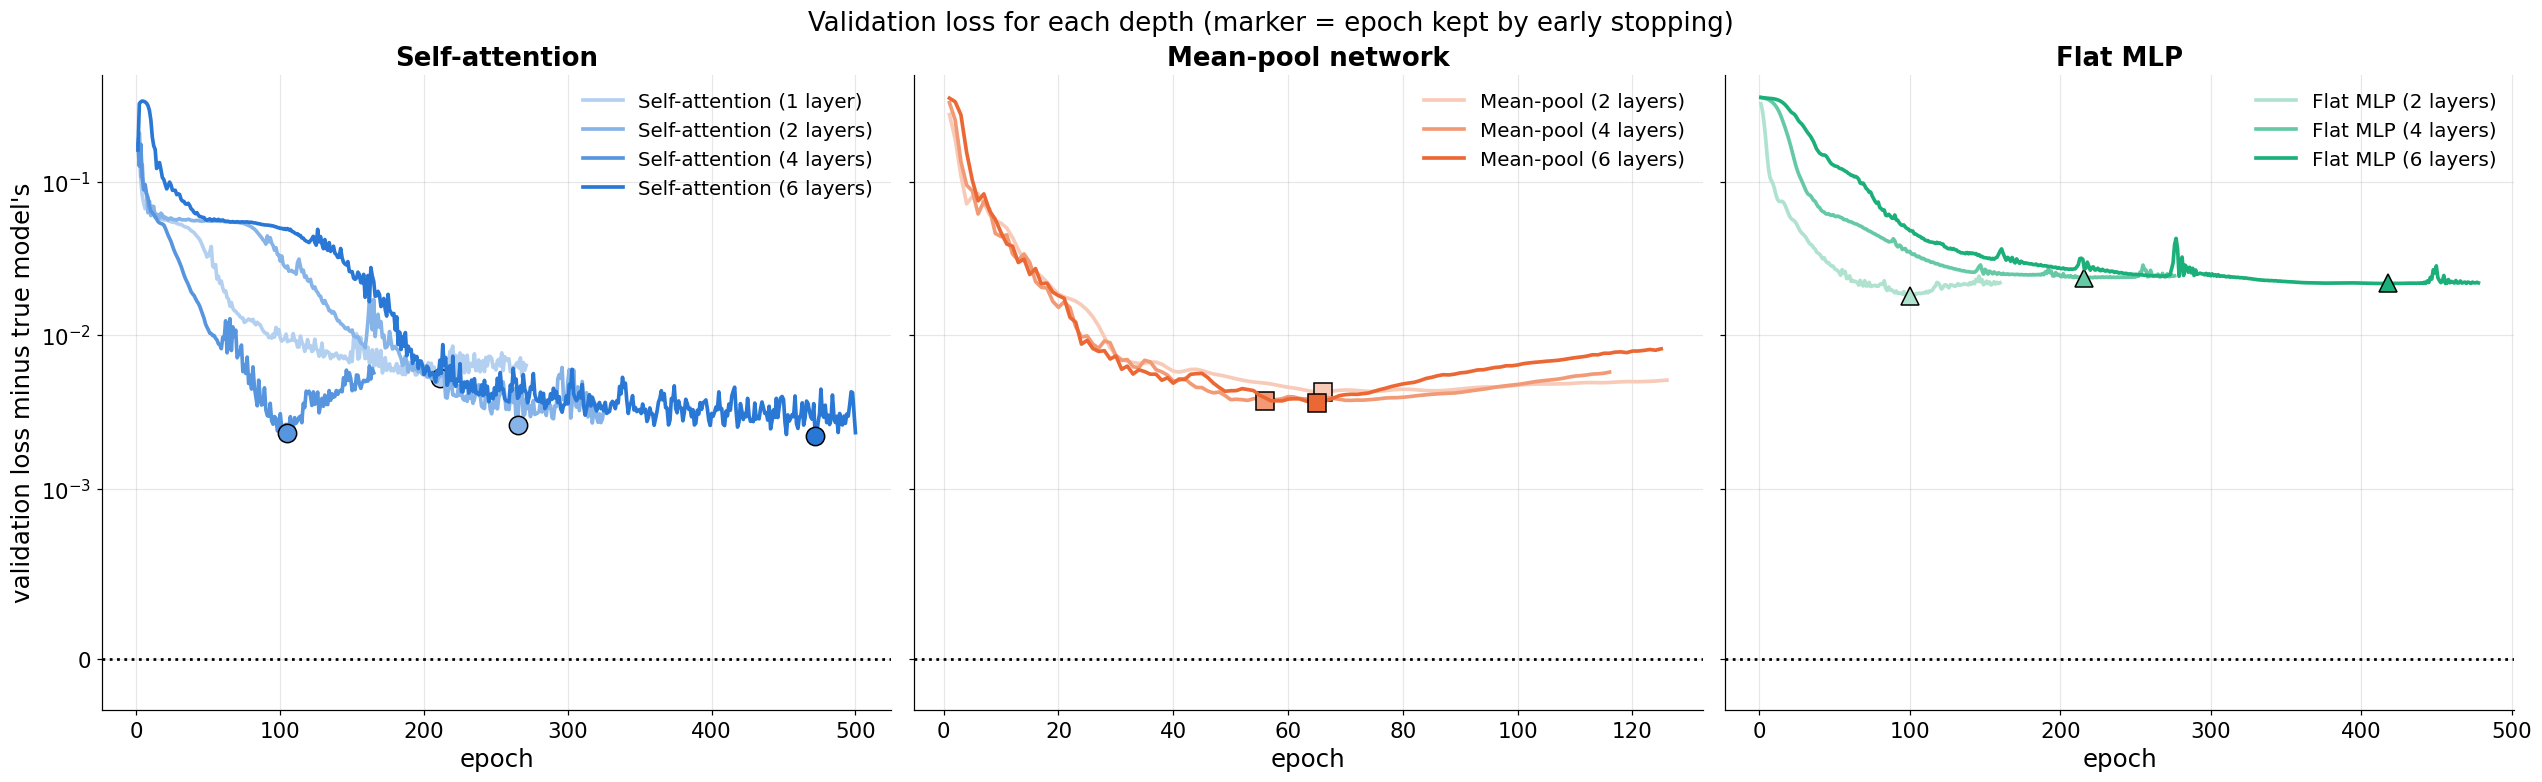

saved ./figures/ch4_training_curves_depth.pdf
         epochs  kept_epoch  final_gap
sa_L1     271.0       211.0     0.0052
sa_L2     325.0       265.0     0.0026
sa_L4     165.0       105.0     0.0023
sa_L6     500.0       472.0     0.0022
mp_L2     126.0        66.0     0.0043
mp_L4     116.0        56.0     0.0037
mp_L6     125.0        65.0     0.0036
flat_L2   160.0       100.0     0.0181
flat_L4   276.0       216.0     0.0236
flat_L6   478.0       418.0     0.0217


In [ ]:
DEPTHS = {"sa": ["sa_L1", "sa_L2", "sa_L4", "sa_L6"], "mp": ["mp_L2", "mp_L4", "mp_L6"], "flat": ["flat_L2", "flat_L4", "flat_L6"]}
def shade(c, t):            # t = 0 light ... 1 full colour
    c = np.array(mpl.colors.to_rgb(c)); return tuple(1 - (1 - c) * (0.35 + 0.65 * t))
fig, axs = plt.subplots(1, 3, figsize=(23, 7), sharey=True)
for ax, (f, ms_) in zip(axs, DEPTHS.items()):
    ms_ = [m for m in ms_ if m in curves]
    for k, m in enumerate(ms_):
        c = curves[m]; ep = np.arange(1, len(c["hist"]["val"]) + 1)
        cc = shade(FAM[f][1], k / max(1, len(ms_) - 1))
        ax.plot(ep, np.array(c["hist"]["val"]) - floor_va, color=cc, label=label(m))
        ax.plot(c["best_ep"] + 1, c["hist"]["val"][c["best_ep"]] - floor_va, marker=FAM[f][2], color=cc, ms=12, mec="black")
    ax.axhline(0, color="black", ls=":", lw=1.8)
    ax.set_yscale("symlog", linthresh=1e-3); ax.set_ylim(-3e-4, 0.5)
    ax.set(title=FAM[f][0], xlabel="epoch"); ax.legend(loc="upper right")
axs[0].set_ylabel("validation loss minus true model's")
fig.suptitle("Validation loss for each depth (marker = epoch kept by early stopping)", fontsize=17)
save(fig, "ch4_training_curves_depth")
print(pd.DataFrame({m: dict(epochs=len(curves[m]["hist"]["val"]), kept_epoch=curves[m]["best_ep"] + 1,
                            final_gap=round(curves[m]["hist"]["val"][curves[m]["best_ep"]] - floor_va, 4))
                    for ms_ in DEPTHS.values() for m in ms_ if m in curves}).T.to_string())


**How to read it.** One panel per free-form architecture, one line per depth (lighter = fewer layers, darker = more).
The vertical axis is validation loss minus the true model's validation loss, on the same scale as Section 4.1 below (logarithmic above $10^{-3}$).
The marker is the epoch that early stopping keeps. The table gives the epochs and the final gap.

**What to look for.** Whether more layers bring a model closer to 0 (the true model), and whether deeper models need more epochs or train less smoothly.
The answer over 15 datasets is in the depth sweep (Section 4.3). This figure shows *how* each depth trains on one dataset.


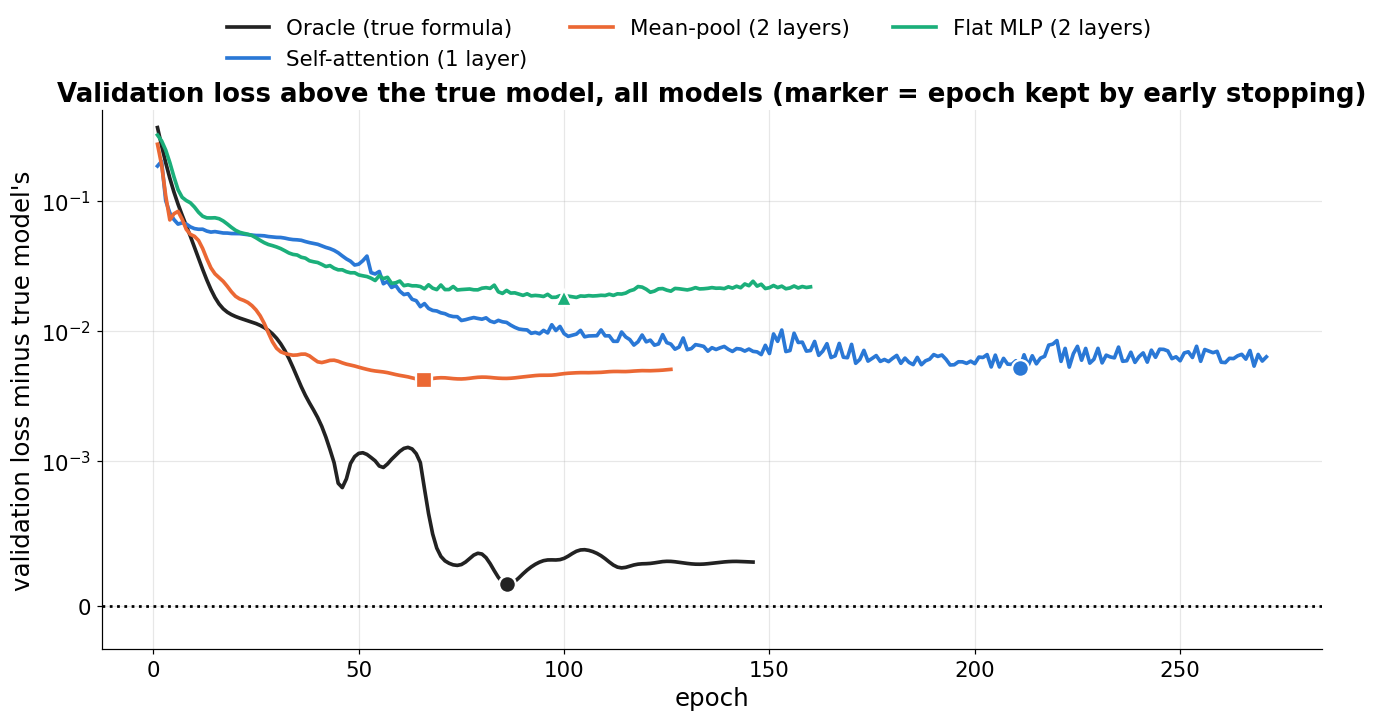

saved ./figures/ch4_training_curves_all.pdf
         epochs  best_epoch    lr      wd  params  seconds
oracle    146.0        86.0  0.03  0.0001   272.0     29.0
sa_L1     271.0       211.0  0.03  0.0001  9185.0   1286.0
mp_L2     126.0        66.0  0.01  0.0000  9201.0    404.0
flat_L2   160.0       100.0  0.01  0.0000  9243.0    110.0


In [ ]:
fig, ax = plt.subplots(figsize=(12, 6.5))
for m in ms:
    c = curves[m]; ep = np.arange(1, len(c["hist"]["val"]) + 1)
    ax.plot(ep, np.array(c["hist"]["val"]) - floor_va, color=col(m), label=label(m))
    ax.plot(c["best_ep"] + 1, c["hist"]["val"][c["best_ep"]] - floor_va, marker=mk(m), color=col(m), ms=11, mec="white", mew=1.5)
ax.axhline(0, color="black", ls=":", lw=1.8)
ax.set_yscale("symlog", linthresh=1e-3)
ax.set_ylim(-3e-4, 0.5)
ax.set(title="Validation loss above the true model, all models (marker = epoch kept by early stopping)", xlabel="epoch",
       ylabel="validation loss minus true model's")
top_legend(fig, ax, ncol=3)
save(fig, "ch4_training_curves_all")
print(pd.DataFrame({m: dict(epochs=len(curves[m]["hist"]["val"]), best_epoch=curves[m]["best_ep"] + 1,
                            lr=curves[m]["lr"], wd=curves[m]["wd"], params=curves[m]["params"],
                            seconds=round(curves[m]["seconds"])) for m in ms}).T.to_string())


**How to read it.** All validation curves on one plot, as *validation loss minus the true model's validation loss*.
The vertical scale is logarithmic above $10^{-3}$, so each grid line is 10 times smaller than the one above. 0 would be a perfect model.
The marker on each curve is the epoch kept by early stopping. The table gives epochs, the learning rate and weight decay used
(from the tuning stage), the number of parameters and the training time.

**What it shows (from the earlier run of your cluster file).** Mean-pool and self-attention end at about $5 \times 10^{-3}$ above the truth, and the flat MLP at about $2 \times 10^{-2}$.
Self-attention needs the most epochs (kept epoch 211, against 66 for mean-pool and 100 for the flat MLP), which matches it being the most data-hungry model in the data-size sweep.
Self-attention, mean-pool and the flat MLP have the same number of parameters (about 9,200), so their differences are not about model size.


---
## 4.2 Accuracy versus recovery (RQ1)

Reference setting (16 features, rank 5, 285k sessions). Accuracy comes from the training-curve runs (one dataset);
everything else from experiment E1: 30 datasets per model, with and without a context effect.


In [ ]:
# Table 4.1 of the thesis: mean +- standard deviation over the 30 datasets (printed as LaTeX rows)
E1 = R[R.exp == "E1_headline"].copy()
ctx = E1[E1.world == "context"].copy()
ref = ctx[ctx.model == "oracle"].set_index("seed")["nll_in"]
ctx["excess_nll"] = ctx["nll_in"] - ctx["seed"].map(ref)
ORDER_E1 = ["oracle", "sa_L1", "sa_L6", "mp_L2", "flat_L2", "flat_L4", "flat_L6"]       # bilinear / softmax head are in Table 3.2 only
TAB = [("excess_nll", 1000, 2), ("kl_in", 1000, 2), ("rel_frob", 1, 3), ("cosine", 1, 3), ("scale_ratio", 1, 2),
       ("theta_relerr", 1, 3), ("fid_A", 1, 2), ("c_slope", 1, 2)]
g = ctx.groupby("model")
for m in ORDER_E1:
    cells_ = [f"${g[c].mean()[m] * k:.{p}f} \\pm {g[c].std()[m] * k:.{p}f}$" for c, k, p in TAB]
    print(f"{label(m):28s} & " + " & ".join(cells_) + r" \\")
print("\ncolumns: excess test NLL (x1e-3), KL in (x1e-3), error in A, cosine, size, theta rel. error, fidelity, Metric C slope")
print("\nstd of raw test NLL across datasets:", g["nll_in"].std().round(4).to_dict())


Oracle (true formula)        & $0.00 \pm 0.00$ & $0.69 \pm 0.29$ & $0.092 \pm 0.010$ & $0.996 \pm 0.001$ & $1.01 \pm 0.01$ & $0.020 \pm 0.011$ & $1.00 \pm 0.00$ & $1.00 \pm 0.01$ \\
Self-attention (1 layer)     & $4.78 \pm 1.99$ & $5.37 \pm 1.02$ & $0.150 \pm 0.040$ & $0.990 \pm 0.005$ & $0.93 \pm 0.04$ & $0.042 \pm 0.010$ & $0.91 \pm 0.02$ & $0.92 \pm 0.04$ \\
Self-attention (6 layers)    & $4.50 \pm 2.81$ & $5.38 \pm 2.13$ & $0.163 \pm 0.062$ & $0.987 \pm 0.012$ & $0.93 \pm 0.05$ & $0.046 \pm 0.017$ & $0.92 \pm 0.03$ & $0.92 \pm 0.06$ \\
Mean-pool (2 layers)         & $4.14 \pm 1.43$ & $4.72 \pm 0.35$ & $0.142 \pm 0.016$ & $0.991 \pm 0.002$ & $0.95 \pm 0.02$ & $0.032 \pm 0.011$ & $0.92 \pm 0.00$ & $0.94 \pm 0.02$ \\
Flat MLP (2 layers)          & $22.06 \pm 3.04$ & $22.51 \pm 1.17$ & $0.241 \pm 0.035$ & $0.979 \pm 0.007$ & $0.85 \pm 0.03$ & $0.026 \pm 0.004$ & $0.59 \pm 0.02$ & $0.83 \pm 0.03$ \\
Flat MLP (4 layers)          & $22.59 \pm 3.07$ & $23.10 \pm 1.17$ & $0.291 \pm 0.034$ &

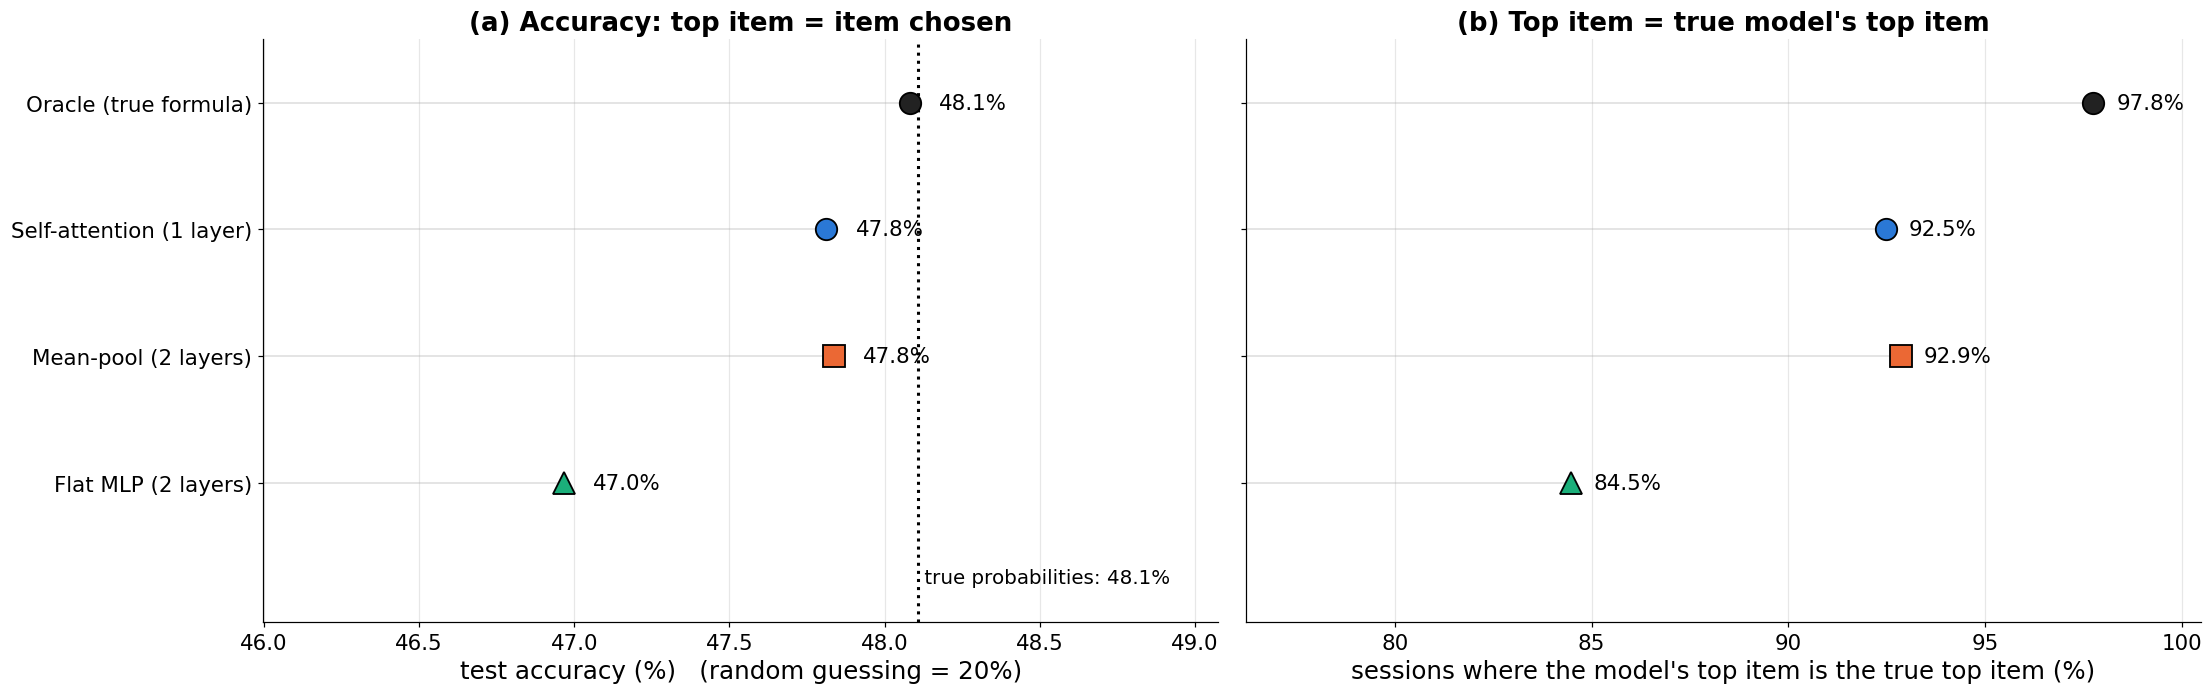

saved ./figures/ch4_accuracy.pdf
         accuracy  expected_accuracy  agree_with_truth  test_nll  test_kl
flat_L2    0.4696             0.4697            0.8448    1.2895   0.0227
mp_L2      0.4806             0.4784            0.9286    1.2695   0.0044
sa_L1      0.4800             0.4781            0.9248    1.2722   0.0059
oracle     0.4844             0.4808            0.9776    1.2652   0.0005
true model: accuracy 0.484 | expected accuracy 0.4811


In [ ]:
order = [m for m in ["flat_L2", "mp_L2", "sa_L1", "oracle"] if m in curves]
yy = np.arange(len(order))
fig, ax = plt.subplots(1, 2, figsize=(20, 6.2), sharey=True)
panels = [("expected_accuracy", 100 * truth_test["expected_accuracy"], "true probabilities",
           "(a) Accuracy: top item = item chosen", "test accuracy (%)   (random guessing = 20%)"),
          ("agree_with_truth", 100.0, "",
           "(b) Top item = true model's top item", "sessions where the model's top item is the true top item (%)")]
for a, (key, ref_, ref_txt, tt, xl) in zip(ax, panels):
    vals = [100 * curves[m][key] for m in order]
    for y_, m, v_ in zip(yy, order, vals):
        a.plot([0, v_], [y_, y_], color="#dddddd", lw=1, zorder=1)
        a.plot(v_, y_, marker=mk(m), color=col(m), ms=14, mec="black", mew=1.2, ls="", zorder=3)
        a.text(v_ + (max(vals) - min(vals)) * 0.04 + 0.05, y_, f"{v_:.1f}%", va="center", fontsize=14)
    if ref_txt:
        a.axvline(ref_, color="black", ls=":", lw=2)
        a.text(ref_, -0.75, f" {ref_txt}: {ref_:.1f}%", fontsize=13, va="center")
    span = max(vals) - min(vals)
    a.set_xlim(min(vals) - 0.6 * span - 0.3, min(100.5, max(max(vals), ref_) + 0.6 * span + 0.3))
    a.set_ylim(-1.1, len(order) - 0.5)
    a.set(title=tt, xlabel=xl); a.grid(axis="y", visible=False)
ax[0].set_yticks(yy, [label(m) for m in order])
save(fig, "ch4_accuracy")
print(pd.DataFrame({m: {k: round(curves[m][k], 4) for k in ["accuracy", "expected_accuracy", "agree_with_truth", "test_nll", "test_kl"]}
                    for m in order}).T.to_string())
print("true model: accuracy", round(truth_test["accuracy"], 4), "| expected accuracy", round(truth_test["expected_accuracy"], 4))


**How to read it.** One trained copy of each model (the training-curve runs), on 5,000 test sessions.
(a) **Accuracy:** how often the model's top item is the item actually chosen. To remove the luck of which item happened to be chosen,
it is averaged over the true choice probabilities (*expected accuracy*). The dotted line is the accuracy of the true probabilities themselves.
(b) **Agreement with the truth:** how often the model's top item is the *true model's* top item. 100% is perfect.

**What it shows (earlier run of your cluster file; check the printed table).**
* (a) **Accuracy barely separates the models.** Even the true model picks the chosen item only about 48% of the time, because the choices are
  genuinely random (Section 3.2.2). The flat MLP is at 47.0%, mean-pool at 47.8%, self-attention at 47.8%, the oracle at 48.1%.
* (b) **Agreement with the truth does separate them.** The oracle picks the true top item in about 98% of sessions, self-attention and mean-pool in about 93%,
  and the flat MLP in only about 85%. Same ordering as loss and KL, which are measured over 30 datasets.


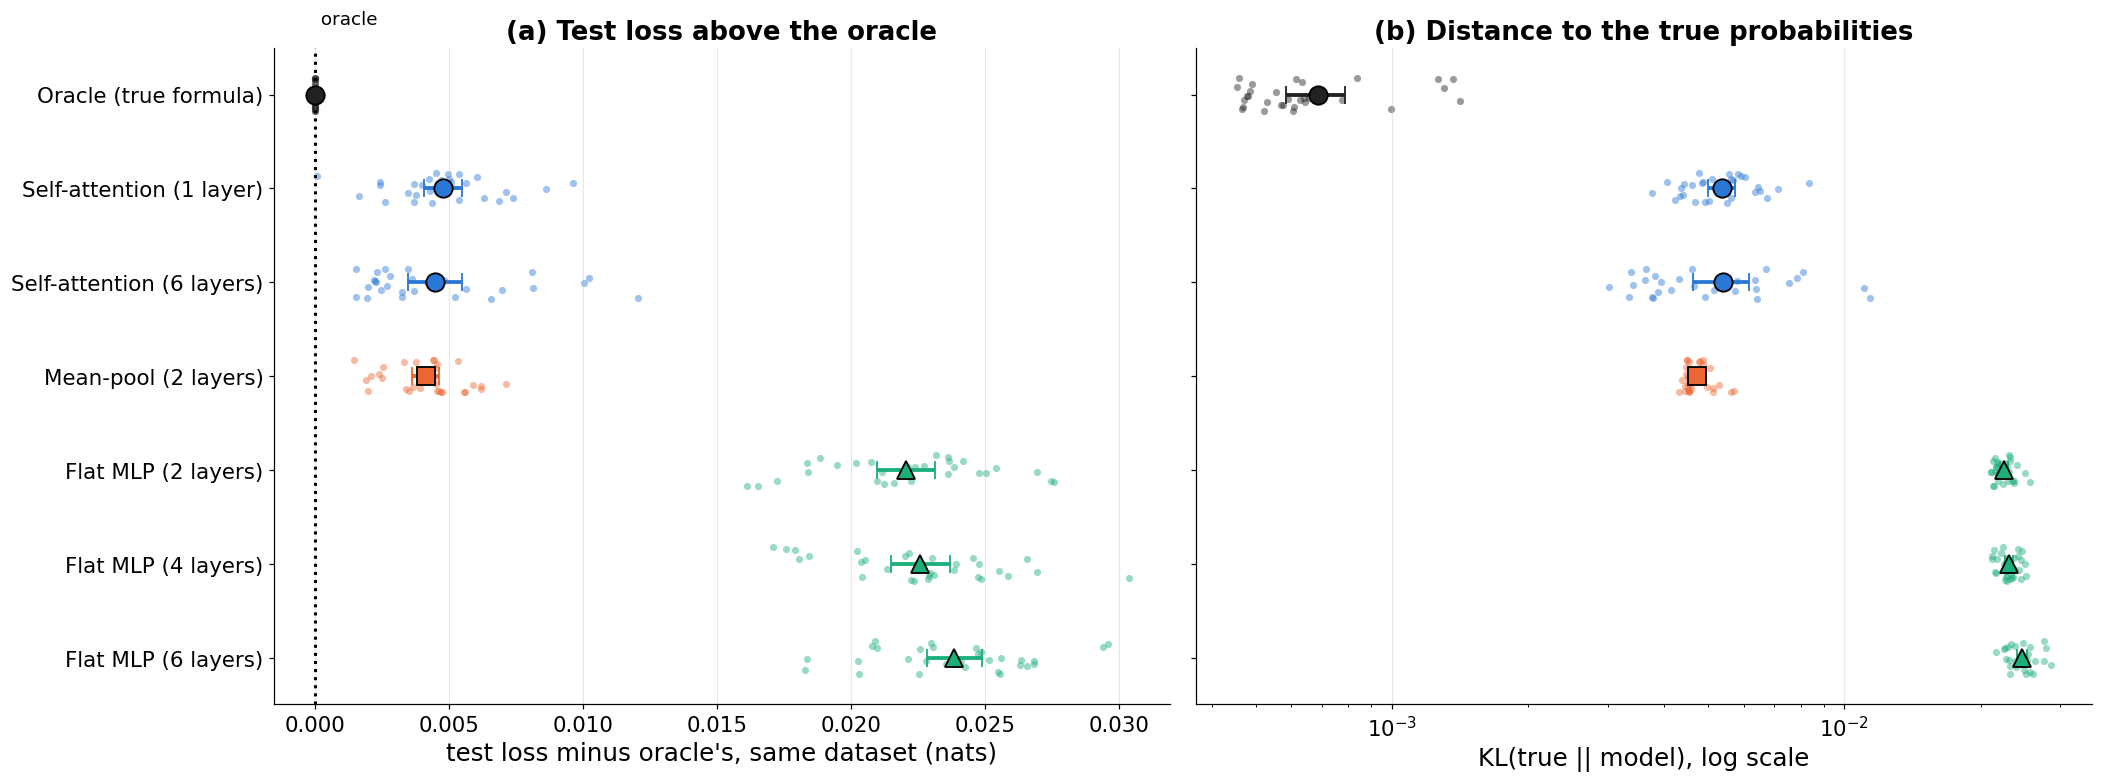

saved ./figures/ch4_prediction.pdf
              KL    KL_ci  excess_nll
model                                
oracle   0.00069  0.00010     0.00000
sa_L1    0.00537  0.00037     0.00478
sa_L6    0.00538  0.00076     0.00450
mp_L2    0.00472  0.00013     0.00414
flat_L2  0.02251  0.00042     0.02206
flat_L4  0.02310  0.00042     0.02259
flat_L6  0.02473  0.00062     0.02387


In [ ]:
E1 = R[R.exp == "E1_headline"].copy()
ORDER_E1 = ["oracle", "sa_L1", "sa_L6", "mp_L2", "flat_L2", "flat_L4", "flat_L6"]
ctx = E1[E1.world == "context"].copy()
ref = ctx[ctx.model == "oracle"].set_index("seed")["nll_in"]
ctx["excess_nll"] = ctx["nll_in"] - ctx["seed"].map(ref)          # paired: same dataset, minus the oracle

fig, ax = plt.subplots(1, 2, figsize=(19, 7), sharey=True)
strip(ax[0], ctx, "excess_nll", ORDER_E1, ref_line=0, ref_text=" oracle")
ax[0].set(title="(a) Test loss above the oracle", xlabel="test loss minus oracle's, same dataset (nats)")
strip(ax[1], ctx, "kl_in", ORDER_E1, logx=True)
ax[1].set(title="(b) Distance to the true probabilities", xlabel="KL(true || model), log scale")
save(fig, "ch4_prediction")
t = summ(ctx, "model", "kl_in").loc[ORDER_E1, ["mean", "ci"]].rename(columns=dict(mean="KL", ci="KL_ci"))
t["excess_nll"] = summ(ctx, "model", "excess_nll").loc[ORDER_E1, "mean"]
print(t.round(5).to_string())


**How to read it.** Each small dot is one of the 30 datasets. The big marker is the mean, with its 95% confidence interval.
(a) Each model's test loss minus the oracle's loss **on the same dataset**. Subtracting the oracle removes the dataset-to-dataset noise. (b) KL divergence to the true probabilities, log scale.

**What it shows.** Two groups, plus a tie that must not be over-read.
* **Self-attention and mean-pool are about 0.004 to 0.005 nats above the oracle** (self-attention 0.00478, mean-pool 0.00414). Against the 0.061 that context is worth,
  they capture about **92 to 93%** of it. Self-attention with 1 or 6 layers is indistinguishable. **Self-attention and mean-pool are within noise of each other**
  (differences are smaller than the spread between datasets), so do not claim that attention beats mean-pool.
* **The flat MLPs are about 0.022 nats above the oracle** (0.0221, 0.0226, 0.0239 for 2, 4, 6 layers): they miss about 36 to 39% of the context effect, and deeper is slightly worse.


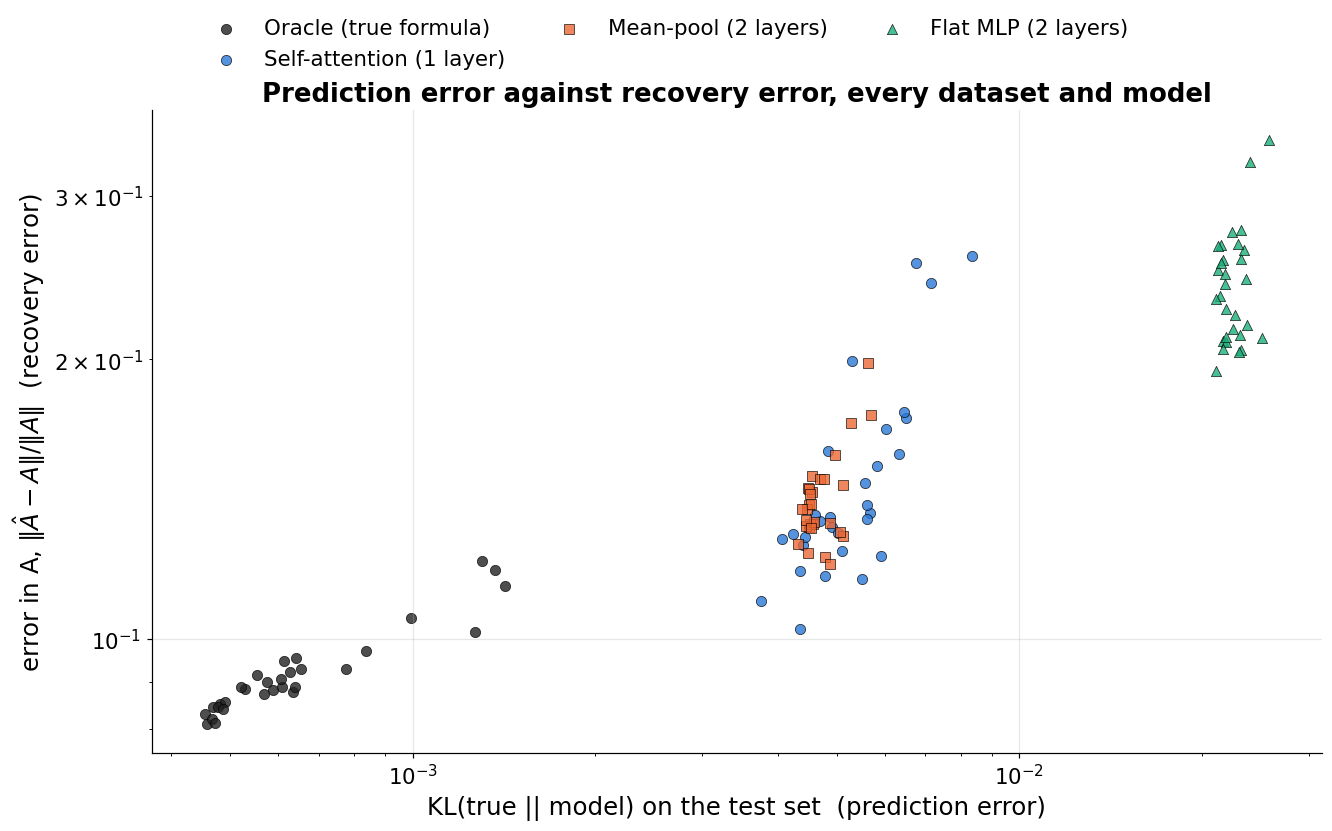

saved ./figures/ch4_accuracy_vs_recovery.pdf
correlation of log KL with log error in A, all plotted runs: 0.93
  within sa_L1   : 0.79
  within sa_L6   : 0.92
  within mp_L2   : 0.62
  within flat_L2 : 0.33


In [ ]:
fig, ax = plt.subplots(figsize=(12, 7.5))
SC = ["oracle", "sa_L1", "mp_L2", "flat_L2"]       # one model per family keeps the legend readable
for m in SC:
    d_ = ctx[ctx.model == m]
    ax.scatter(d_.kl_in, d_.rel_frob, s=45, marker=mk(m), color=col(m), edgecolor="black", lw=0.5, alpha=0.8, label=label(m))
ax.set(xscale="log", yscale="log", xlabel="KL(true || model) on the test set  (prediction error)",
       ylabel=r"error in A, $\|\hat A - A\|/\|A\|$  (recovery error)",
       title="Prediction error against recovery error, every dataset and model")
top_legend(fig, ax, ncol=3)
save(fig, "ch4_accuracy_vs_recovery")
cs = ctx[ctx.model.isin(SC)]
print("correlation of log KL with log error in A, all plotted runs: %.2f" % np.corrcoef(np.log(cs.kl_in), np.log(cs.rel_frob))[0, 1])
for m in ["sa_L1", "sa_L6", "mp_L2", "flat_L2"]:
    d_ = ctx[ctx.model == m]
    print(f"  within {m:8s}: {np.corrcoef(np.log(d_.kl_in), np.log(d_.rel_frob))[0, 1]:.2f}")


**How to read it.** Each point is one trained model on one dataset (30 datasets per model). Horizontal: how far its predicted
probabilities are from the truth. Vertical: how far its recovered $\hat A$ is from the true $A$. Both axes are logarithmic.

**What it shows (numbers printed above).** Across architectures, prediction and recovery move together: correlation 0.93 on the log scale
(oracle, self-attention, mean-pool, flat MLP together). Within one architecture the link is weaker for some models
(0.79 for 1-layer self-attention, 0.62 for mean-pool, 0.33 for the flat MLP, 0.95 for the oracle). So in this setting good prediction goes with good recovery
**across** architectures, but the prediction error alone does not pin down the recovery error of a single run.
Careful: this is a correlation over models that differ in structure; it does not show that better prediction *causes* better recovery.


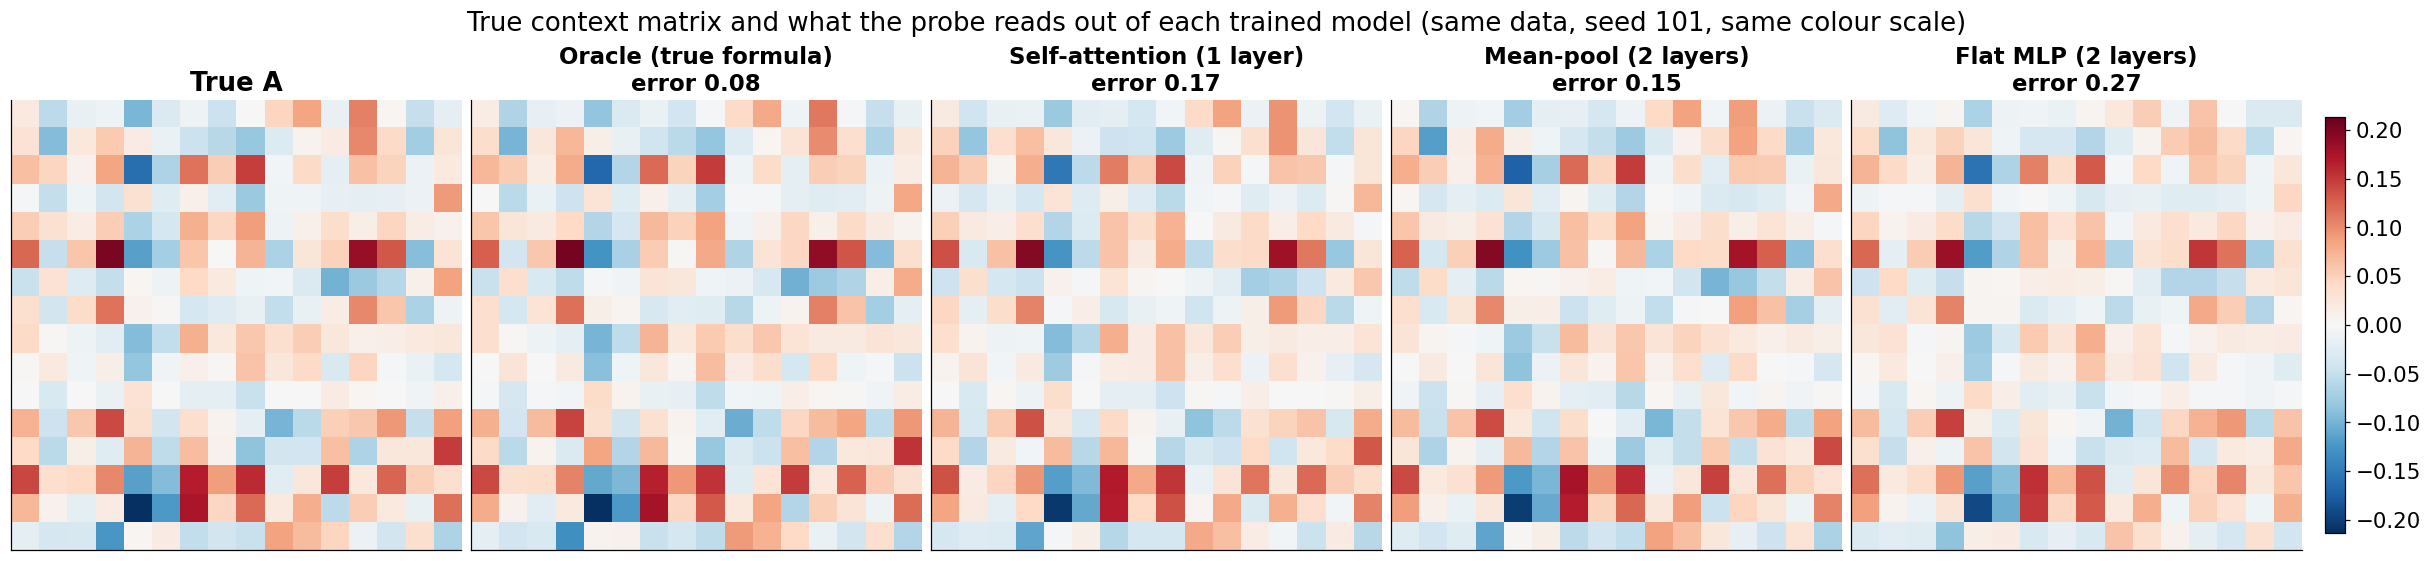

saved ./figures/ch4_A_heatmaps.pdf


In [ ]:
show = ["oracle", "sa_L1", "mp_L2", "flat_L2"]
th101, A101 = L.make_ground_truth(16, 5, 101)
rows = ctx[ctx.seed == 101].set_index("model")
fig, axs = plt.subplots(1, 5, figsize=(22, 5.3))
v = np.abs(A101).max()
axs[0].imshow(A101, cmap="RdBu_r", vmin=-v, vmax=v); axs[0].set_title("True A")
for ax, m in zip(axs[1:], show):
    im = ax.imshow(A_of(rows.loc[m]), cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_title(f"{label(m)}\nerror {rows.loc[m, 'rel_frob']:.2f}", fontsize=15)
for ax in axs: ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.colorbar(im, ax=axs, shrink=0.8, pad=0.01)
fig.suptitle("True context matrix and what the probe reads out of each trained model (same data, seed 101, same colour scale)", fontsize=17)
save(fig, "ch4_A_heatmaps")


**How to read it.** All panels use the same colour scale. The closer a panel looks to the leftmost one, the better the probe's read-out
matches the true $A$. The error under each title is $\lVert\hat A - A\rVert/\lVert A\rVert$ for this one dataset (seed 101).

**What it shows.** Every model reproduces the main pattern: the strong red and blue rows and columns are in the same places.
The oracle is almost exact (error 0.08); its remaining difference is due to the finite data only. Self-attention (0.17) and mean-pool (0.15) are fainter and noisier.
The flat MLP is visibly noisier (0.27). The next figure shows the same measure over all 30 datasets. (One dataset can mislead: self-attention with 6 layers has 0.10 on this seed, but 0.163 on average.)


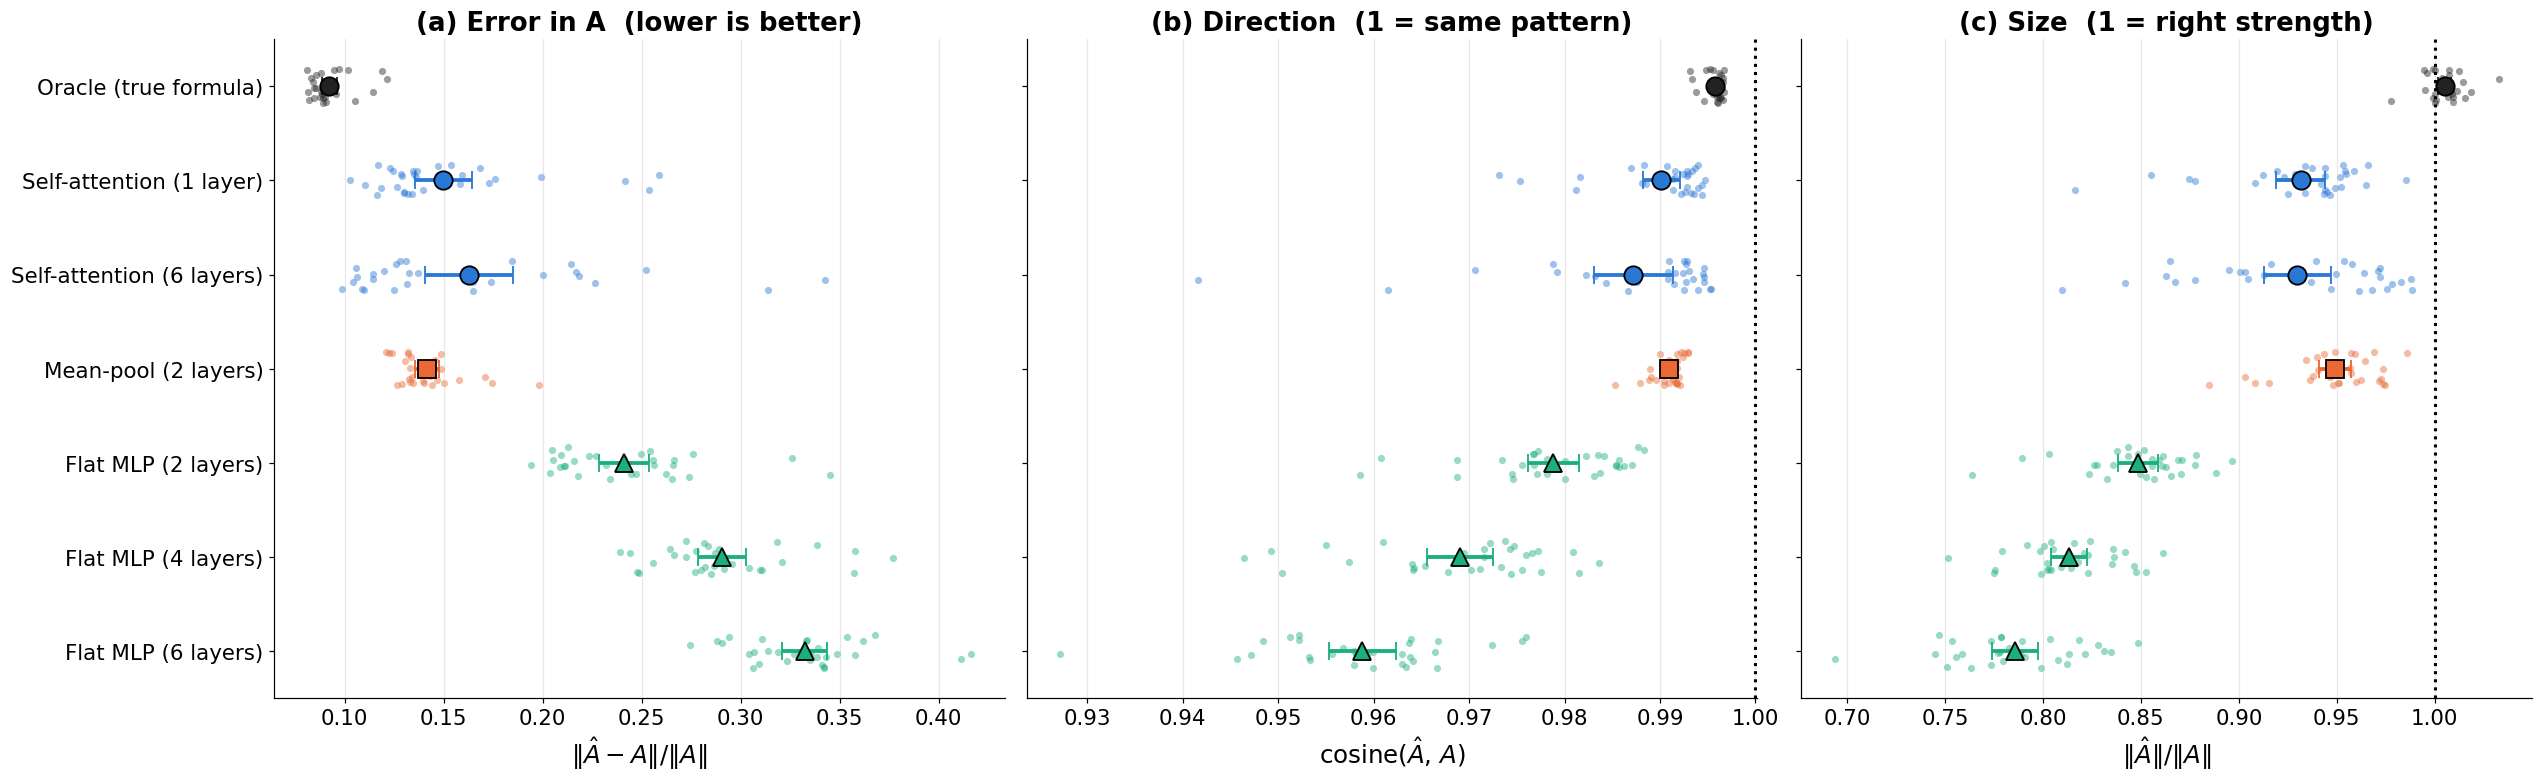

saved ./figures/ch4_recovery.pdf
         rel_frob  cosine  scale_ratio  theta_cos  theta_relerr
model                                                          
oracle     0.0923  0.9958       1.0051     0.9998        0.0197
sa_L1      0.1497  0.9901       0.9315     0.9993        0.0422
sa_L6      0.1630  0.9872       0.9298     0.9992        0.0455
mp_L2      0.1415  0.9909       0.9491     0.9996        0.0317
flat_L2    0.2413  0.9788       0.8486     0.9998        0.0257
flat_L4    0.2907  0.9690       0.8133     0.9998        0.0339
flat_L6    0.3323  0.9588       0.7859     0.9997        0.0469


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(23, 7), sharey=True)
strip(ax[0], ctx, "rel_frob", ORDER_E1)
ax[0].set(title="(a) Error in A  (lower is better)", xlabel=r"$\|\hat A - A\| / \|A\|$")
strip(ax[1], ctx, "cosine", ORDER_E1, ref_line=1)
ax[1].set(title="(b) Direction  (1 = same pattern)", xlabel=r"cosine($\hat A$, $A$)")
strip(ax[2], ctx, "scale_ratio", ORDER_E1, ref_line=1)
ax[2].set(title="(c) Size  (1 = right strength)", xlabel=r"$\|\hat A\| / \|A\|$")
save(fig, "ch4_recovery")
print(pd.concat({k: summ(ctx, "model", k)["mean"] for k in ["rel_frob", "cosine", "scale_ratio", "theta_cos", "theta_relerr"]}, axis=1)
      .loc[ORDER_E1].round(4).to_string())


**How to read it.** Same layout as the prediction figure, 30 datasets per model.
The **oracle's error (0.09) is the floor set by the amount of data**: no method can beat it on average.

**What it shows.**
* (a) **Error in A.** Oracle 0.092; self-attention 0.150 (1 layer) and 0.163 (6 layers); mean-pool 0.142; the flat MLP 0.24, 0.29, 0.33 (2, 4, 6 layers), worse with every extra layer.
  Self-attention and mean-pool are within noise of each other.
* (b) **Direction.** All models get the pattern of $A$ broadly right (cosine at least 0.96). Cosines near 1 hide real differences: 0.996 (oracle) against 0.990 (self-attention) is an error of 0.09 against 0.15.
* (c) **Size.** The free-form networks *under-react* to context: self-attention recovers 93% of the true strength, mean-pool 95%, and the flat MLP 79 to 85%. The oracle gets it right (1.005).
* **$\theta$ is recovered by every model** (cosine above 0.999 for all, error 2% to 5%), including the flat MLP. The base preferences are the easy part.


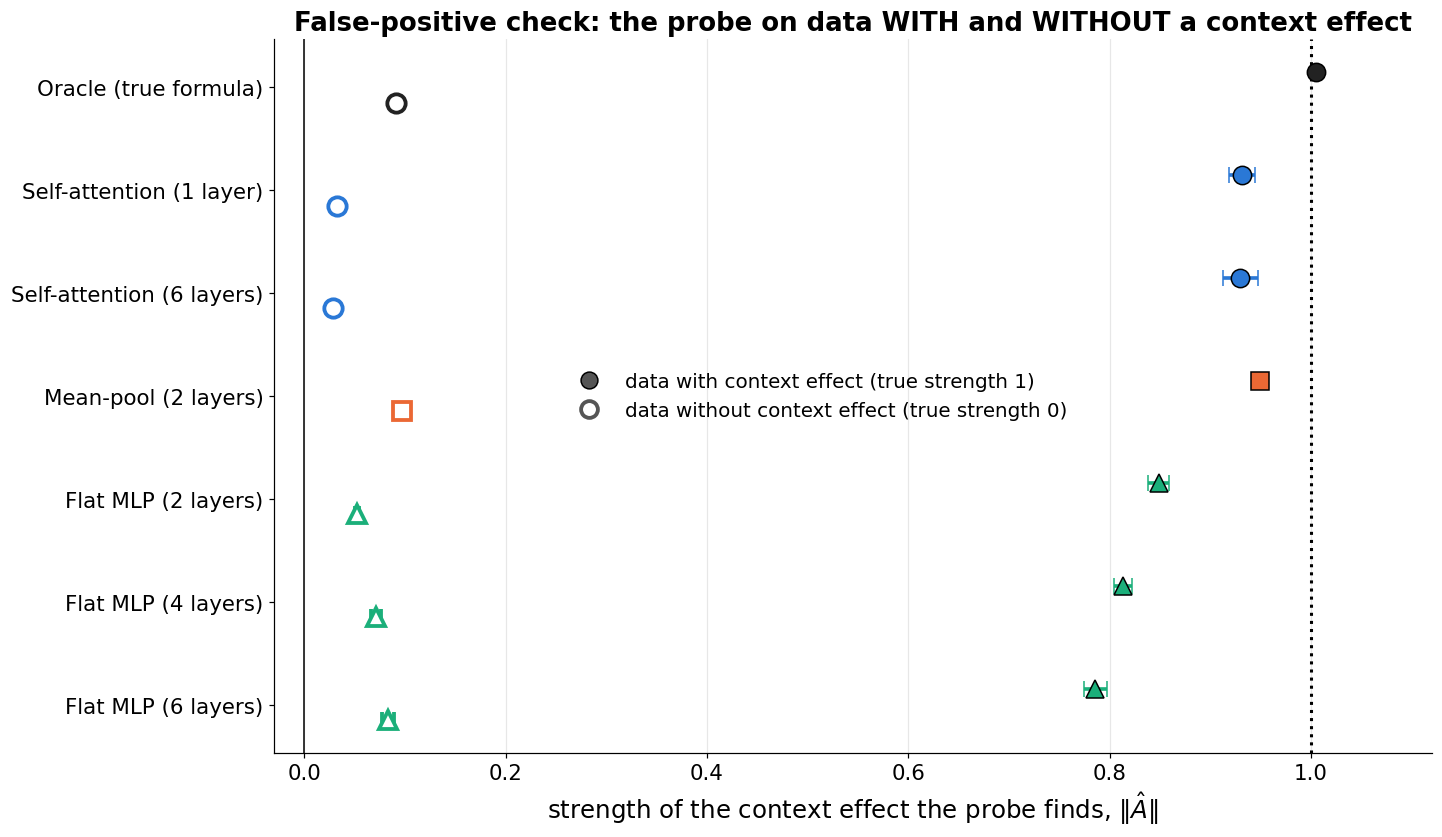

saved ./figures/ch4_false_positive.pdf
         with effect  without effect
model                               
oracle         1.005           0.091
sa_L1          0.931           0.033
sa_L6          0.930           0.028
mp_L2          0.949           0.097
flat_L2        0.849           0.052
flat_L4        0.813           0.071
flat_L6        0.786           0.083


In [ ]:
fig, ax = plt.subplots(figsize=(13, 7.5))
g_c = summ(E1[E1.world == "context"], "model", "fro_hat"); g_0 = summ(E1[E1.world == "no_effect"], "model", "fro_hat")
for i, m in enumerate(ORDER_E1):
    ax.errorbar(g_c.loc[m, "mean"], i - 0.15, xerr=g_c.loc[m, "ci"], fmt=mk(m), color=col(m), ms=12, mec="black", capsize=5)
    ax.errorbar(g_0.loc[m, "mean"], i + 0.15, xerr=g_0.loc[m, "ci"], fmt=mk(m), color="white", mec=col(m), mew=2.5, ms=12,
                ecolor=col(m), capsize=5)
ax.axvline(1, color="black", ls=":", lw=2); ax.axvline(0, color="black", lw=1)
ax.set_yticks(range(len(ORDER_E1)), [label(m) for m in ORDER_E1]); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set(xlabel=r"strength of the context effect the probe finds, $\|\hat A\|$", xlim=(-0.03, 1.12),
       title="False-positive check: the probe on data WITH and WITHOUT a context effect")
ax.legend(handles=[Line2D([], [], marker="o", color="#555", mec="black", ls="", ms=11, label="data with context effect (true strength 1)"),
                   Line2D([], [], marker="o", color="white", mec="#555", mew=2.5, ls="", ms=11, label="data without context effect (true strength 0)")],
          loc="center", bbox_to_anchor=(0.47, 0.5))
save(fig, "ch4_false_positive")
print(pd.DataFrame({"with effect": g_c["mean"], "without effect": g_0["mean"]}).loc[ORDER_E1].round(3).to_string())


**How to read it.** Filled markers: trained on data **with** a context effect (true strength 1). Hollow markers: trained on data
**without** one (true strength 0, plain logit). A trustworthy probe should report about 1 for the first and about 0 for the second.

**What it shows.** Without an effect, every model reports 0.03 to 0.10 (printed table), not exactly 0, because of finite data.
The oracle itself reports 0.09: it fits all 256 entries of $A$ freely and picks up noise.
Self-attention reports the least (0.03), so **it does not invent context effects**.
With an effect, self-attention reports 0.93, about 30 times its no-effect value. For every model the two cases are far apart,
so the probe separates "has learned a context effect" from "has not" without ambiguity.


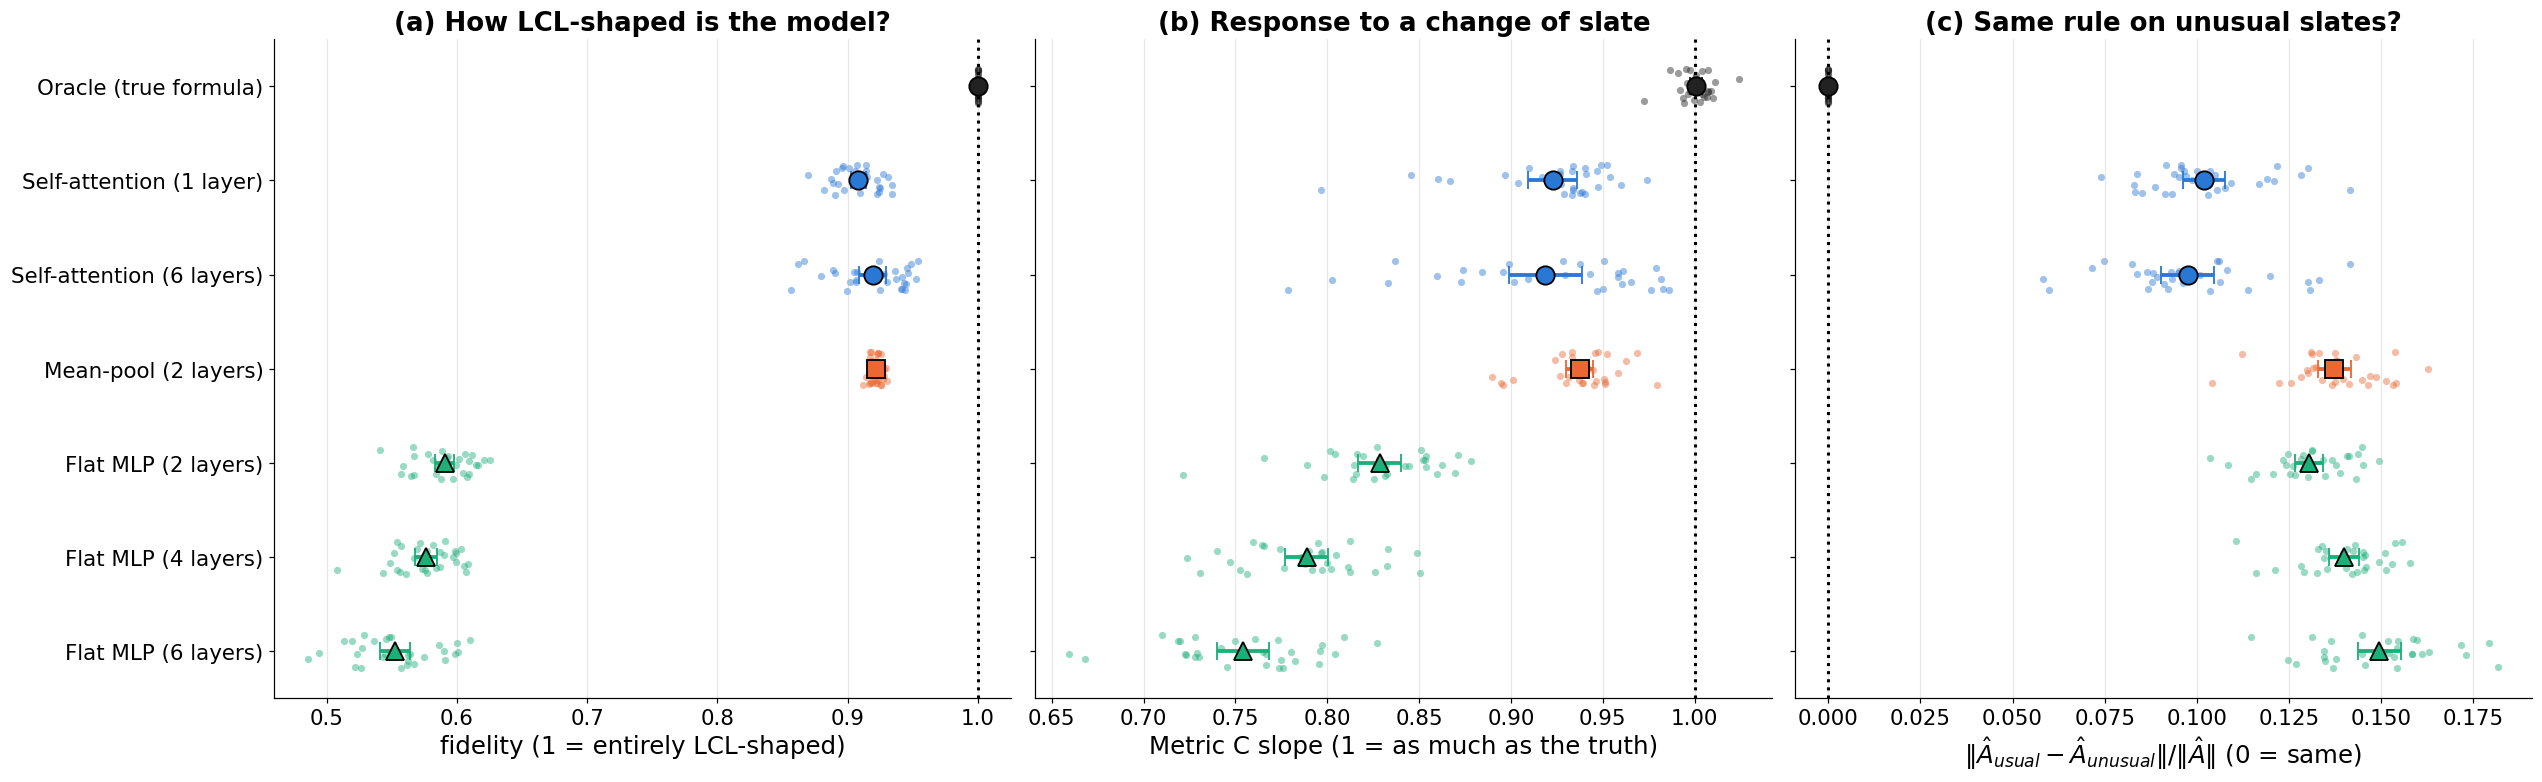

saved ./figures/ch4_lcl_shape.pdf
         fid_A  c_slope   c_r2  inv_rel
model                                  
oracle   1.000    1.001  0.992    0.000
sa_L1    0.908    0.923  0.890    0.102
sa_L6    0.919    0.919  0.897    0.097
mp_L2    0.922    0.937  0.904    0.137
flat_L2  0.590    0.829  0.565    0.130
flat_L4  0.576    0.789  0.541    0.140
flat_L6  0.553    0.754  0.512    0.149


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(23, 7), sharey=True)
strip(ax[0], ctx, "fid_A", ORDER_E1, ref_line=1)
ax[0].set(title="(a) How LCL-shaped is the model?", xlabel="fidelity (1 = entirely LCL-shaped)")
strip(ax[1], ctx, "c_slope", ORDER_E1, ref_line=1)
ax[1].set(title="(b) Response to a change of slate", xlabel="Metric C slope (1 = as much as the truth)")
strip(ax[2], ctx, "inv_rel", ORDER_E1, ref_line=0)
ax[2].set(title="(c) Same rule on unusual slates?", xlabel=r"$\|\hat A_{usual} - \hat A_{unusual}\| / \|\hat A\|$ (0 = same)")
save(fig, "ch4_lcl_shape")
print(pd.concat({k: summ(ctx, "model", k)["mean"] for k in ["fid_A", "c_slope", "c_r2", "inv_rel"]}, axis=1).loc[ORDER_E1].round(3).to_string())


**How to read it.**
(a) **Fidelity:** the share of the model's context behaviour that the LCL straight-line form explains (1 means entirely LCL-shaped).
(b) **Metric C:** change the other items on the slate, and compare how much the model's preference between two items moves with how much it
should move. A slope of 1 means it moves exactly as much as the truth.
(c) **Invariance:** read out $\hat A$ once on usual slates and once on unusual slates. 0 means the model uses the same rule everywhere.

**What it shows.**
* (a) Self-attention (0.91) and mean-pool (0.92) are **about 90% LCL-shaped**. The flat MLP is only 0.55 to 0.59:
  about half of how it reacts to the slate does not follow the LCL form.
* (b) Self-attention (0.92) and mean-pool (0.94) under-react to slate changes by 6 to 8%. The flat MLP under-reacts by 17 to 25%,
  and more so when deeper. This agrees with the size measure (scale ratio) in the recovery figure, from a different test.
* (c) The context rule inside the networks shifts by 10 to 15% on unusual slates, so it is close to LCL but not exactly LCL.
  Self-attention is the most stable of the free-form networks (0.10, against 0.14 for mean-pool).


---
## 4.3 What drives recovery (RQ2)

Each sweep changes **one thing** and keeps the rest at the reference setting. Points are means over datasets (seeds);
error bars and bands are 95% confidence intervals of the mean.

| sweep | what changes | models | datasets per point |
|---|---|---|---|
| 4.3.5 depth (E5) | layers: self-attention 1, 2, 4, 6; mean-pool and flat MLP 2, 4, 6; at 71k and 285k sessions | SA, MP, flat, wide flat, oracle | 15 |
| 4.3.3 sparsity (E4) | 0 to 80% of the entries of A set to zero (A of full rank 16), at 71k and 285k | SA, MP, flat, oracle | 15 |
| 4.3.2 rank (E3) | true rank of A: 1, 2, 4, 8, 16; and head size h: 1, 2, 4, 8, 16 | all | 10 |
| 4.3.1 data size (E2) | 18k to 1.14M training sessions | SA, MP, flat, oracle | 15 |
| 4.3.4 features (E4) | d = 6 to 32, with data growing as $d^2$, and with data fixed at 40k | SA, MP, flat, oracle | 10 |
| 4.3.6 learning rate, weight decay, width (E7) | all 6 tuning combinations; half and double width | SA, MP, flat | 10 |
| 4.3.7 random initialisation (E6) | same data, 20 different starting weights | SA, MP, oracle | 10 x 20 |


### 4.3.1 Training-set size


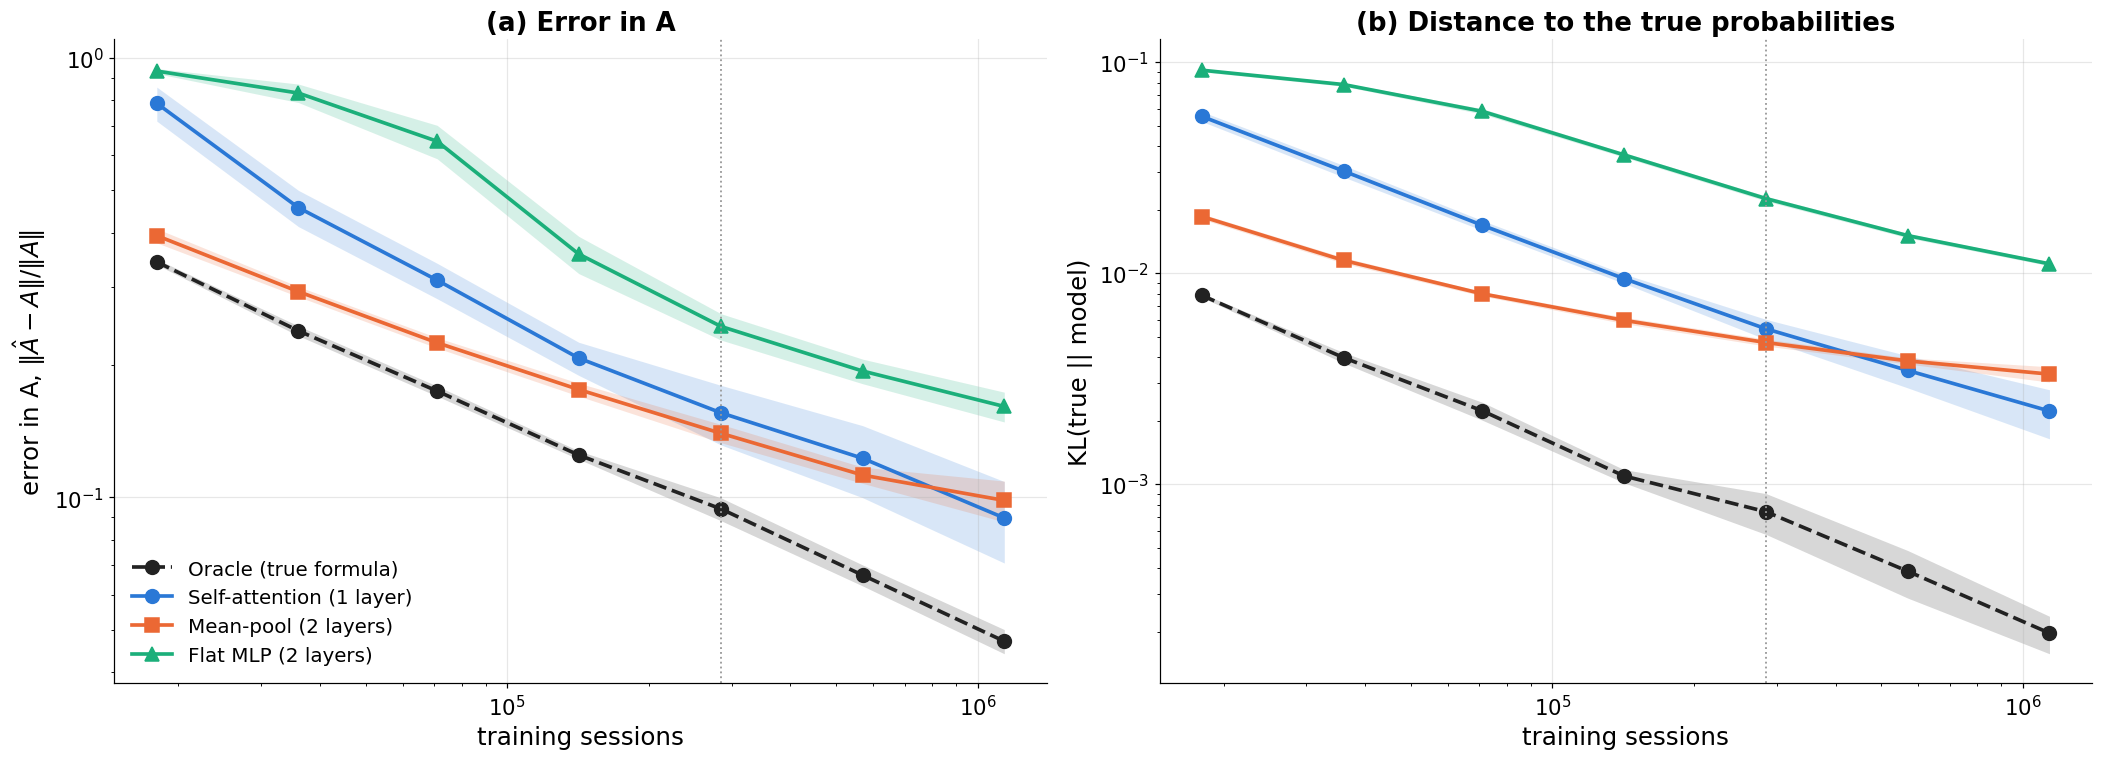

saved ./figures/ch4_sweep_datasize.pdf
model    oracle  sa_L1  mp_L2  flat_L2
n                                     
18000     0.343  0.787  0.394    0.932
36000     0.239  0.456  0.294    0.830
71000     0.174  0.312  0.225    0.645
142000    0.125  0.207  0.176    0.357
285000    0.094  0.156  0.140    0.245
570000    0.067  0.123  0.112    0.194
1140000   0.047  0.090  0.098    0.161


In [ ]:
E2 = R[(R.exp == "E2_datasize") & (R.world == "context")]
M2 = ["oracle", "sa_L1", "mp_L2", "flat_L2"]
fig, ax = plt.subplots(1, 2, figsize=(19, 6.8))
for k, (val, yl, tt) in enumerate([("rel_frob", r"error in A, $\|\hat A - A\|/\|A\|$", "(a) Error in A"),
                                   ("kl_in", "KL(true || model)", "(b) Distance to the true probabilities")]):
    for m in M2:
        g = summ(E2[E2.model == m], "n", val)
        ax[k].plot(g.index, g["mean"], marker=mk(m), color=col(m), label=label(m), ls="--" if m == "oracle" else "-")
        ax[k].fill_between(g.index, g["mean"] - g["ci"], g["mean"] + g["ci"], color=col(m), alpha=0.18, lw=0)
    ax[k].set(xscale="log", yscale="log", xlabel="training sessions", ylabel=yl, title=tt)
    ax[k].axvline(285000, color="#999", lw=1.2, ls=":")
ax[0].legend(loc="lower left")
save(fig, "ch4_sweep_datasize")
print(E2.pivot_table(index="n", columns="model", values="rel_frob")[M2].round(3).to_string())


**How to read it.** Both axes are logarithmic. The shaded bands are 95% confidence intervals. The dotted vertical line marks the headline size (285k).

**What it shows.**
* **The oracle** falls along a straight line: its error shrinks steadily with more data, as expected for a correctly specified model.
* **Mean-pool** is close to the oracle with little data (0.39 against 0.34 at 18k), but improves more slowly with large data
  (0.098 against 0.047 at 1.14M). This is the sign of a small *bias*: with ReLU layers, mean-pool can only approximate the
  product of an item with the slate average that LCL needs.
* **Self-attention** is poor with little data (0.79 at 18k, when it has not yet learned to average the slate), but it keeps improving.
  In KL it draws level with mean-pool at 570k and is clearly ahead at 1.14M (0.0022 against 0.0033). In error in A the two are tied at 1.14M (0.090 against 0.098; the intervals overlap).
* **The flat MLP** improves too, but stays far behind. At 1.14M sessions its error (0.16) is about what self-attention reaches with 142k,
  so it needs roughly 8 times more data.


### 4.3.2 Rank of the context-effect matrix (and size of the attention head)


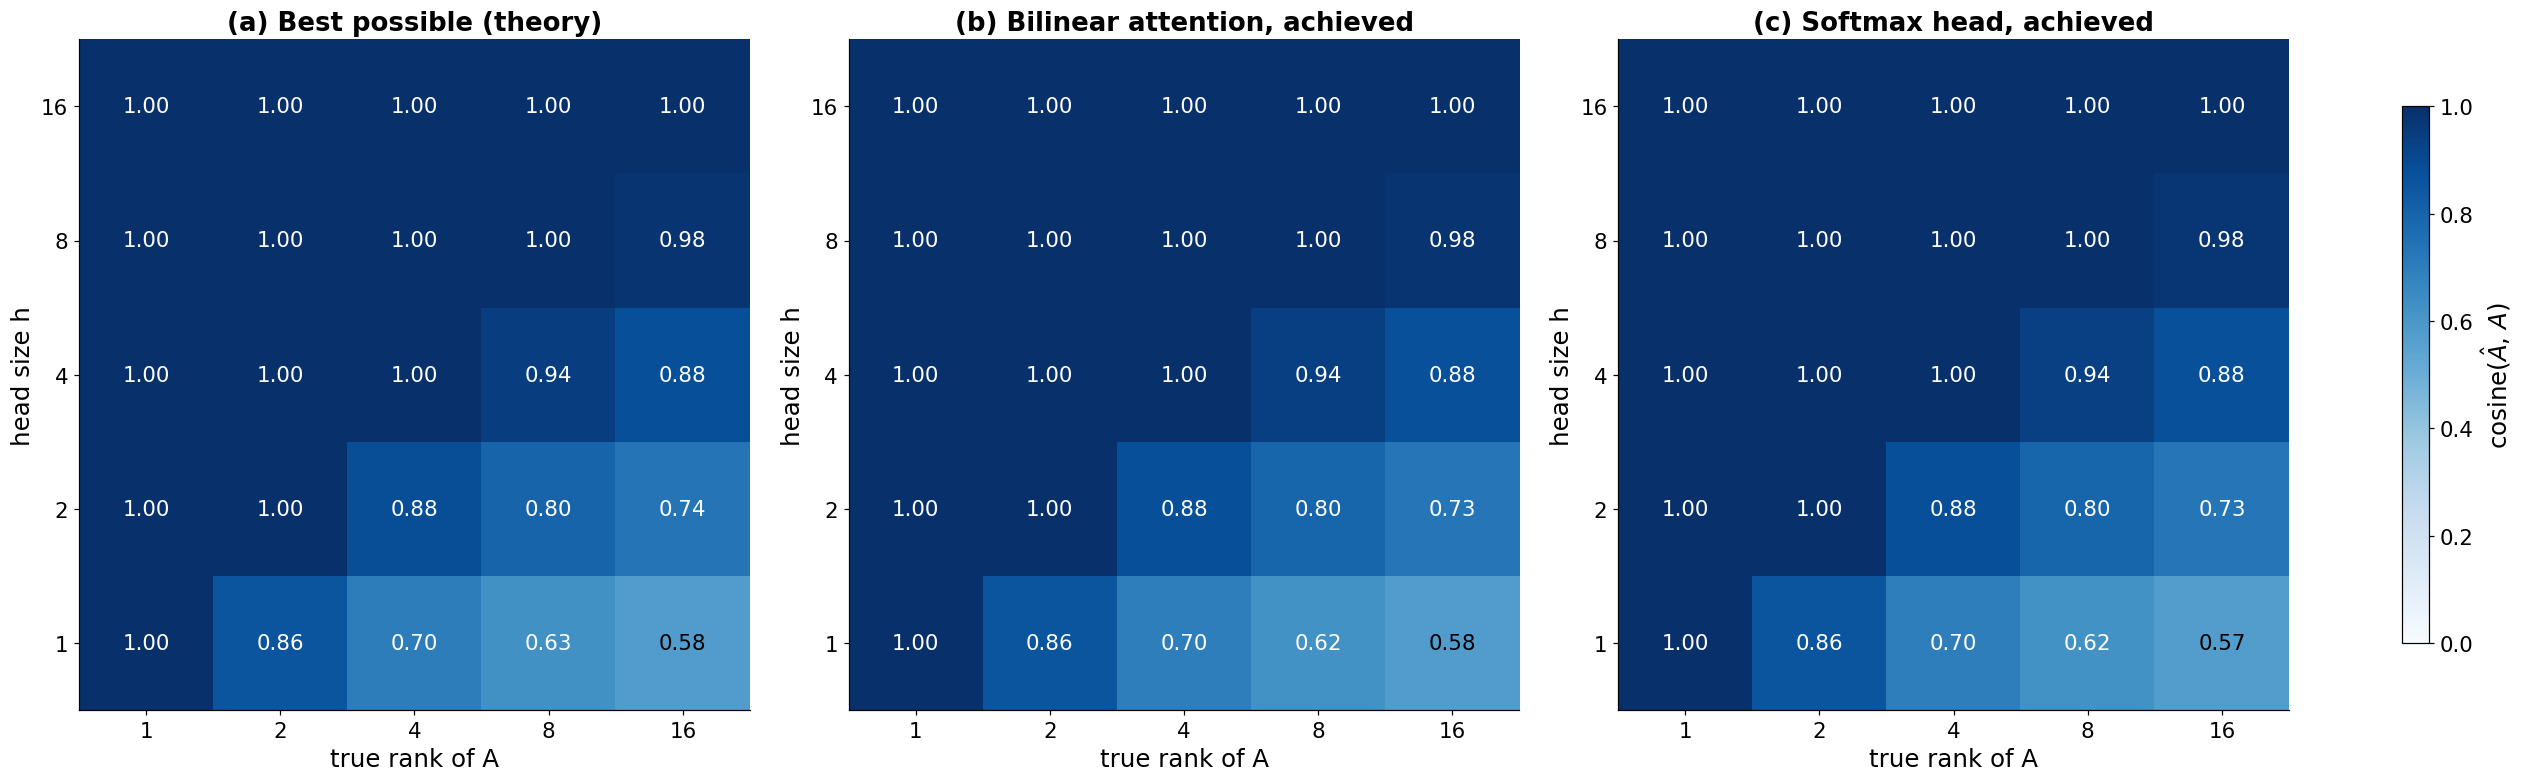

saved ./figures/extra_rank_heads.pdf
largest |achieved - best possible| over the whole grid: 0.006
number of datasets per cell: 10


In [ ]:
E3 = R[R.exp == "E3_rank"]
ranks, heads = [1, 2, 4, 8, 16], [1, 2, 4, 8, 16]
def grid(fam_, val):
    G = np.full((5, 5), np.nan)
    for i, h in enumerate(heads):
        for j, r in enumerate(ranks):
            v = E3[(E3.model == f"{fam_}_h{h}") & (E3["rank"] == r)][val]
            G[i, j] = v.mean() if len(v) else np.nan
    return G
ceil = grid("bil", "ey_ceiling")
fig, axs = plt.subplots(1, 3, figsize=(23, 7))
for ax, (G, tt) in zip(axs, [(ceil, "(a) Best possible (theory)"), (grid("bil", "cosine"), "(b) Bilinear attention, achieved"),
                             (grid("sov", "cosine"), "(c) Softmax head, achieved")]):
    im = ax.imshow(G, cmap="Blues", vmin=0, vmax=1, origin="lower")
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{G[i, j]:.2f}", ha="center", va="center", fontsize=14, color="white" if G[i, j] > 0.6 else "black")
    ax.set_xticks(range(5), ranks); ax.set_yticks(range(5), heads); ax.grid(False)
    ax.set(xlabel="true rank of A", ylabel="head size h", title=tt)
fig.colorbar(im, ax=axs, shrink=0.8, label=r"cosine($\hat A$, $A$)")
save(fig, "extra_rank_heads")          # OPTIONAL: Chapter 3 quotes only the summary number below (decision pending)
gap = np.maximum(np.abs(grid("bil", "cosine") - ceil), np.abs(grid("sov", "cosine") - ceil))
print("largest |achieved - best possible| over the whole grid:", round(np.nanmax(gap), 3))
print("number of datasets per cell:", int(E3[(E3.model == "bil_h4") & (E3["rank"] == 4)].seed.nunique()))


**How to read it.** Rows: the size $h$ of the attention head. Columns: the true rank of $A$. Each cell is the cosine between $\hat A$ and $\hat A$'s truth $A$.
Panel (a) is the **best any rank-$h$ model can do in theory** (Eckart-Young: keep the $h$ strongest directions of $A$).

**What it shows.** Bilinear attention and the softmax head **reach the theoretical best in every cell**; the largest difference over the grid is 0.006 (printed above).
So a head that is too small falls short only because of its size, not because training failed. *This is the number Chapter 3 quotes. The figure itself is optional.*


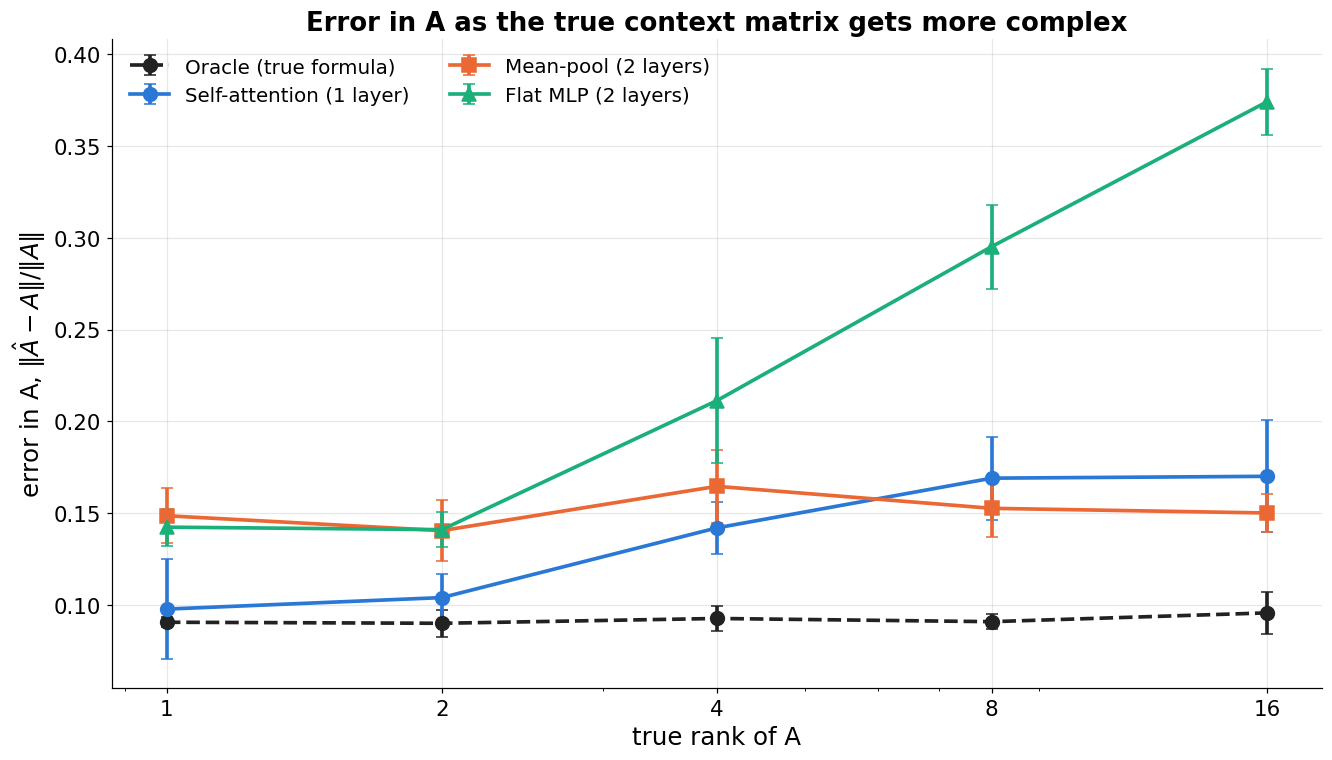

saved ./figures/ch4_sweep_rank.pdf
model  oracle  sa_L1  mp_L2  flat_L2
rank                                
1       0.091  0.098  0.149    0.142
2       0.090  0.104  0.140    0.141
4       0.093  0.142  0.165    0.211
8       0.091  0.169  0.153    0.295
16      0.096  0.170  0.150    0.374


In [ ]:
M3 = ["oracle", "sa_L1", "mp_L2", "flat_L2"]
fig, ax = plt.subplots(figsize=(12, 6.8))
for m in M3:
    g = summ(E3[E3.model == m], "rank", "rel_frob")
    ax.errorbar(g.index, g["mean"], yerr=g["ci"], marker=mk(m), color=col(m), label=label(m), capsize=4,
                ls="--" if m == "oracle" else "-")
ax.set(xscale="log", xticks=ranks, xlabel="true rank of A", ylabel=r"error in A, $\|\hat A - A\|/\|A\|$",
       title="Error in A as the true context matrix gets more complex")
ax.set_xticklabels(ranks); ax.legend(loc="upper left", ncol=2)
save(fig, "ch4_sweep_rank")
print(E3[E3.model.isin(M3)].pivot_table(index="rank", columns="model", values="rel_frob")[M3].round(3).to_string())


**How to read it.** Error in A against the true rank of $A$ (bilinear attention and the softmax head are in Chapter 3 only).

**What it shows.**
* The oracle stays at about 0.09 for every rank: rank does not matter to it.
* **Self-attention is best when $A$ is simple.** At rank 1 to 2 it nearly matches the oracle (0.098, 0.104 against 0.091, 0.090) and is clearly better than mean-pool (0.149, 0.140). Its error grows to 0.17 at rank 8 to 16.
* Mean-pool stays at about 0.14 to 0.17 for every rank.
* The flat MLP degrades fastest: 0.14 at rank 1, 0.37 at rank 16.


### 4.3.3 Sparsity of the context-effect matrix


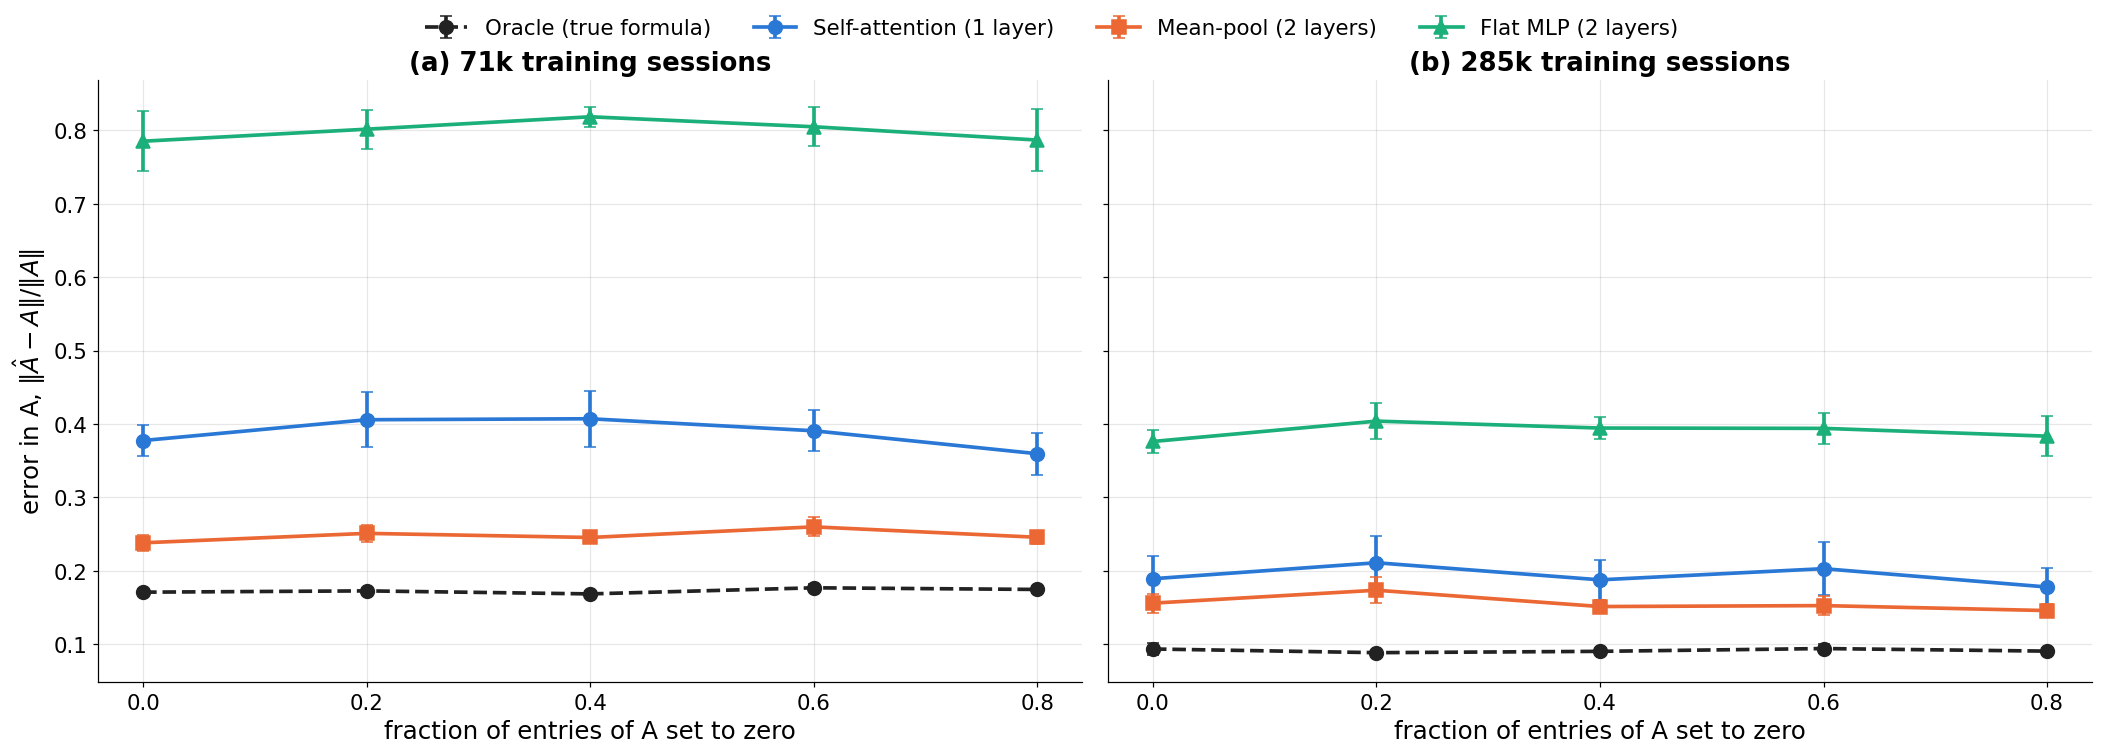

saved ./figures/ch4_sweep_sparsity.pdf
model            oracle  sa_L1  mp_L2  flat_L2
n      sparsity                               
71000  0.0        0.171  0.378  0.238    0.785
       0.2        0.173  0.406  0.251    0.802
       0.4        0.169  0.407  0.246    0.819
       0.6        0.177  0.391  0.260    0.805
       0.8        0.175  0.360  0.246    0.787
285000 0.0        0.094  0.189  0.156    0.376
       0.2        0.089  0.211  0.174    0.404
       0.4        0.090  0.188  0.151    0.395
       0.6        0.094  0.203  0.153    0.394
       0.8        0.091  0.178  0.146    0.384

error on the entries that are truly zero (as a fraction of ||A||), 285k:
model     oracle  sa_L1  mp_L2  flat_L2
sparsity                               
0.2        0.039  0.080  0.065    0.114
0.4        0.056  0.097  0.085    0.149
0.6        0.070  0.125  0.106    0.172
0.8        0.080  0.131  0.118    0.173


In [ ]:
E4s = R[R.exp == "E4_sparsity"]
M4 = ["oracle", "sa_L1", "mp_L2", "flat_L2"]
fig, ax = plt.subplots(1, 2, figsize=(19, 6.8), sharey=True)
for k, n in enumerate([71000, 285000]):
    for m in M4:
        g = summ(E4s[(E4s.model == m) & (E4s.n == n)], "sparsity", "rel_frob")
        ax[k].errorbar(g.index, g["mean"], yerr=g["ci"], marker=mk(m), color=col(m), label=label(m), capsize=4,
                       ls="--" if m == "oracle" else "-")
    ax[k].set(title=f"({'ab'[k]}) {n // 1000}k training sessions", xlabel="fraction of entries of A set to zero",
              xticks=[0, 0.2, 0.4, 0.6, 0.8])
ax[0].set_ylabel(r"error in A, $\|\hat A - A\|/\|A\|$"); top_legend(fig, ax[0])
save(fig, "ch4_sweep_sparsity")
print(E4s.pivot_table(index=["n", "sparsity"], columns="model", values="rel_frob")[M4].round(3).to_string())
print("\nerror on the entries that are truly zero (as a fraction of ||A||), 285k:")
print(E4s[(E4s.n == 285000) & (E4s.sparsity > 0)].pivot_table(index="sparsity", columns="model", values="zero_mass")[M4].round(3).to_string())


**How to read it.** Here $A$ has full rank 16, and a growing fraction of its entries is set to zero (then $A$ is rescaled to size 1).
Two data sizes.

**What it shows.** **Sparsity barely changes anything**, for any model, at either data size. The ranking (oracle, then mean-pool,
then self-attention, then flat MLP) stays the same.
That is expected: no model has anything (such as an L1 penalty) that would let it exploit zeros, and zeros do not make $A$ harder either.
The second table shows that no model produces exact zeros. On the truly-zero entries the networks carry about 1.5 to 2 times the oracle's noise.


### 4.3.4 Number of features


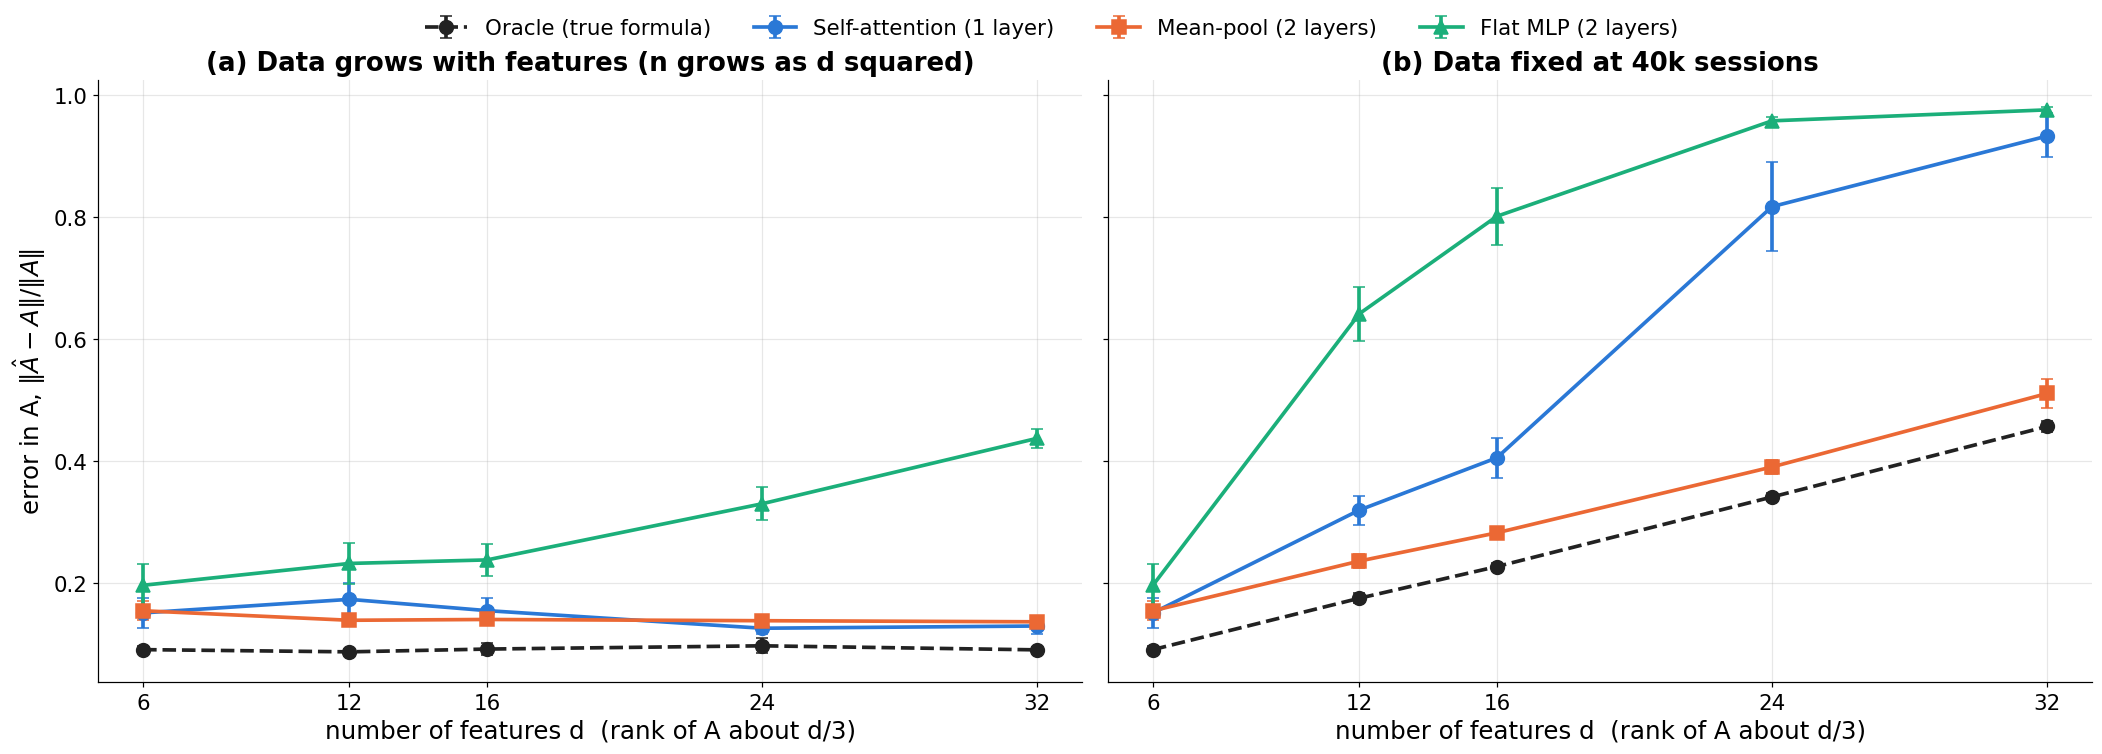

saved ./figures/ch4_sweep_features.pdf
model        oracle  sa_L1  mp_L2  flat_L2
arm      d                                
fixed40k 6    0.091  0.151  0.154    0.196
         12   0.175  0.319  0.236    0.641
         16   0.227  0.405  0.282    0.801
         24   0.341  0.817  0.390    0.958
         32   0.457  0.933  0.511    0.976
scaled   6    0.091  0.151  0.154    0.196
         12   0.087  0.173  0.139    0.232
         16   0.092  0.155  0.140    0.238
         24   0.097  0.126  0.138    0.330
         32   0.090  0.129  0.136    0.437


In [ ]:
E4f = R[(R.exp == "E4_features") & (R.world == "context")]
d6 = E4f[(E4f.d == 6)].copy(); d6["arm"] = "fixed40k"          # at 6 features both arms are the same run (40k sessions)
E4f = pd.concat([E4f, d6])
fig, ax = plt.subplots(1, 2, figsize=(19, 6.8), sharey=True)
for k, (arm, tt) in enumerate([("scaled", "(a) Data grows with features (n grows as d squared)"),
                               ("fixed40k", "(b) Data fixed at 40k sessions")]):
    for m in M4:
        g = summ(E4f[(E4f.model == m) & (E4f.arm == arm)], "d", "rel_frob")
        ax[k].errorbar(g.index, g["mean"], yerr=g["ci"], marker=mk(m), color=col(m), label=label(m), capsize=4,
                       ls="--" if m == "oracle" else "-")
    ax[k].set(title=tt, xlabel="number of features d  (rank of A about d/3)", xticks=[6, 12, 16, 24, 32])
ax[0].set_ylabel(r"error in A, $\|\hat A - A\|/\|A\|$"); top_legend(fig, ax[0])
save(fig, "ch4_sweep_features")
print(E4f.pivot_table(index=["arm", "d"], columns="model", values="rel_frob")[M4].round(3).to_string())


**How to read it.** The number of features $d$ grows from 6 to 32. $A$ has $d^2$ entries, from 36 to 1,024, and its rank is about $d/3$.
(a) The data grows in proportion to $d^2$, from 40k to 1.14M sessions, so each entry of $A$ has the same amount of data behind it.
(b) The data is fixed at 40k sessions.

**What it shows.**
* (a) With enough data, **self-attention and mean-pool keep a constant error all the way to 32 features** (0.13 to 0.17).
  Self-attention is slightly better than mean-pool at 24 and 32 features. The flat MLP gets steadily worse (0.20 to 0.44):
  its input grows as $5d$, and it has to learn the slate's symmetry on its own.
* (b) With data fixed, every model gets worse as $d$ grows, because there are more entries to estimate. Mean-pool stays close to the oracle
  (0.51 against 0.46 at 32 features). **Self-attention collapses** (0.93 at 32 features, nearly as bad as the flat MLP).
  With little data per entry, self-attention is the most data-hungry model. This matches Section 4.3.1.


### 4.3.5 Depth of the network


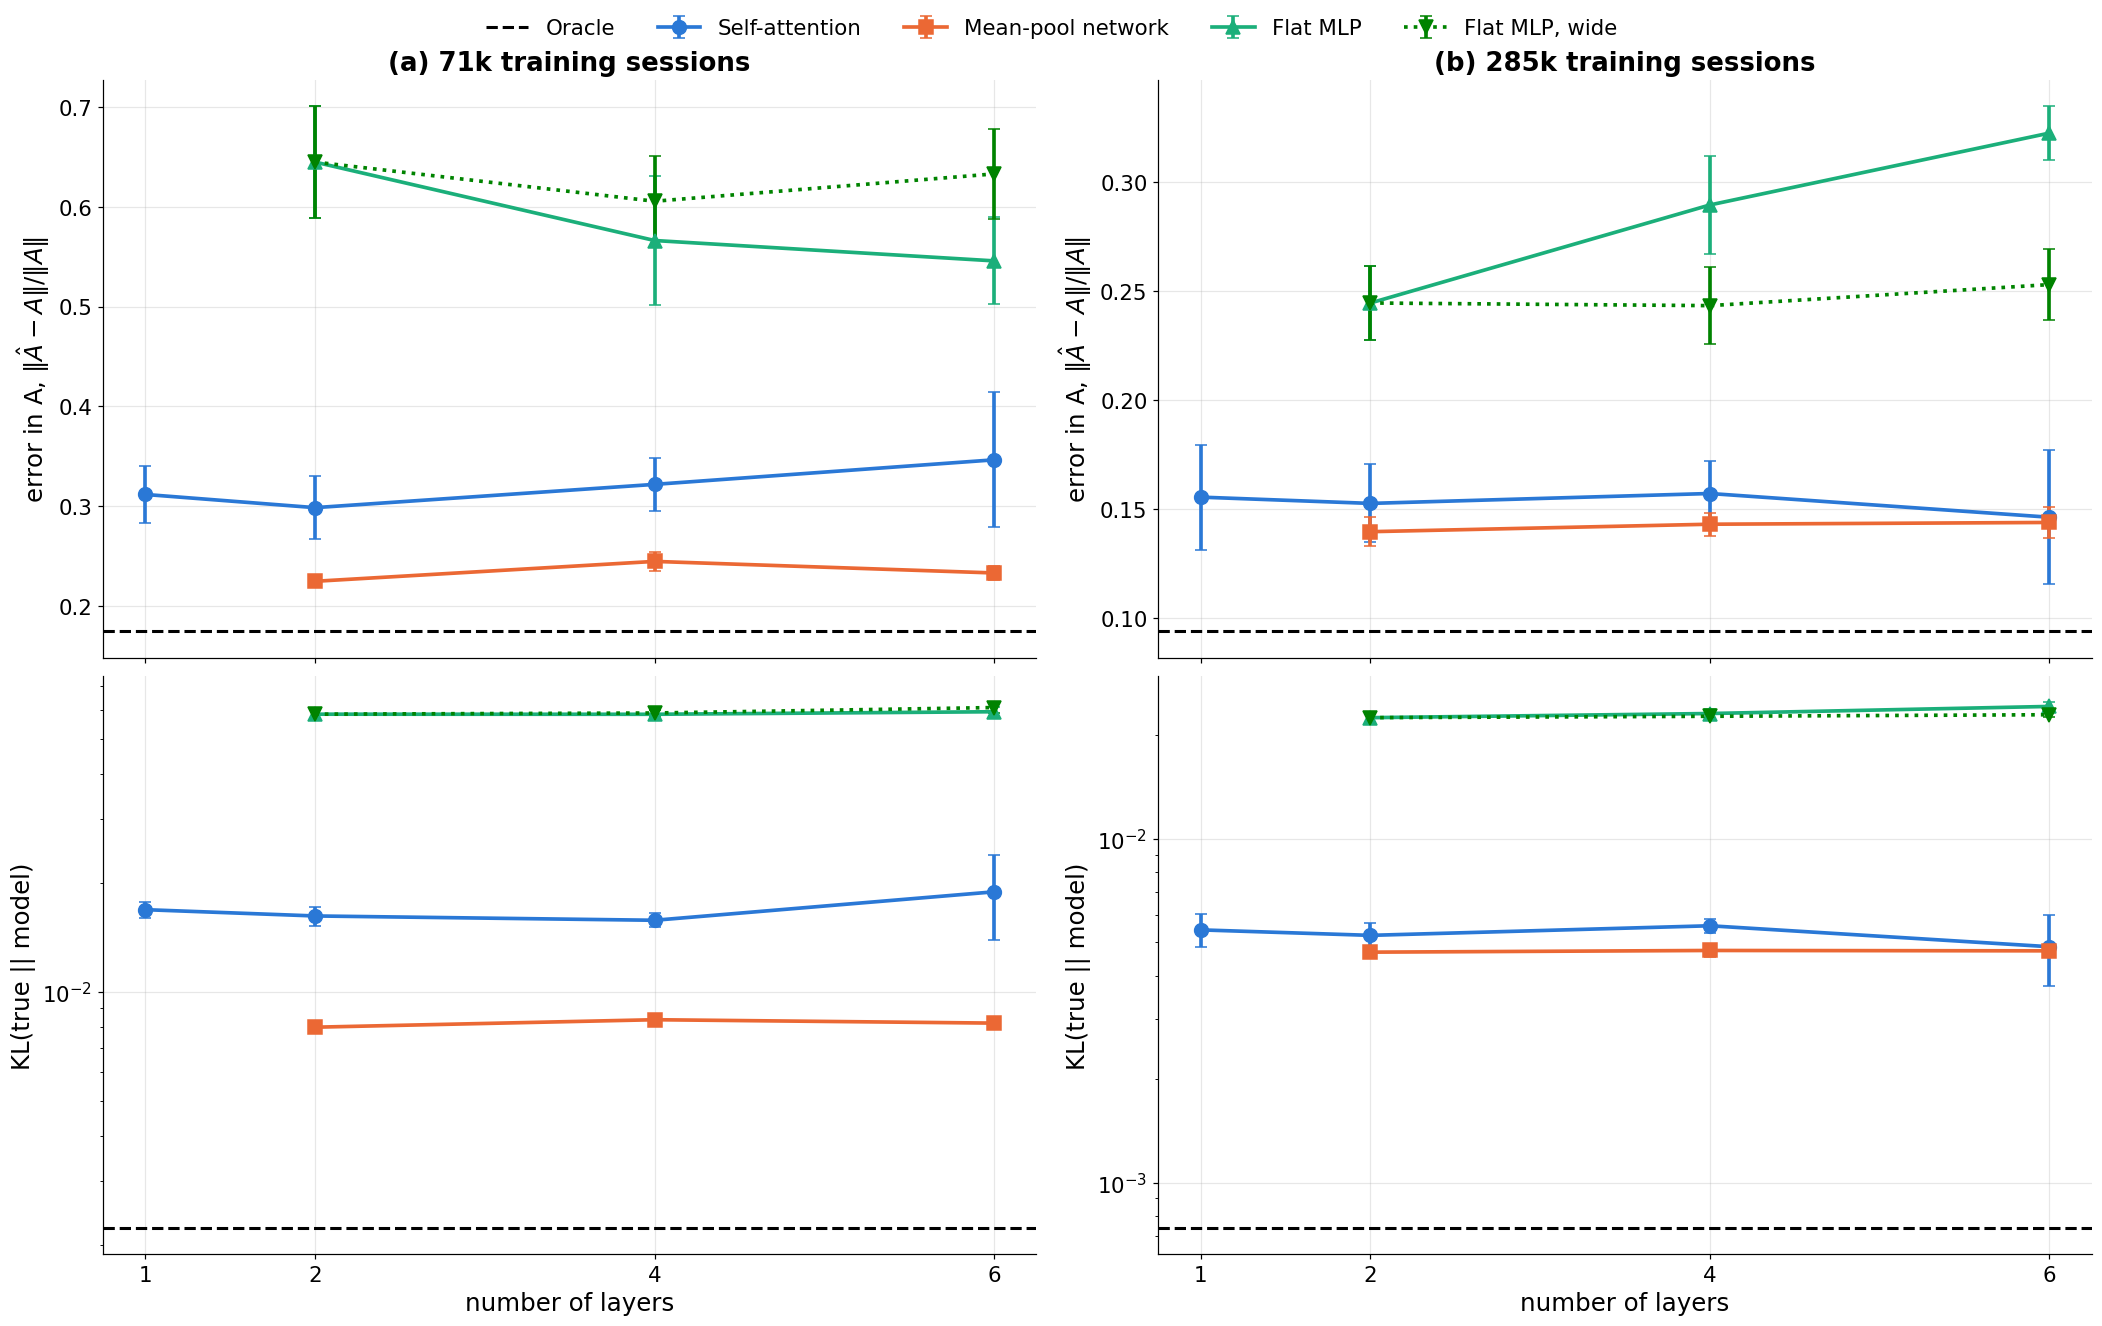

saved ./figures/ch4_sweep_depth.pdf
           kl_in         rel_frob        
n         71000   285000   71000   285000
model                                    
flat_L2   0.0584  0.0225   0.6450  0.2446
flat_L4   0.0584  0.0232   0.5663  0.2895
flat_L6   0.0593  0.0243   0.5459  0.3225
flatw_L2  0.0584  0.0225   0.6450  0.2446
flatw_L4  0.0589  0.0227   0.6057  0.2434
flatw_L6  0.0610  0.0230   0.6331  0.2530
mp_L2     0.0080  0.0047   0.2246  0.1398
mp_L4     0.0084  0.0047   0.2445  0.1432
mp_L6     0.0082  0.0047   0.2330  0.1440
oracle    0.0022  0.0007   0.1744  0.0941
sa_L1     0.0168  0.0054   0.3117  0.1556
sa_L2     0.0162  0.0052   0.2985  0.1527
sa_L4     0.0157  0.0056   0.3218  0.1573
sa_L6     0.0189  0.0049   0.3464  0.1464


In [ ]:
E5 = R[(R.exp == "E5_depth") & (R.world == "context")].copy()
E5 = pd.concat([E5, E5[E5.model == "flat_L2"].assign(model="flatw_L2")])   # the wide MLP at 2 layers IS flat_L2
E5["layers"] = E5.model.str.extract(r"_L(\d+)")[0].astype(float)
FAMS5 = ["sa", "mp", "flat", "flatw"]
fig, ax = plt.subplots(2, 2, figsize=(19, 12), sharex=True)
for k, n in enumerate([71000, 285000]):
    for r_, (val, yl) in enumerate([("rel_frob", r"error in A, $\|\hat A - A\|/\|A\|$"), ("kl_in", "KL(true || model)")]):
        a = ax[r_, k]
        for f in FAMS5:
            sub = E5[(E5.n == n) & (E5.model.map(fam) == f)]
            g = summ(sub, "layers", val)
            a.errorbar(g.index, g["mean"], yerr=g["ci"], marker=FAM[f][2], color=FAM[f][1], label=FAM[f][0], capsize=4,
                       ls=":" if f == "flatw" else "-")
        o = E5[(E5.n == n) & (E5.model == "oracle")][val].mean()
        a.axhline(o, color="black", ls="--", lw=2, label="Oracle")
        a.set(ylabel=yl, xticks=[1, 2, 4, 6])
        if r_ == 0: a.set_title(f"({'ab'[k]}) {n // 1000}k training sessions")
        if r_ == 1: a.set(xlabel="number of layers", yscale="log")
top_legend(fig, ax[0, 0], ncol=5)
save(fig, "ch4_sweep_depth")
print(E5.pivot_table(index="model", columns="n", values=["rel_frob", "kl_in"]).round(4).to_string())


**How to read it.** Top row: error in A. Bottom row: KL to the true probabilities (log scale). Left: 71k sessions. Right: 285k sessions.
The dashed black line is the oracle. "Flat MLP" keeps the parameter count of 1-layer self-attention (it gets narrower as it gets deeper).
"Flat MLP, wide" keeps the width of the 2-layer flat MLP (it gets bigger as it gets deeper).

**What it shows.**
* **Self-attention and mean-pool show no clear trend with depth** at either data size. The differences between depths are within the confidence intervals.
* **Depth does not rescue the flat MLP.** At 71k, extra layers help it a little (0.65 down to 0.55). At 285k they hurt (0.245 up to 0.32).
  The wide version is no better.
  At every depth and data size, the flat MLP stays about 1.5 to 2.5 times worse than self-attention and mean-pool.
* **Answer to "would a deeper normal MLP also learn it?": no.** What matters is the structure, not the depth:
  treating the slate as a set, and comparing each item with the rest of the slate.


### 4.3.6 Learning rate, weight decay and width


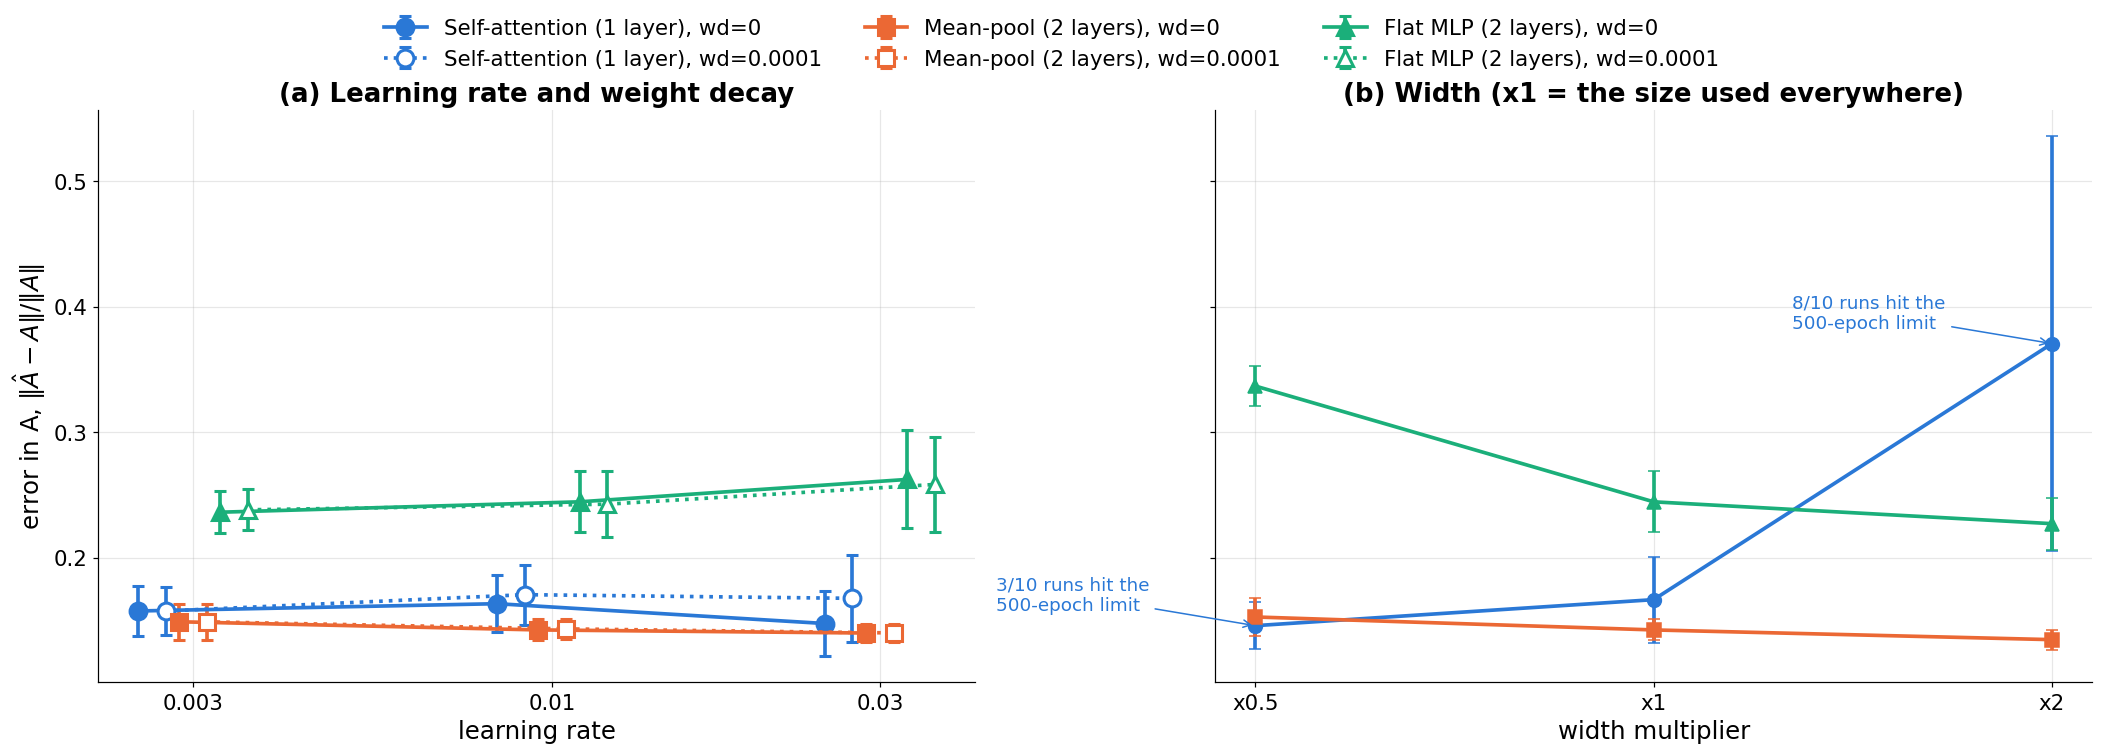

saved ./figures/ch4_sweep_optimisation.pdf
lr       0.003         0.010         0.030       
wd      0.0000 0.0001 0.0000 0.0001 0.0000 0.0001
model                                            
flat_L2  0.236  0.238  0.244  0.243  0.262  0.258
mp_L2    0.149  0.149  0.142  0.143  0.140  0.140
sa_L1    0.157  0.157  0.163  0.170  0.147  0.168
mult       0.5    1.0    2.0
base                        
flat_L2  0.337  0.244  0.227
mp_L2    0.153  0.142  0.135
sa_L1    0.146  0.167  0.370


In [ ]:
E7 = R[R.exp == "E7_hparams"]; E7w = R[R.exp == "E7_width"]
M7 = ["sa_L1", "mp_L2", "flat_L2"]
fig, ax = plt.subplots(1, 2, figsize=(19, 6.8), sharey=True)
off = {"sa_L1": -0.06, "mp_L2": 0.0, "flat_L2": 0.06}
for m in M7:
    for wd, filled in [(0.0, True), (1e-4, False)]:
        g = summ(E7[(E7.model == m) & (E7.wd == wd)], "lr", "rel_frob")
        x = np.log10(g.index) + off[m] + (0.02 if not filled else -0.02)
        ax[0].errorbar(x, g["mean"], yerr=g["ci"], marker=mk(m), color=col(m), ms=11, capsize=4, ls="-" if filled else ":",
                       mfc=col(m) if filled else "white", mec=col(m), mew=2, label=f"{label(m)}, wd={wd:g}")
ax[0].set_xticks(np.log10([0.003, 0.01, 0.03]), ["0.003", "0.01", "0.03"])
ax[0].set(title="(a) Learning rate and weight decay", xlabel="learning rate", ylabel=r"error in A, $\|\hat A - A\|/\|A\|$")
top_legend(fig, ax[0], ncol=3)
E1w = E1[(E1.world == "context") & E1.model.isin(M7) & E1.seed.isin(E7w.seed.unique())].copy()   # width x1 = the headline runs
W = pd.concat([E7w.assign(mult=E7w.model.str.split("_x").str[1].astype(float), base=E7w.model.str.split("_x").str[0]),
               E1w.assign(mult=1.0, base=E1w.model)])
for m in M7:
    g = summ(W[W.base == m], "mult", "rel_frob")
    ax[1].errorbar(g.index, g["mean"], yerr=g["ci"], marker=mk(m), color=col(m), capsize=4, label=label(m))
    hits = W[W.base == m].groupby("mult").budget_hit.sum()
    for x_, nh in hits.items():
        if nh >= 3: ax[1].annotate(f"{int(nh)}/10 runs hit the\n500-epoch limit", (x_, g.loc[x_, "mean"]), xytext=(-170, 10),
                                   textcoords="offset points", fontsize=12, color=col(m), arrowprops=dict(arrowstyle="->", color=col(m)))
ax[1].set(xscale="log", xticks=[0.5, 1, 2], title="(b) Width (x1 = the size used everywhere)", xlabel="width multiplier")
ax[1].set_xticklabels(["x0.5", "x1", "x2"]); ax[1].minorticks_off()
save(fig, "ch4_sweep_optimisation")
print(E7.pivot_table(index="model", columns=["lr", "wd"], values="rel_frob").round(3).to_string())
print(W.pivot_table(index="base", columns="mult", values="rel_frob").round(3).to_string())


**How to read it.** (a) All 6 combinations of learning rate and weight decay, 10 datasets each. Filled markers have no weight decay;
hollow markers have weight decay 0.0001. (b) Half-width and double-width versions of each network, 10 datasets each.
The x1 point is the same 10 datasets from the headline run.

**What it shows.**
* (a) **The conclusions do not depend on the learning rate.** Across the whole grid, self-attention stays at 0.15 to 0.17, mean-pool at 0.14 to 0.15,
  and the flat MLP at 0.24 to 0.26. The spread from hyperparameters (at most 0.02) is much smaller than the gap between architectures
  (about 0.09 to the flat MLP), and the ranking never changes.
* (b) Mean-pool improves a little with width (0.153 down to 0.135). The flat MLP improves a lot (0.34 down to 0.23) but still stays behind.
  **Self-attention at double width is not a real result:** 8 of its 10 runs were still improving when they hit the 500-epoch limit, so it was not
  trained to the end. Half-width self-attention is as good as the standard one.
  Settling the double-width case needs a longer run.


### 4.3.7 Random initialisation


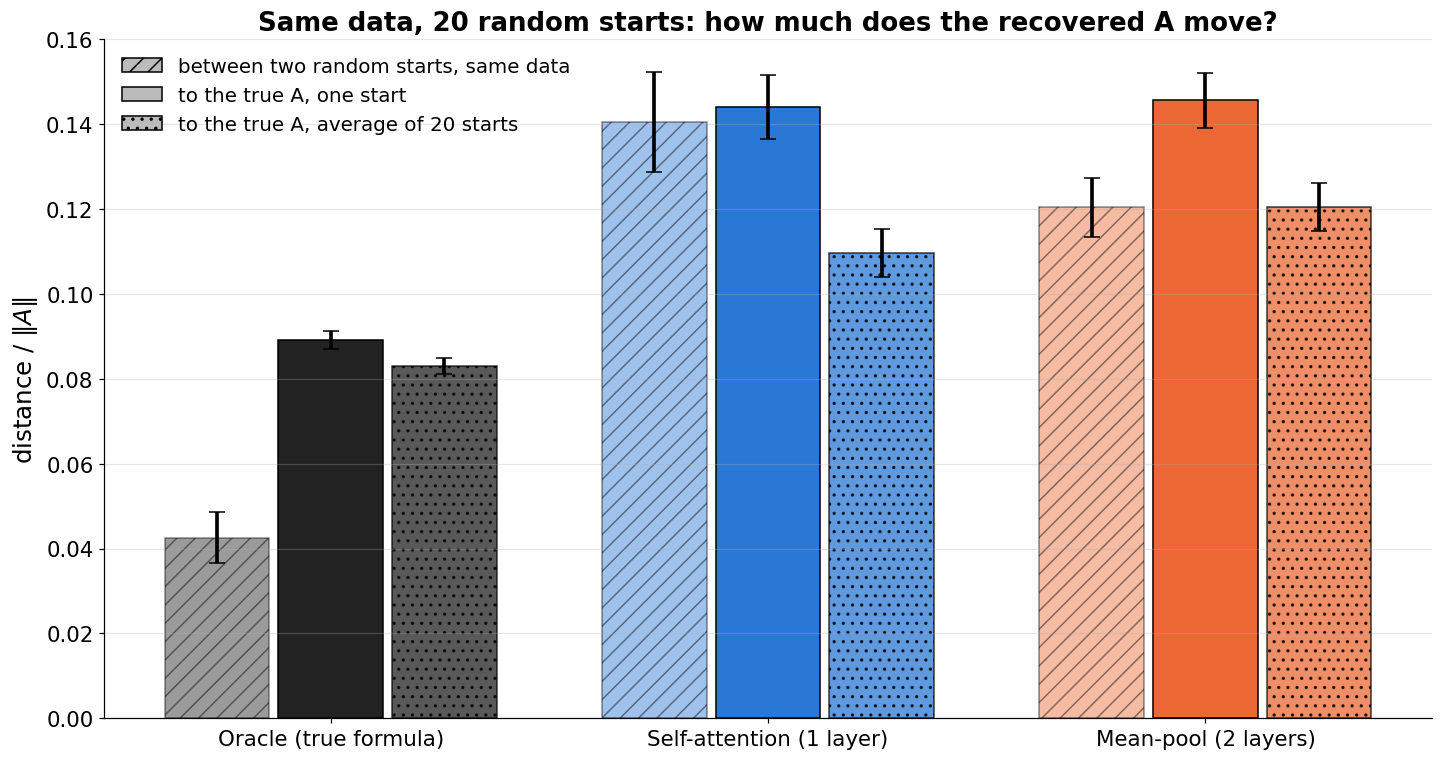

saved ./figures/ch4_sweep_initialisation.pdf
        init_to_init  to_truth  mean_to_truth
model                                        
oracle         0.043     0.089          0.083
sa_L1          0.141     0.144          0.110
mp_L2          0.120     0.146          0.120


In [ ]:
E6 = R[R.exp == "E6_identification"]
M6 = ["oracle", "sa_L1", "mp_L2"]
rows6 = []
for m in M6:
    for ds, g in E6[E6.model == m].groupby("seed"):
        Ah = np.stack([A_of(r) for _, r in g.iterrows()])
        A_true = L.make_ground_truth(16, 5, int(ds))[1]
        nA = np.linalg.norm(A_true)
        i, j = np.triu_indices(len(Ah), 1)
        rows6.append(dict(model=m, dataset=ds,
                          init_to_init=np.mean(np.linalg.norm(Ah[i] - Ah[j], axis=(1, 2))) / nA,     # same data, different start
                          to_truth=np.mean(np.linalg.norm(Ah - A_true, axis=(1, 2))) / nA,
                          mean_to_truth=np.linalg.norm(Ah.mean(0) - A_true) / nA))                  # average over the 20 starts
T6 = pd.DataFrame(rows6)
fig, ax = plt.subplots(figsize=(13, 6.8))
xs = np.arange(len(M6)); w = 0.26
for k, (val, tt, hatch) in enumerate([("init_to_init", "difference between two random starts", "//"),
                                      ("to_truth", "error to the true A (one start)", ""),
                                      ("mean_to_truth", "error to the true A (average of 20 starts)", "..")]):
    g = summ(T6, "model", val).loc[M6]
    ax.bar(xs + (k - 1) * w, g["mean"], w * 0.92, yerr=g["ci"], capsize=5, color=[col(m) for m in M6],
           edgecolor="black", hatch=hatch, alpha=[0.45, 1.0, 0.75][k], label=tt)
ax.set_xticks(xs, [label(m) for m in M6])
ax.set(ylabel=r"distance / $\|A\|$", title="Same data, 20 random starts: how much does the recovered A move?")
ax.grid(axis="x", visible=False)
ax.legend(handles=[mpl.patches.Patch(facecolor="#bbbbbb", edgecolor="black", hatch=h, label=t)
                   for h, t in [("//", "between two random starts, same data"), ("", "to the true A, one start"),
                                ("..", "to the true A, average of 20 starts")]], loc="upper left")
save(fig, "ch4_sweep_initialisation")
print(T6.groupby("model")[["init_to_init", "to_truth", "mean_to_truth"]].mean().loc[M6].round(3).to_string())


**How to read it.** The same 10 datasets, each trained 20 times from different random starting weights (200 trainings per model).
* Hatched bars: the average distance between the $\hat A$ of two different starts on the same data.
* Solid bars: the average distance of one start's $\hat A$ to the true $A$.
* Dotted bars: the distance of the *average* of the 20 $\hat A$'s to the true $A$.

**What it shows.**
* **The oracle:** two starts differ by only 0.04, far less than its error to the truth (0.09). Its error comes almost entirely from the limited data.
  The small spread between starts appears because early stopping halts before the exact optimum.
* **Self-attention:** two starts differ by 0.14, **as much as either differs from the truth** (0.14). So a large part of self-attention's error
  comes from the random start (optimisation), not from the data or the architecture.
  Averaging the 20 starts cuts its error from 0.14 to 0.11, below mean-pool's averaged error (0.12).
* **Mean-pool** shows the same pattern, more weakly: 0.12 between starts, an error of 0.15, and 0.12 after averaging.
* **Implication:** part of the gap between self-attention and the oracle can be removed by averaging several trained models.
  It is not a limit of what self-attention can represent.


---
## 4.4 Recovery of the preference vector $\theta$

The same sweeps as Section 4.3, now for $\hat\theta$. Measure: relative error $\lVert\hat\theta - \theta\rVert / \lVert\theta\rVert$
(0 is perfect).


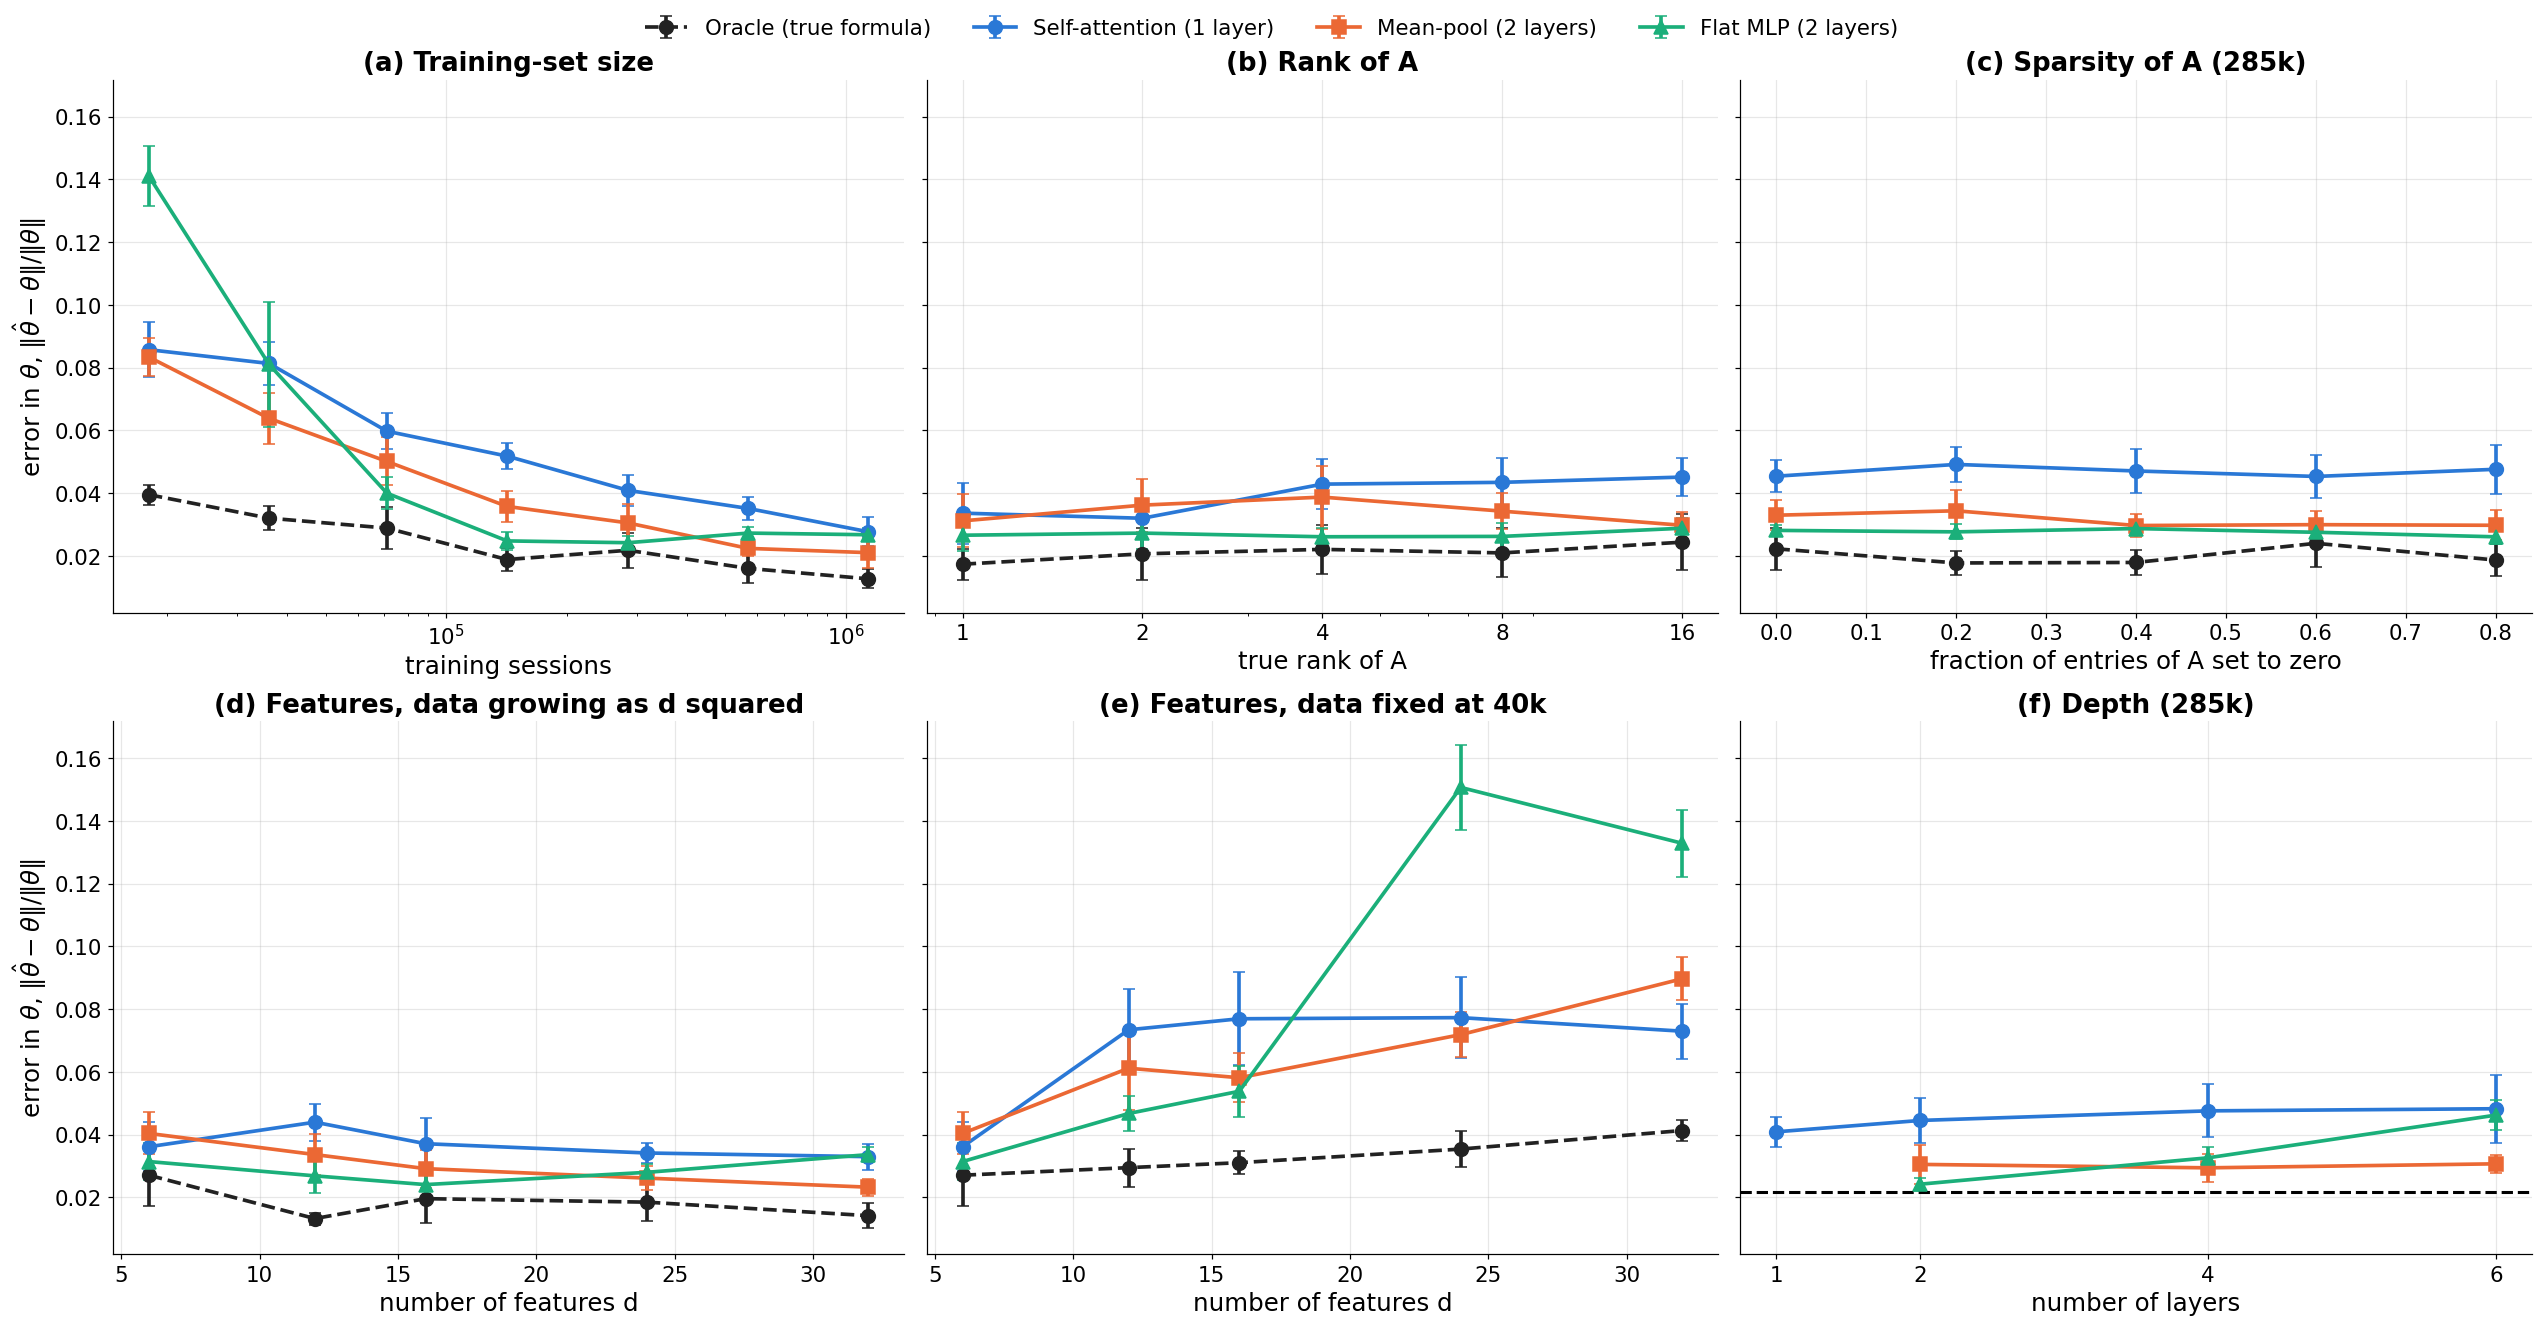

saved ./figures/ch4_theta_sweeps.pdf
model    oracle  sa_L1  mp_L2  flat_L2
n                                     
18000     0.040  0.086  0.083    0.141
36000     0.032  0.081  0.064    0.081
71000     0.029  0.060  0.050    0.040
142000    0.019  0.052  0.036    0.025
285000    0.022  0.041  0.031    0.024
570000    0.016  0.035  0.022    0.027
1140000   0.013  0.028  0.021    0.027
model        oracle  sa_L1  mp_L2  flat_L2
arm      d                                
fixed40k 12   0.029  0.073  0.061    0.047
         16   0.031  0.077  0.058    0.054
         24   0.035  0.077  0.072    0.151
         32   0.041  0.073  0.090    0.133
scaled   6    0.027  0.036  0.040    0.031
         12   0.013  0.044  0.034    0.027
         16   0.020  0.037  0.029    0.024
         24   0.018  0.034  0.026    0.028
         32   0.014  0.033  0.023    0.034


In [ ]:
CT = R[R.world == "context"]
M4 = ["oracle", "sa_L1", "mp_L2", "flat_L2"]
def line(ax, df, x, models, logx=False):
    for m in models:
        g_ = summ(df[df.model == m], x, "theta_relerr")
        ax.errorbar(g_.index, g_["mean"], yerr=g_["ci"], marker=mk(m), color=col(m), label=label(m), capsize=4,
                    ls="--" if m == "oracle" else "-")
    if logx: ax.set_xscale("log")
fig, axs = plt.subplots(2, 3, figsize=(23, 12), sharey=True)
line(axs[0, 0], CT[CT.exp == "E2_datasize"], "n", M4, logx=True); axs[0, 0].set(title="(a) Training-set size", xlabel="training sessions")
line(axs[0, 1], CT[CT.exp == "E3_rank"], "rank", M4); axs[0, 1].set(title="(b) Rank of A", xlabel="true rank of A", xscale="log",
                                                                  xticks=[1, 2, 4, 8, 16]); axs[0, 1].set_xticklabels([1, 2, 4, 8, 16])
line(axs[0, 2], CT[(CT.exp == "E4_sparsity") & (CT.n == 285000)], "sparsity", M4)
axs[0, 2].set(title="(c) Sparsity of A (285k)", xlabel="fraction of entries of A set to zero")
F_ = CT[CT.exp == "E4_features"]
line(axs[1, 0], F_[F_.arm == "scaled"], "d", M4); axs[1, 0].set(title="(d) Features, data growing as d squared", xlabel="number of features d")
F6 = F_[F_.d == 6].assign(arm="fixed40k")
line(axs[1, 1], pd.concat([F_[F_.arm == "fixed40k"], F6]), "d", M4)
axs[1, 1].set(title="(e) Features, data fixed at 40k", xlabel="number of features d")
D5 = CT[(CT.exp == "E5_depth") & (CT.n == 285000)].copy(); D5["layers"] = D5.model.str.extract(r"_L(\d+)")[0].astype(float)
for f in ["sa", "mp", "flat"]:
    g_ = summ(D5[D5.model.map(fam) == f], "layers", "theta_relerr")
    axs[1, 2].errorbar(g_.index, g_["mean"], yerr=g_["ci"], marker=FAM[f][2], color=FAM[f][1], capsize=4, label=FAM[f][0])
axs[1, 2].axhline(D5[D5.model == "oracle"].theta_relerr.mean(), color="black", ls="--", lw=2)
axs[1, 2].set(title="(f) Depth (285k)", xlabel="number of layers", xticks=[1, 2, 4, 6])
for a in axs[:, 0]: a.set_ylabel(r"error in $\theta$, $\|\hat\theta - \theta\|/\|\theta\|$")
top_legend(fig, axs[0, 0], ncol=4)
save(fig, "ch4_theta_sweeps")
print(CT[CT.exp == "E2_datasize"].pivot_table(index="n", columns="model", values="theta_relerr")[M4].round(3).to_string())
print(F_.pivot_table(index=["arm", "d"], columns="model", values="theta_relerr")[M4].round(3).to_string())


**How to read it.** Same layout as the sweeps in Section 4.3, but the vertical axis is the relative error in $\hat\theta$.

**What it shows.**
* **$\theta$ is the easy part.** At the reference setting every model recovers it within about 2 to 5%, including the flat MLP,
  which recovers $A$ worst.
* **More data helps every model** (panel a). At the largest size the oracle reaches about 1%, mean-pool and the flat MLP about 2 to 3%,
  and self-attention about 3%. Self-attention has the largest $\theta$ error at large data, the reverse of its ranking for $A$.
* **Rank and sparsity of $A$ do not affect $\theta$** (panels b, c).
* **With data fixed at 40k**, the flat MLP's $\theta$ error grows sharply above 16 features (panel e); the structured models stay below about 9%.
* **Depth** changes $\theta$ little for self-attention and mean-pool; the 6-layer flat MLP is slightly worse (panel f).


---
## 4.5 Behaviour on shifted choice sets (RQ3)

The shifted set keeps the 5% of 100,000 random slates whose average $y_S$ is furthest from 0. These slates are rare in training,
and on them the context term is larger than usual.


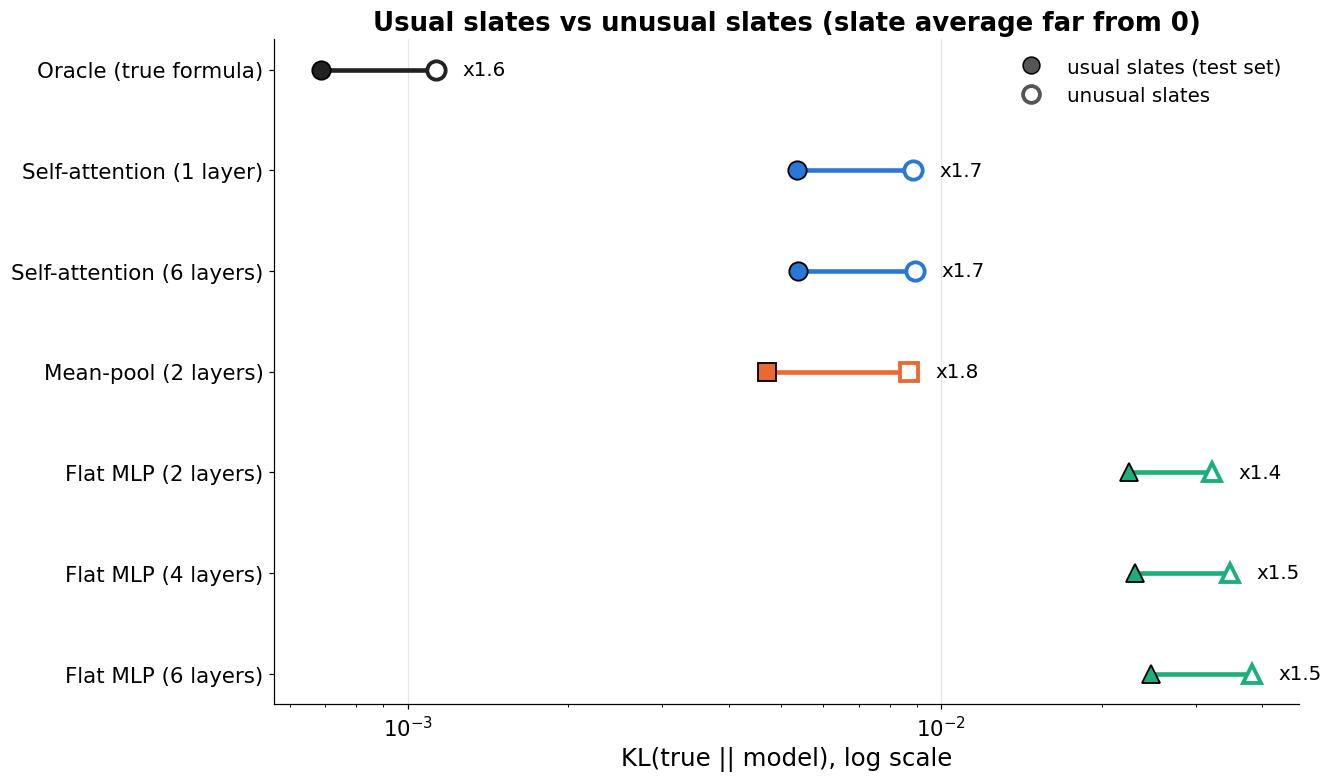

saved ./figures/ch4_shift_kl.pdf


In [ ]:
fig, ax = plt.subplots(figsize=(12, 7))
g_in, g_sh = summ(ctx, "model", "kl_in"), summ(ctx, "model", "kl_shift")
for i, m in enumerate(ORDER_E1):
    a, b = g_in.loc[m, "mean"], g_sh.loc[m, "mean"]
    ax.plot([a, b], [i, i], color=col(m), lw=3)
    ax.plot(a, i, marker=mk(m), color=col(m), ms=12, mec="black", mew=1.2, ls="")
    ax.plot(b, i, marker=mk(m), color="white", ms=12, mec=col(m), mew=2.5, ls="")
    ax.text(b * 1.12, i, f"x{b / a:.1f}", va="center", fontsize=13)
ax.set_yticks(range(len(ORDER_E1)), [label(m) for m in ORDER_E1]); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xscale("log")
ax.set(xlabel="KL(true || model), log scale", title="Usual slates vs unusual slates (slate average far from 0)")
ax.legend(handles=[Line2D([], [], marker="o", color="#555", mec="black", ls="", ms=11, label="usual slates (test set)"),
                   Line2D([], [], marker="o", color="white", mec="#555", mew=2.5, ls="", ms=11, label="unusual slates")],
          loc="upper right")
save(fig, "ch4_shift_kl")


**How to read it.** Filled marker: KL on the normal test set. Hollow marker: KL on *unusual* slates, whose slate average lies far
from the usual training data (the 5% most extreme of many random slates). The number is how many times worse the unusual slates are.

**What it shows.** Every model is worse on unusual slates, **including the oracle (1.6 times)**. That part is not a flaw of
any architecture: estimating anything far from where the data lies is harder.
Self-attention and mean-pool degrade about as much as the oracle (1.7 to 1.8 times). So there is no sign that they learned a rule
that only works on typical slates. The flat MLP's ratio is smaller (1.4 to 1.5 times), but it starts from a level about 4 times worse.


sa_L1: partial correlation 0.73, slope 0.33, raw correlation 0.89, mean KL shift/KL test 1.65
mp_L2: partial correlation 0.77, slope 0.36, raw correlation 0.91, mean KL shift/KL test 1.89


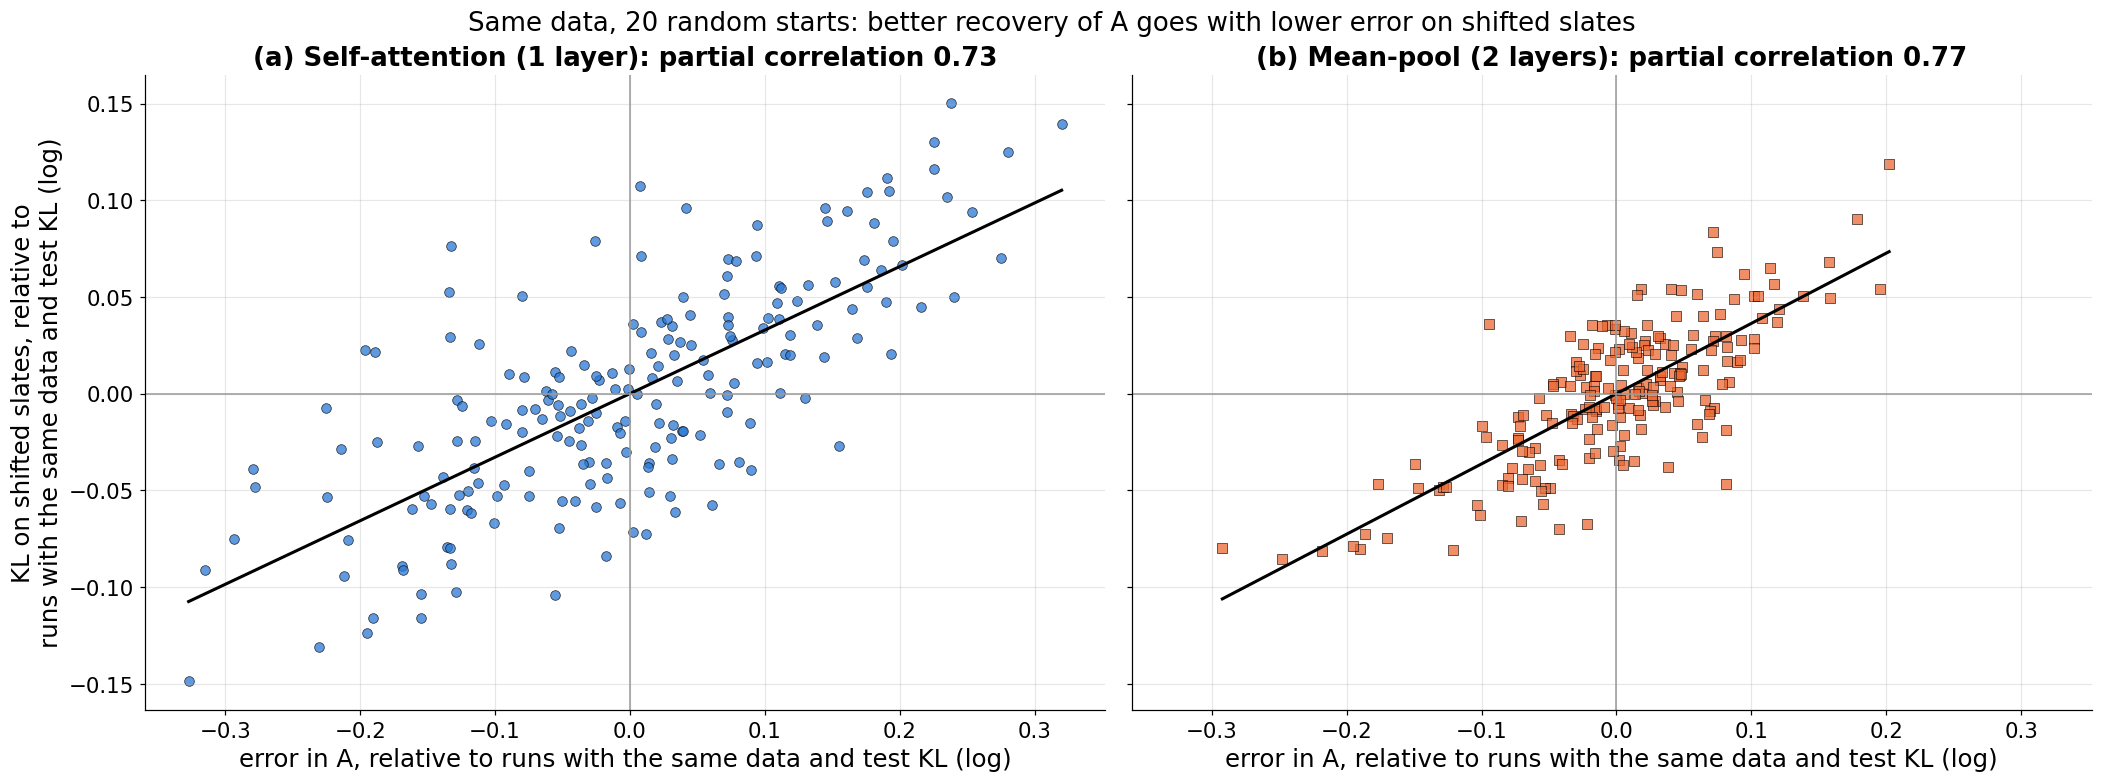

saved ./figures/ch4_shift_recovery.pdf


In [ ]:
# Same data, 20 random starts (E6): do runs that recover A better also do better on shifted slates,
# once their in-distribution KL is accounted for?
E6 = R[R.exp == "E6_identification"]
fig, axs = plt.subplots(1, 2, figsize=(19, 7), sharey=True, sharex=True)
for ax, m in zip(axs, ["sa_L1", "mp_L2"]):
    x = E6[E6.model == m]
    Z = np.c_[pd.get_dummies(x.seed).values.astype(float), np.log(x.kl_in.values)]   # dataset + in-distribution KL
    res = lambda v: v - Z @ np.linalg.lstsq(Z, v, rcond=None)[0]
    a_, b_ = res(np.log(x.rel_frob.values)), res(np.log(x.kl_shift.values))
    r_ = np.corrcoef(a_, b_)[0, 1]; k_, c_ = np.polyfit(a_, b_, 1)
    ax.scatter(a_, b_, s=40, marker=mk(m), color=col(m), edgecolor="black", lw=0.5, alpha=0.75)
    xx = np.linspace(a_.min(), a_.max(), 10); ax.plot(xx, k_ * xx + c_, color="black", lw=2)
    ax.set(title=f"({'ab'[m == 'mp_L2']}) {label(m)}: partial correlation {r_:.2f}",
           xlabel="error in A, relative to runs with the same data and test KL (log)")
    ax.axhline(0, color="#999", lw=1); ax.axvline(0, color="#999", lw=1)
    print(f"{m}: partial correlation {r_:.2f}, slope {k_:.2f}, raw correlation "
          f"{np.corrcoef(np.log(x.rel_frob), np.log(x.kl_shift))[0, 1]:.2f}, mean KL shift/KL test {np.mean(x.kl_shift / x.kl_in):.2f}")
axs[0].set_ylabel("KL on shifted slates, relative to\nruns with the same data and test KL (log)")
fig.suptitle("Same data, 20 random starts: better recovery of A goes with lower error on shifted slates", fontsize=17)
save(fig, "ch4_shift_recovery")


**How to read it.** Experiment E6 trains self-attention and mean-pool 20 times on each of 10 datasets, changing only the random start.
Both axes remove what is explained by the dataset and by the run's in-distribution KL (an added-variable plot).
A point to the right recovered $A$ worse than runs with the same data and the same test KL; a point higher up did worse on shifted slates.

**What it shows.** Among runs that fit the usual test set equally well, the ones that recovered $A$ better also predict the shifted slates better:
partial correlation 0.73 for self-attention and 0.77 for mean-pool. So recovery carries information about behaviour under shift that
in-distribution fit does not. The effect is moderate (the in-distribution KL already explains most of the shifted KL), and the shift
here is mild, since the shifted slates are still drawn from the same Gaussian.


---
## 4.7 Summary of findings


* **RQ1.** Prediction and recovery go together across architectures. Self-attention recovers $A$ with the right pattern (cosine 0.99) at 93% of its true strength
  and does not invent context effects. **Mean-pool does about as well as self-attention at 285k sessions;** the clear gap is to the flat MLP.
* **RQ2.** Data size, the rank of $A$ and the number of features drive recovery; sparsity, depth, learning rate and weight decay do not (double-width self-attention is unconverged).
  About half of self-attention's remaining error comes from the random start.
* **RQ3.** Among runs that fit the usual data equally well, better recovery goes with better predictions on shifted slates.


In [ ]:
print("figures saved in", os.path.abspath(FIG))
for f in sorted(os.listdir(FIG)): print("  ", f)


figures saved in /content/figures
   ch3_data_ground_truth.pdf
   ch3_tuning.pdf
   ch4_A_heatmaps.pdf
   ch4_accuracy.pdf
   ch4_accuracy_vs_recovery.pdf
   ch4_false_positive.pdf
   ch4_lcl_shape.pdf
   ch4_prediction.pdf
   ch4_recovery.pdf
   ch4_shift_kl.pdf
   ch4_shift_recovery.pdf
   ch4_sweep_datasize.pdf
   ch4_sweep_depth.pdf
   ch4_sweep_features.pdf
   ch4_sweep_initialisation.pdf
   ch4_sweep_optimisation.pdf
   ch4_sweep_rank.pdf
   ch4_sweep_sparsity.pdf
   ch4_theta_sweeps.pdf
   ch4_training_curves.pdf
   ch4_training_curves_all.pdf
   ch4_training_curves_depth.pdf
   extra_probe_checks.pdf
   extra_rank_heads.pdf
